<a href="https://colab.research.google.com/github/Hoor-Fayaz/RehabIQ/blob/main/Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

# Updated to use the successful mount point '/content/gdrive'
ROOT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
)

REPORT_DIR = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

inventory = []
errors = []

npz_files = list(ROOT.rglob("*.npz"))

print("TOTAL NPZ FILES FOUND:", len(npz_files))

for file_path in npz_files:

    relative_path = file_path.relative_to(ROOT)
    parts = relative_path.parts

    try:
        with np.load(file_path, allow_pickle=True) as data:

            keys = list(data.files)

            pose17_shape = (
                data["pose_17"].shape
                if "pose_17" in keys else None
            )

            pose33_shape = (
                data["pose_33"].shape
                if "pose_33" in keys else None
            )

            pose17_dtype = (
                str(data["pose_17"].dtype)
                if "pose_17" in keys else None
            )

            pose33_dtype = (
                str(data["pose_33"].dtype)
                if "pose_33" in keys else None
            )

            # Extract available metadata safely
            metadata = {}

            for key in [
                "dataset", "exercise_name", "exercise_id",
                "participant", "video_id", "camera",
                "fps", "frame_count", "correctness"
            ]:
                if key in keys:
                    value = data[key]
                    if value.size == 1:
                        metadata[key] = str(value.item())
                    else:
                        metadata[key] = "ARRAY"

            inventory.append({
                "relative_path": str(relative_path),
                "top_folder": parts[0] if len(parts) else "",
                "subfolder": parts[1] if len(parts) > 1 else "",
                "filename": file_path.name,
                "file_size_MB": round(
                    file_path.stat().st_size / (1024**2), 3
                ),
                "keys": ", ".join(keys),
                "pose17_shape": str(pose17_shape),
                "pose33_shape": str(pose33_shape),
                "pose17_dtype": pose17_dtype,
                "pose33_dtype": pose33_dtype,
                "metadata": str(metadata),
                "read_status": "READABLE"
            })

    except Exception as e:
        errors.append({
            "path": str(file_path),
            "error": str(e)
        })

        inventory.append({
            "relative_path": str(relative_path),
            "top_folder": parts[0] if len(parts) else "",
            "subfolder": parts[1] if len(parts) > 1 else "",
            "filename": file_path.name,
            "file_size_MB": None,
            "keys": None,
            "pose17_shape": None,
            "pose33_shape": None,
            "pose17_dtype": None,
            "pose33_dtype": None,
            "metadata": None,
            "read_status": "FAILED"
        })

df = pd.DataFrame(inventory)

inventory_path = REPORT_DIR / "RehabIQ_Master_Landmark_Inventory.csv"
errors_path = REPORT_DIR / "RehabIQ_NPZ_Read_Errors.csv"

if not df.empty:
    df.to_csv(inventory_path, index=False)
    pd.DataFrame(errors).to_csv(errors_path, index=False)

    print("\n========== MASTER INVENTORY ==========")
    print("Total NPZ files:", len(df))
    print("Readable:", (df["read_status"] == "READABLE").sum())
    print("Unreadable:", (df["read_status"] == "FAILED").sum())

    print("\nNPZ FILES BY TOP-LEVEL FOLDER:")
    print(df.groupby("top_folder").size().to_string())

    print("\nAVAILABLE ARRAY STRUCTURES:")
    print(df.groupby(
        ["pose17_shape", "pose33_shape"],
        dropna=False
    ).size().to_string())

    print("\nFILE COUNTS BY TOP-LEVEL FOLDER AND SUBFOLDER:")
    print(
        df.groupby(["top_folder", "subfolder"]
        ).size().to_string()
    )

    print("\nMASTER INVENTORY SAVED:")
    print(inventory_path)

    print("\nERROR REPORT SAVED:")
    print(errors_path)
else:
    print("\n========== MASTER INVENTORY ==========")
    print("No NPZ files found to analyze or process.")

TOTAL NPZ FILES FOUND: 2471


KeyboardInterrupt: 

In [5]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive to an alternative folder /content/gdrive to avoid conflicts
drive.mount("/content/gdrive", force_remount=True)

# Check expected locations with the new mount point
paths = [
    Path("/content/gdrive/MyDrive"),
    Path("/content/gdrive/MyDrive/RehabIQ_Dataset"),
    Path("/content/gdrive/MyDrive/RehabIQ_Dataset/processed")
]

print("\n========== GOOGLE DRIVE DIAGNOSTIC ==========")

for path in paths:
    print(f"\nPath: {path}")
    print("Exists:", path.exists())
    print("Is directory:", path.is_dir())

    if path.exists() and path.is_dir():
        print("Contents:")
        for item in sorted(path.iterdir()):
            print("  ", item.name, "[FOLDER]" if item.is_dir() else "[FILE]")

# Locate exercise folders
processed = paths[-1]

if processed.exists():
    print("\n========== EXERCISE FOLDERS ==========")

    for folder in sorted(processed.iterdir()):
        if folder.is_dir():
            count = sum(1 for _ in folder.rglob("*.npz"))
            print(f"{folder.name}: {count} NPZ files")

Mounted at /content/gdrive

========== GOOGLE DRIVE DIAGNOSTIC ==========

Path: /content/gdrive/MyDrive
Exists: True
Is directory: True
Contents:
   AI ML Bootcamp - Feedback Form.gform [FILE]
   ASL_Hand_Landmarks [FOLDER]
   Colab Notebooks [FOLDER]
   KiMoRe_rgb [FOLDER]
   RehabIQ_Dataset [FOLDER]
   data_communication_videos [FOLDER]

Path: /content/gdrive/MyDrive/RehabIQ_Dataset
Exists: True
Is directory: True
Contents:
   metadata [FOLDER]
   models [FOLDER]
   organized_by_exercise [FOLDER]
   processed [FOLDER]

Path: /content/gdrive/MyDrive/RehabIQ_Dataset/processed
Exists: True
Is directory: True
Contents:
   Arm_Raising [FOLDER]
   Forward_Lunge [FOLDER]
   Hip_Flexion [FOLDER]
   Leg_Abduction [FOLDER]
   Lumbar_Flexion [FOLDER]
   Seated_Leg_Raise [FOLDER]
   Shoulder_Abduction [FOLDER]
   Shoulder_Circumduction [FOLDER]
   Shoulder_External_Rotation [FOLDER]
   Squat [FOLDER]
   Trunk_Lateral_Bending [FOLDER]
   Trunk_Rotation [FOLDER]

========== EXERCISE FOLDERS =====

In [7]:

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
)

REPORT_DIR = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

inventory = []
errors = []

exercise_folders = sorted(
    [p for p in ROOT.iterdir() if p.is_dir()]
)

print("Exercise folders:", len(exercise_folders))

for exercise_folder in exercise_folders:

    files = sorted(exercise_folder.rglob("*.npz"))

    for file_path in files:

        try:
            with np.load(file_path, allow_pickle=True) as data:

                keys = list(data.files)

                def get_shape(key):
                    return str(data[key].shape) if key in keys else None

                def get_metadata(key):
                    if key not in keys:
                        return None
                    value = data[key]
                    return str(value.item()) if value.size == 1 else "ARRAY"

                inventory.append({
                    "exercise_folder": exercise_folder.name,
                    "relative_path": str(file_path.relative_to(ROOT)),
                    "filename": file_path.name,
                    "file_size_MB": round(
                        file_path.stat().st_size / (1024**2), 3
                    ),
                    "keys": ", ".join(keys),
                    "pose17_shape": get_shape("pose_17"),
                    "pose33_shape": get_shape("pose_33"),
                    "detected_shape": get_shape("detected"),
                    "dataset": get_metadata("dataset"),
                    "exercise_id": get_metadata("exercise_id"),
                    "participant": get_metadata("participant"),
                    "video_id": get_metadata("video_id"),
                    "camera": get_metadata("camera"),
                    "fps": get_metadata("fps"),
                    "correctness": get_metadata("correctness"),
                    "read_status": "READABLE"
                })

        except Exception as e:
            errors.append({
                "file": str(file_path),
                "error": str(e)
            })

            inventory.append({
                "exercise_folder": exercise_folder.name,
                "relative_path": str(file_path.relative_to(ROOT)),
                "filename": file_path.name,
                "read_status": "FAILED"
            })

df = pd.DataFrame(inventory)

inventory_path = REPORT_DIR / "RehabIQ_Master_Landmark_Inventory.csv"
errors_path = REPORT_DIR / "RehabIQ_NPZ_Read_Errors.csv"

df.to_csv(inventory_path, index=False)
pd.DataFrame(errors).to_csv(errors_path, index=False)

print("\n========== MASTER INVENTORY ==========")
print("Total NPZ files:", len(df))
print("Readable:", (df["read_status"] == "READABLE").sum())
print("Unreadable:", (df["read_status"] == "FAILED").sum())

print("\n========== EXERCISE COUNTS ==========")
print(df.groupby("exercise_folder").size().to_string())

print("\n========== POSE ARRAY STRUCTURES ==========")
print(
    df.groupby(
        ["pose17_shape", "pose33_shape"],
        dropna=False
    ).size().to_string()
)

print("\n========== AVAILABLE METADATA ==========")
for col in [
    "dataset", "exercise_id", "participant",
    "video_id", "camera", "fps", "correctness"
]:
    print(f"{col}: {df[col].notna().sum()} / {len(df)}")

print("\nInventory saved:", inventory_path)
print("Error report saved:", errors_path)


Exercise folders: 12

========== MASTER INVENTORY ==========
Total NPZ files: 2471
Readable: 2471
Unreadable: 0

========== EXERCISE COUNTS ==========
exercise_folder
Arm_Raising                    72
Forward_Lunge                 367
Hip_Flexion                    83
Leg_Abduction                 444
Lumbar_Flexion                160
Seated_Leg_Raise               54
Shoulder_Abduction            262
Shoulder_Circumduction        233
Shoulder_External_Rotation    254
Squat                         408
Trunk_Lateral_Bending          66
Trunk_Rotation                 68

========== POSE ARRAY STRUCTURES ==========
pose17_shape   pose33_shape 
(100, 17, 4)   (100, 33, 4)      68
(1001, 17, 4)  (1001, 33, 4)      1
(1002, 17, 4)  (1002, 33, 4)      1
(1003, 17, 4)  (1003, 33, 4)      2
(1005, 17, 4)  (1005, 33, 4)      3
(1006, 17, 4)  (1006, 33, 4)      1
(1008, 17, 4)  (1008, 33, 4)      1
(1009, 17, 4)  (1009, 33, 4)      1
(101, 17, 4)   (101, 33, 4)      40
(1011, 17, 4)  (1011, 33, 4

In [8]:

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
)

REPORT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Master_Landmark_Inventory.csv"
)

df = pd.read_csv(REPORT)

# Identify files missing either expected pose array
missing = df[
    df["pose17_shape"].isna() |
    df["pose33_shape"].isna()
].copy()

print("========== STRUCTURE AUDIT ==========")
print("Total files:", len(df))
print("Files missing pose_17 or pose_33:", len(missing))

print("\n========== BY EXERCISE ==========")
print(
    missing.groupby("exercise_folder")
    .size()
    .to_string()
)

print("\n========== ARRAY KEY PATTERNS ==========")
print(
    missing.groupby(
        ["exercise_folder", "keys"],
        dropna=False
    ).size().to_string()
)

print("\n========== SAMPLE FILES ==========")

for _, row in missing.head(15).iterrows():

    path = ROOT / row["relative_path"]

    print("\nFile:", path.name)
    print("Exercise:", row["exercise_folder"])

    try:
        with np.load(path, allow_pickle=True) as data:
            print("Keys:", data.files)

            for key in data.files:
                arr = data[key]
                if arr.ndim >= 2:
                    print(
                        f"  {key}: shape={arr.shape}, "
                        f"dtype={arr.dtype}"
                    )
    except Exception as e:
        print("READ ERROR:", e)

output = (
    Path("/content/gdrive/MyDrive/RehabIQ_Dataset/metadata")
    / "RehabIQ_Missing_Pose_Structure_Report.csv"
)

missing.to_csv(output, index=False)

print("\nReport saved:", output)


========== STRUCTURE AUDIT ==========
Total files: 2471
Files missing pose_17 or pose_33: 476

========== BY EXERCISE ==========
exercise_folder
Hip_Flexion                83
Lumbar_Flexion            160
Shoulder_Circumduction    233

========== ARRAY KEY PATTERNS ==========
exercise_folder         keys                                                                                   
Hip_Flexion             landmarks_33, landmarks_17, timestamps_ms, pose_detected, joint_names, selected_indices     83
Lumbar_Flexion          landmarks_17, landmarks_33, timestamps_ms, pose_detected, joint_names, selected_indices    160
Shoulder_Circumduction  pose17, pose33, timestamps_ms, joint_indices, joint_names                                  233

========== SAMPLE FILES ==========

File: E07_P02_AF_VFL_GM.npz
Exercise: Hip_Flexion
Keys: ['landmarks_33', 'landmarks_17', 'timestamps_ms', 'pose_detected', 'joint_names', 'selected_indices']
  landmarks_33: shape=(1115, 33, 4), dtype=float32
  landma

In [9]:

import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict

ROOT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
)

REPORT_DIR = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

ALIASES = {
    "pose_17": ["pose_17", "landmarks_17", "pose17"],
    "pose_33": ["pose_33", "landmarks_33", "pose33"]
}

def find_key(keys, aliases):
    for key in aliases:
        if key in keys:
            return key
    return None

results = []
joint_orders = defaultdict(list)

for exercise_folder in sorted(ROOT.iterdir()):
    if not exercise_folder.is_dir():
        continue

    for path in exercise_folder.rglob("*.npz"):
        try:
            with np.load(path, allow_pickle=True) as data:
                keys = list(data.files)

                key17 = find_key(keys, ALIASES["pose_17"])
                key33 = find_key(keys, ALIASES["pose_33"])

                names = None
                if "joint_names_17" in keys:
                    names = data["joint_names_17"]
                elif "joint_names" in keys:
                    names = data["joint_names"]

                if names is not None:
                    names = tuple(
                        str(x) for x in names.tolist()
                    )
                    joint_orders[exercise_folder.name].append(names)

                results.append({
                    "exercise": exercise_folder.name,
                    "file": str(path.relative_to(ROOT)),
                    "pose17_key": key17,
                    "pose33_key": key33,
                    "pose17_shape": (
                        str(data[key17].shape) if key17 else None
                    ),
                    "pose33_shape": (
                        str(data[key33].shape) if key33 else None
                    ),
                    "joint_names_available": names is not None,
                    "joint_names_17": (
                        " | ".join(names) if names else None
                    ),
                    "status": (
                        "BOTH_POSE_ARRAYS_FOUND"
                        if key17 and key33
                        else "MISSING_POSE_ARRAY"
                    )
                })

        except Exception as e:
            results.append({
                "exercise": exercise_folder.name,
                "file": str(path.relative_to(ROOT)),
                "status": "READ_ERROR",
                "error": str(e)
            })

df = pd.DataFrame(results)

print("========== JOINT ORDER AUDIT ==========")
print("Total files:", len(df))
print("\nPose array availability:")
print(df["status"].value_counts().to_string())

print("\n========== JOINT NAME VARIANTS ==========")

for exercise, orders in joint_orders.items():
    unique_orders = set(orders)
    print(f"\n{exercise}")
    print("Files with joint names:", len(orders))
    print("Unique joint orders:", len(unique_orders))

    for i, order in enumerate(unique_orders, 1):
        print(f"Order {i} ({len(order)} joints):")
        print(order)

output = REPORT_DIR / "RehabIQ_Joint_Order_Audit.csv"
df.to_csv(output, index=False)

print("\nAudit saved:", output)


========== JOINT ORDER AUDIT ==========
Total files: 2471

Pose array availability:
status
BOTH_POSE_ARRAYS_FOUND    2471

========== JOINT NAME VARIANTS ==========

Arm_Raising
Files with joint names: 72
Unique joint orders: 1
Order 1 (17 joints):
('nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle')

Forward_Lunge
Files with joint names: 367
Unique joint orders: 1
Order 1 (17 joints):
('nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle')

Hip_Flexion
Files with joint names: 83
Unique joint orders: 1
Order 1 (17 joints):
('nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right

In [10]:

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
)

REPORT_DIR = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
)

ALIASES = {
    "pose17": ["pose_17", "landmarks_17", "pose17"],
    "pose33": ["pose_33", "landmarks_33", "pose33"],
    "detected": ["detected", "pose_detected"],
    "timestamps": ["timestamps_ms"]
}

def find_key(keys, aliases):
    return next((k for k in aliases if k in keys), None)

reports = []

for exercise_folder in sorted(ROOT.iterdir()):
    if not exercise_folder.is_dir():
        continue

    for path in exercise_folder.rglob("*.npz"):
        try:
            with np.load(path, allow_pickle=True) as data:
                keys = list(data.files)

                k17 = find_key(keys, ALIASES["pose17"])
                k33 = find_key(keys, ALIASES["pose33"])
                kd = find_key(keys, ALIASES["detected"])
                kt = find_key(keys, ALIASES["timestamps"])

                if not k17 or not k33:
                    raise ValueError("Pose arrays missing")

                p17 = np.asarray(data[k17], dtype=np.float64)
                p33 = np.asarray(data[k33], dtype=np.float64)

                if p17.ndim != 3 or p17.shape[1:] != (17, 4):
                    raise ValueError(f"Invalid pose17 shape: {p17.shape}")

                if p33.ndim != 3 or p33.shape[1:] != (33, 4):
                    raise ValueError(f"Invalid pose33 shape: {p33.shape}")

                if p17.shape[0] != p33.shape[0]:
                    raise ValueError("Frame count mismatch")

                frames = len(p17)

                finite17 = np.isfinite(p17)
                visibility = p17[:, :, 3]
                finite_vis = np.isfinite(visibility)

                valid_vis = finite_vis & (visibility >= 0) & (visibility <= 1)

                detected_pct = np.nan
                if kd:
                    detected = np.asarray(data[kd]).reshape(-1)
                    if len(detected) == frames:
                        detected_pct = round(
                            np.mean(detected.astype(bool)) * 100, 2
                        )

                timestamp_status = "NOT_AVAILABLE"
                if kt:
                    timestamps = np.asarray(data[kt]).reshape(-1)
                    if len(timestamps) == frames:
                        timestamp_status = (
                            "OK" if np.all(np.diff(timestamps) > 0)
                            else "NON_MONOTONIC"
                        )
                    else:
                        timestamp_status = "FRAME_COUNT_MISMATCH"

                reports.append({
                    "exercise": exercise_folder.name,
                    "file": str(path.relative_to(ROOT)),
                    "frames": frames,
                    "pose17_shape": str(p17.shape),
                    "pose33_shape": str(p33.shape),
                    "nan_values_pose17": int(np.isnan(p17).sum()),
                    "infinite_values_pose17": int(np.isinf(p17).sum()),
                    "finite_pose17_pct": round(finite17.mean() * 100, 2),
                    "visibility_nan": int(np.isnan(visibility).sum()),
                    "visibility_below_0": int(
                        (finite_vis & (visibility < 0)).sum()
                    ),
                    "visibility_above_1": int(
                        (finite_vis & (visibility > 1)).sum()
                    ),
                    "visibility_mean": (
                        round(float(np.nanmean(visibility)), 4)
                        if finite_vis.any() else np.nan
                    ),
                    "visibility_valid_pct": round(
                        valid_vis.mean() * 100, 2
                    ),
                    "x_min": round(float(np.nanmin(p17[:, :, 0])), 4),
                    "x_max": round(float(np.nanmax(p17[:, :, 0])), 4),
                    "y_min": round(float(np.nanmin(p17[:, :, 1])), 4),
                    "y_max": round(float(np.nanmax(p17[:, :, 1])), 4),
                    "z_min": round(float(np.nanmin(p17[:, :, 2])), 4),
                    "z_max": round(float(np.nanmax(p17[:, :, 2])), 4),
                    "detected_pct": detected_pct,
                    "timestamp_status": timestamp_status,
                    "status": "AUDITED"
                })

        except Exception as e:
            reports.append({
                "exercise": exercise_folder.name,
                "file": str(path.relative_to(ROOT)),
                "status": "ERROR",
                "error": str(e)
            })

audit = pd.DataFrame(reports)

output = REPORT_DIR / "RehabIQ_Landmark_Quality_Audit.csv"
audit.to_csv(output, index=False)

print("========== LANDMARK QUALITY AUDIT ==========")
print("Total files:", len(audit))
print("Successfully audited:", (audit["status"] == "AUDITED").sum())
print("Errors:", (audit["status"] == "ERROR").sum())

valid = audit[audit["status"] == "AUDITED"]

print("\n========== EXERCISE SUMMARY ==========")

summary = valid.groupby("exercise").agg(
    files=("file", "count"),
    total_frames=("frames", "sum"),
    mean_visibility=("visibility_mean", "mean"),
    mean_finite_pct=("finite_pose17_pct", "mean"),
    mean_detection_pct=("detected_pct", "mean"),
    files_with_nan=("nan_values_pose17", lambda x: (x > 0).sum()),
    files_with_inf=("infinite_values_pose17", lambda x: (x > 0).sum()),
    timestamp_issues=("timestamp_status", lambda x: (x != "OK").sum())
)

print(summary.round(3).to_string())

print("\n========== OVERALL QUALITY ==========")
print("Files with NaN:", (valid["nan_values_pose17"] > 0).sum())
print("Files with Inf:", (valid["infinite_values_pose17"] > 0).sum())
print("Files with visibility outside [0,1]:",
      ((valid["visibility_below_0"] > 0) |
       (valid["visibility_above_1"] > 0)).sum())
print("Files with non-monotonic timestamps:",
      (valid["timestamp_status"] == "NON_MONOTONIC").sum())
print("Files with timestamp mismatch:",
      (valid["timestamp_status"] == "FRAME_COUNT_MISMATCH").sum())

print("\nSaved report:", output)


========== LANDMARK QUALITY AUDIT ==========
Total files: 2471
Successfully audited: 2471
Errors: 0

========== EXERCISE SUMMARY ==========
                            files  total_frames  mean_visibility  mean_finite_pct  mean_detection_pct  files_with_nan  files_with_inf  timestamp_issues
exercise                                                                                                                                               
Arm_Raising                    72         50491            0.960           97.402              97.402              17               0                 0
Forward_Lunge                 367         90232            0.935          100.000             100.000               0               0                 0
Hip_Flexion                    83        104349            0.865           99.876              99.876              16               0                 0
Leg_Abduction                 444         92646            0.906           99.999              99.99

In [13]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
os.makedirs(META, exist_ok=True)

file_rows = []
joint_rows = []
errors = []

for current_root, dirs, filenames in os.walk(ROOT):
    for filename in filenames:
        if not filename.lower().endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as data:

                pose_key = next(
                    (k for k in ["pose_17", "landmarks_17", "pose17"]
                     if k in data.files),
                    None
                )

                if pose_key is None:
                    errors.append((relative, "17-joint array not found"))
                    continue

                pose = np.asarray(data[pose_key], dtype=np.float64)

                if pose.ndim != 3 or pose.shape[1] != 17:
                    errors.append((relative, f"Unexpected shape: {pose.shape}"))
                    continue

                frames = pose.shape[0]
                nan_mask = np.isnan(pose)
                frame_has_nan = np.any(nan_mask, axis=(1, 2))
                joint_has_nan = np.any(nan_mask, axis=(0, 2))

                names = None
                if "joint_names" in data.files:
                    try:
                        names = [str(x) for x in data["joint_names"].tolist()]
                    except Exception:
                        pass

                for j in range(17):
                    joint_name = (
                        names[j] if names is not None and len(names) == 17
                        else f"joint_{j}"
                    )

                    joint_rows.append({
                        "exercise": exercise,
                        "file": filename,
                        "relative_path": relative,
                        "joint_index": j,
                        "joint_name": joint_name,
                        "nan_values": int(nan_mask[:, j, :].sum()),
                        "total_values": int(pose[:, j, :].size),
                        "frames_with_nan": int(
                            np.any(nan_mask[:, j, :], axis=1).sum()
                        )
                    })

                file_rows.append({
                    "exercise": exercise,
                    "file": filename,
                    "relative_path": relative,
                    "frames": frames,
                    "nan_values": int(nan_mask.sum()),
                    "total_values": int(pose.size),
                    "nan_percentage": round(
                        100 * nan_mask.sum() / pose.size, 4
                    ),
                    "frames_with_any_nan": int(frame_has_nan.sum()),
                    "frames_with_any_nan_pct": round(
                        100 * frame_has_nan.mean(), 3
                    ),
                    "joints_affected": int(joint_has_nan.sum()),
                    "all_frames_have_nan": bool(frame_has_nan.all())
                })

        except Exception as e:
            errors.append((relative, str(e)))

files_df = pd.DataFrame(file_rows)
joints_df = pd.DataFrame(joint_rows)

files_out = os.path.join(META, "RehabIQ_NaN_File_Analysis.csv")
joints_out = os.path.join(META, "RehabIQ_NaN_Joint_Analysis.csv")

files_df.to_csv(files_out, index=False)
joints_df.to_csv(joints_out, index=False)

print("========== ANALYSIS COUNTS ==========")
print("Files analyzed:", len(files_df))
print("Files with NaNs:", int((files_df["nan_values"] > 0).sum()))
print("Files without NaNs:", int((files_df["nan_values"] == 0).sum()))
print("Errors:", len(errors))

print("\n========== NAN ANALYSIS BY EXERCISE ==========")
if not files_df.empty:
    summary = files_df.groupby("exercise").agg(
        files=("file", "count"),
        files_with_nan=("nan_values", lambda x: int((x > 0).sum())),
        mean_nan_pct=("nan_percentage", "mean"),
        mean_frames_with_nan_pct=("frames_with_any_nan_pct", "mean"),
        mean_joints_affected=("joints_affected", "mean")
    ).round(3)
    print(summary.to_string())

print("\n========== 20 MOST AFFECTED FILES ==========")
if not files_df.empty:
    print(
        files_df.sort_values(
            ["frames_with_any_nan_pct", "nan_percentage"],
            ascending=False
        ).head(20)[[
            "exercise", "file", "frames", "nan_percentage",
            "frames_with_any_nan_pct", "joints_affected"
        ]].to_string(index=False)
    )

print("\n========== MOST AFFECTED JOINTS ==========")
if not joints_df.empty:
    joint_summary = joints_df.groupby(
        ["exercise", "joint_index", "joint_name"]
    ).agg(
        files_with_nan=("nan_values", lambda x: int((x > 0).sum())),
        total_nan_values=("nan_values", "sum"),
        mean_frames_affected=("frames_with_nan", "mean")
    ).sort_values("total_nan_values", ascending=False)

    print(joint_summary.head(30).round(2).to_string())

print("\n========== ERRORS (FIRST 10) ==========")
for item in errors[:10]:
    print(item)

print("\nSaved reports:")
print(files_out)
print(joints_out)
print("\nOriginal NPZ files were not modified.")


========== ANALYSIS COUNTS ==========
Files analyzed: 2471
Files with NaNs: 281
Files without NaNs: 2190
Errors: 0

========== NAN ANALYSIS BY EXERCISE ==========
                            files  files_with_nan  mean_nan_pct  mean_frames_with_nan_pct  mean_joints_affected
exercise                                                                                                       
Arm_Raising                    72              17         2.598                     2.598                 4.014
Forward_Lunge                 367               0         0.000                     0.000                 0.000
Hip_Flexion                    83              16         0.124                     0.124                 3.277
Leg_Abduction                 444               2         0.001                     0.001                 0.077
Lumbar_Flexion                160              49         1.398                     1.398                 5.206
Seated_Leg_Raise               54               0    

In [14]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

rows = []

for current_root, dirs, filenames in os.walk(ROOT):
    for filename in filenames:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as data:
                key = next(
                    (k for k in ["pose_17", "landmarks_17", "pose17"]
                     if k in data.files),
                    None
                )

                if key is None:
                    continue

                pose = np.asarray(data[key], dtype=np.float64)
                if pose.ndim != 3 or pose.shape[1] != 17:
                    continue

                # A frame is fully missing if all 17 joints
                # have NaN in all four channels.
                all_nan_frame = np.isnan(pose).all(axis=(1, 2))

                # Any NaN in a frame, including partial missing values.
                any_nan_frame = np.isnan(pose).any(axis=(1, 2))

                # Find consecutive fully missing frame runs.
                padded = np.r_[False, all_nan_frame, False]
                changes = np.diff(padded.astype(int))
                starts = np.where(changes == 1)[0]
                ends = np.where(changes == -1)[0]

                run_lengths = ends - starts

                rows.append({
                    "exercise": exercise,
                    "file": filename,
                    "relative_path": relative,
                    "total_frames": len(pose),
                    "fully_missing_frames": int(all_nan_frame.sum()),
                    "partially_missing_frames": int(
                        (any_nan_frame & ~all_nan_frame).sum()
                    ),
                    "fully_missing_pct": round(
                        100 * all_nan_frame.mean(), 2
                    ),
                    "missing_runs": len(run_lengths),
                    "longest_missing_run": (
                        int(run_lengths.max()) if len(run_lengths) else 0
                    ),
                    "average_missing_run": (
                        round(float(run_lengths.mean()), 2)
                        if len(run_lengths) else 0
                    )
                })

        except Exception as e:
            print("ERROR:", relative, str(e))

df = pd.DataFrame(rows)

# Focus on files with any missing frames.
affected = df[
    (df["fully_missing_frames"] > 0) |
    (df["partially_missing_frames"] > 0)
].copy()

output = os.path.join(
    META, "RehabIQ_Missing_Frame_Gap_Analysis.csv"
)
affected.to_csv(output, index=False)

print("========== MISSING FRAME GAP SUMMARY ==========")
print("Files checked:", len(df))
print("Files with missing frames:", len(affected))

if not affected.empty:
    print("\n========== BY EXERCISE ==========")
    summary = affected.groupby("exercise").agg(
        affected_files=("file", "count"),
        mean_fully_missing_pct=("fully_missing_pct", "mean"),
        maximum_missing_run=("longest_missing_run", "max"),
        mean_missing_runs=("missing_runs", "mean"),
        partial_frame_files=(
            "partially_missing_frames",
            lambda x: int((x > 0).sum())
        )
    ).round(2)

    print(summary.to_string())

    print("\n========== WORST 25 RECORDINGS ==========")
    print(
        affected.sort_values(
            ["fully_missing_pct", "longest_missing_run"],
            ascending=False
        ).head(25)[[
            "exercise", "file", "total_frames",
            "fully_missing_frames", "partially_missing_frames",
            "fully_missing_pct", "missing_runs",
            "longest_missing_run"
        ]].to_string(index=False)
    )

print("\nSaved:", output)
print("Original NPZ files were not modified.")


========== MISSING FRAME GAP SUMMARY ==========
Files checked: 2471
Files with missing frames: 281

========== BY EXERCISE ==========
                            affected_files  mean_fully_missing_pct  maximum_missing_run  mean_missing_runs  partial_frame_files
exercise                                                                                                                       
Arm_Raising                             17                   11.01                   36              22.71                    0
Hip_Flexion                             16                    0.64                   14               6.25                    0
Leg_Abduction                            2                    0.16                    3               1.50                    0
Lumbar_Flexion                          49                    4.57                   45               4.39                    0
Shoulder_Abduction                      40                    1.78                   10           

In [15]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

rows = []

for current_root, dirs, filenames in os.walk(ROOT):
    for filename in filenames:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as data:
                key = next(
                    (k for k in ["pose_17", "landmarks_17", "pose17"]
                     if k in data.files),
                    None
                )

                if key is None:
                    continue

                pose = np.asarray(data[key], dtype=np.float64)
                if pose.ndim != 3 or pose.shape[1] != 17:
                    continue

                fps = np.nan
                if "fps" in data.files:
                    try:
                        fps = float(np.asarray(data["fps"]).item())
                    except Exception:
                        pass

                all_nan = np.isnan(pose).all(axis=(1, 2))
                padded = np.r_[False, all_nan, False]
                changes = np.diff(padded.astype(int))
                starts = np.where(changes == 1)[0]
                ends = np.where(changes == -1)[0]
                lengths = ends - starts

                longest = int(lengths.max()) if len(lengths) else 0
                missing = int(all_nan.sum())

                valid_fps = np.isfinite(fps) and fps > 0

                rows.append({
                    "exercise": exercise,
                    "file": filename,
                    "relative_path": relative,
                    "frames": len(pose),
                    "fps": fps,
                    "fps_valid": bool(valid_fps),
                    "missing_frames": missing,
                    "missing_pct": round(100 * missing / len(pose), 3),
                    "longest_gap_frames": longest,
                    "longest_gap_seconds": (
                        round(longest / fps, 3) if valid_fps else np.nan
                    ),
                    "total_missing_seconds": (
                        round(missing / fps, 3) if valid_fps else np.nan
                    )
                })

        except Exception as e:
            print("ERROR:", relative, str(e))

df = pd.DataFrame(rows)

out = os.path.join(META, "RehabIQ_Missing_Gap_Duration_Audit.csv")
df.to_csv(out, index=False)

print("========== FPS DISTRIBUTION ==========")
print(df.groupby("exercise")["fps"].agg(
    ["count", "min", "median", "max"]
).round(3).to_string())

print("\n========== FPS MISSING / INVALID ==========")
print("Files with invalid or missing FPS:", int((~df["fps_valid"]).sum()))

print("\n========== AFFECTED RECORDINGS: GAP DURATION ==========")
affected = df[df["missing_frames"] > 0].copy()

print("Affected recordings:", len(affected))

print("\nBy exercise:")
print(
    affected.groupby("exercise").agg(
        affected_files=("file", "count"),
        mean_missing_pct=("missing_pct", "mean"),
        max_missing_pct=("missing_pct", "max"),
        max_gap_frames=("longest_gap_frames", "max"),
        max_gap_seconds=("longest_gap_seconds", "max")
    ).round(3).to_string()
)

print("\n========== 20 LONGEST GAPS IN SECONDS ==========")
print(
    affected.sort_values(
        "longest_gap_seconds", ascending=False
    )[[
        "exercise", "file", "frames", "fps",
        "missing_pct", "longest_gap_frames",
        "longest_gap_seconds"
    ]].head(20).to_string(index=False)
)

print("\nSaved:", out)
print("Original NPZ files were not modified.")


========== FPS DISTRIBUTION ==========
                            count     min  median     max
exercise                                                 
Arm_Raising                    72  24.000  25.000  25.000
Forward_Lunge                 367  30.000  30.000  30.000
Hip_Flexion                     0     NaN     NaN     NaN
Leg_Abduction                 444  30.000  30.000  30.000
Lumbar_Flexion                  0     NaN     NaN     NaN
Seated_Leg_Raise               54  25.000  25.000  25.000
Shoulder_Abduction            262  24.418  29.981  60.059
Shoulder_Circumduction          0     NaN     NaN     NaN
Shoulder_External_Rotation    254  24.852  30.008  30.147
Squat                         408  30.000  30.000  30.000
Trunk_Lateral_Bending          66  24.000  25.000  25.000
Trunk_Rotation                 68  24.000  25.000  25.000

========== FPS MISSING / INVALID ==========
Files with invalid or missing FPS: 476

========== AFFECTED RECORDINGS: GAP DURATION ==========
Affected

In [16]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

rows = []

for current_root, dirs, filenames in os.walk(ROOT):
    for filename in filenames:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as data:
                stored_fps = np.nan

                if "fps" in data.files:
                    try:
                        stored_fps = float(np.asarray(data["fps"]).item())
                    except Exception:
                        pass

                timestamps = None
                if "timestamps_ms" in data.files:
                    timestamps = np.asarray(
                        data["timestamps_ms"], dtype=np.float64
                    ).reshape(-1)

                derived_fps = np.nan
                median_interval_ms = np.nan
                interval_cv_pct = np.nan
                valid_timestamp_pct = 0.0
                timestamp_status = "MISSING"

                if timestamps is not None and len(timestamps) >= 2:
                    finite = np.isfinite(timestamps)
                    valid_timestamp_pct = 100 * finite.mean()

                    clean = timestamps[finite]
                    diffs = np.diff(clean)

                    positive_diffs = diffs[diffs > 0]

                    if len(positive_diffs) > 0:
                        median_interval_ms = float(
                            np.median(positive_diffs)
                        )
                        derived_fps = 1000.0 / median_interval_ms

                        interval_cv_pct = (
                            100 * np.std(positive_diffs) /
                            np.mean(positive_diffs)
                            if np.mean(positive_diffs) > 0 else np.nan
                        )

                        if np.any(diffs <= 0):
                            timestamp_status = "NON_MONOTONIC_OR_DUPLICATE"
                        elif not finite.all():
                            timestamp_status = "SOME_INVALID_TIMESTAMPS"
                        else:
                            timestamp_status = "VALID"
                    else:
                        timestamp_status = "NO_POSITIVE_INTERVALS"

                if np.isfinite(stored_fps) and np.isfinite(derived_fps):
                    difference_pct = (
                        abs(stored_fps - derived_fps) /
                        derived_fps * 100
                    )
                else:
                    difference_pct = np.nan

                rows.append({
                    "exercise": exercise,
                    "file": filename,
                    "relative_path": relative,
                    "stored_fps": stored_fps,
                    "derived_fps": derived_fps,
                    "median_interval_ms": median_interval_ms,
                    "interval_cv_pct": interval_cv_pct,
                    "valid_timestamp_pct": round(
                        valid_timestamp_pct, 2
                    ),
                    "timestamp_status": timestamp_status,
                    "stored_vs_derived_difference_pct": difference_pct
                })

        except Exception as e:
            rows.append({
                "exercise": exercise,
                "file": filename,
                "relative_path": relative,
                "timestamp_status": "READ_ERROR: " + str(e)
            })

df = pd.DataFrame(rows)

out = os.path.join(
    META, "RehabIQ_Timestamp_FPS_Validation.csv"
)
df.to_csv(out, index=False)

print("========== TIMESTAMP / FPS COUNTS ==========")
print("Total files:", len(df))
print("Stored FPS available:", int(df["stored_fps"].notna().sum()))
print("Timestamp-derived FPS available:", int(df["derived_fps"].notna().sum()))
print("Valid timestamps:", int((df["timestamp_status"] == "VALID").sum()))
print("Invalid/missing timestamp status:",
      int((df["timestamp_status"] != "VALID").sum()))

print("\n========== FPS BY EXERCISE ==========")
summary = df.groupby("exercise").agg(
    files=("file", "count"),
    stored_fps_files=("stored_fps", "count"),
    derived_fps_files=("derived_fps", "count"),
    derived_fps_median=("derived_fps", "median"),
    derived_fps_min=("derived_fps", "min"),
    derived_fps_max=("derived_fps", "max"),
    median_interval_cv=("interval_cv_pct", "median")
).round(3)

print(summary.to_string())

print("\n========== STORED VS DERIVED FPS ==========")
comparison = df[df["stored_vs_derived_difference_pct"].notna()]

if not comparison.empty:
    print("Files compared:", len(comparison))
    print("Median difference (%):",
          round(comparison["stored_vs_derived_difference_pct"].median(), 3))
    print("95th percentile difference (%):",
          round(comparison["stored_vs_derived_difference_pct"].quantile(0.95), 3))
    print("Files with difference > 5%:",
          int((comparison["stored_vs_derived_difference_pct"] > 5).sum()))
else:
    print("No files had both stored and derived FPS.")

print("\n========== FILES WITHOUT DERIVED FPS ==========")
print(
    df[df["derived_fps"].isna()][[
        "exercise", "file", "timestamp_status"
    ]].head(20).to_string(index=False)
)

print("\nSaved:", out)
print("Original NPZ files were not modified.")


========== TIMESTAMP / FPS COUNTS ==========
Total files: 2471
Stored FPS available: 1995
Timestamp-derived FPS available: 2471
Valid timestamps: 2471
Invalid/missing timestamp status: 0

========== FPS BY EXERCISE ==========
                            files  stored_fps_files  derived_fps_files  derived_fps_median  derived_fps_min  derived_fps_max  median_interval_cv
exercise                                                                                                                                        
Arm_Raising                    72                72                 72              25.000           23.810           25.000               0.000
Forward_Lunge                 367               367                367              30.303           30.303           30.303               1.414
Hip_Flexion                    83                 0                 83              30.303           30.303           30.303               1.403
Leg_Abduction                 444               4

In [17]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

rows = []

for current_root, dirs, filenames in os.walk(ROOT):
    for filename in filenames:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as data:
                pose_key = next(
                    (k for k in ["pose_17", "landmarks_17", "pose17"]
                     if k in data.files),
                    None
                )

                if pose_key is None or "timestamps_ms" not in data.files:
                    continue

                pose = np.asarray(data[pose_key], dtype=np.float64)
                timestamps = np.asarray(
                    data["timestamps_ms"], dtype=np.float64
                ).reshape(-1)

                if pose.ndim != 3 or pose.shape[1] != 17:
                    continue

                if len(timestamps) != len(pose):
                    continue

                if not np.all(np.isfinite(timestamps)):
                    continue

                intervals = np.diff(timestamps)
                positive_intervals = intervals[intervals > 0]

                if len(positive_intervals) == 0:
                    continue

                median_interval_ms = float(np.median(positive_intervals))

                # A frame is fully missing when every coordinate
                # and visibility value for all 17 joints is NaN.
                missing_mask = np.isnan(pose).all(axis=(1, 2))

                padded = np.r_[False, missing_mask, False]
                changes = np.diff(padded.astype(int))
                starts = np.where(changes == 1)[0]
                ends = np.where(changes == -1)[0]

                gap_durations = []

                for start, end in zip(starts, ends):
                    # Include one frame interval for the final missing frame.
                    duration_ms = (
                        timestamps[end - 1] -
                        timestamps[start] +
                        median_interval_ms
                    )
                    gap_durations.append(max(0, duration_ms / 1000))

                total_missing_seconds = sum(gap_durations)
                longest_gap_seconds = (
                    max(gap_durations) if gap_durations else 0
                )

                rows.append({
                    "exercise": exercise,
                    "file": filename,
                    "relative_path": relative,
                    "frames": len(pose),
                    "median_frame_interval_ms": round(
                        median_interval_ms, 3
                    ),
                    "timestamp_fps": round(
                        1000 / median_interval_ms, 3
                    ),
                    "missing_frames": int(missing_mask.sum()),
                    "missing_pct": round(
                        100 * missing_mask.mean(), 3
                    ),
                    "missing_gap_count": len(gap_durations),
                    "total_missing_seconds": round(
                        total_missing_seconds, 3
                    ),
                    "longest_gap_seconds": round(
                        longest_gap_seconds, 3
                    )
                })

        except Exception as e:
            print("ERROR:", relative, str(e))

df = pd.DataFrame(rows)

out = os.path.join(
    META, "RehabIQ_Actual_Missing_Gap_Duration.csv"
)
df.to_csv(out, index=False)

affected = df[df["missing_frames"] > 0].copy()

print("========== FINAL GAP ANALYSIS COUNTS ==========")
print("Files analyzed:", len(df))
print("Files with missing frames:", len(affected))
print("Files without missing frames:", int((df["missing_frames"] == 0).sum()))

print("\n========== ACTUAL GAP DURATION BY EXERCISE ==========")

if not affected.empty:
    summary = affected.groupby("exercise").agg(
        affected_files=("file", "count"),
        mean_missing_pct=("missing_pct", "mean"),
        max_missing_pct=("missing_pct", "max"),
        mean_total_missing_seconds=("total_missing_seconds", "mean"),
        max_total_missing_seconds=("total_missing_seconds", "max"),
        max_single_gap_seconds=("longest_gap_seconds", "max")
    ).round(3)

    print(summary.to_string())

print("\n========== 25 LONGEST CONTINUOUS GAPS ==========")
if not affected.empty:
    print(
        affected.sort_values(
            "longest_gap_seconds", ascending=False
        )[[
            "exercise", "file", "frames", "timestamp_fps",
            "missing_pct", "missing_gap_count",
            "total_missing_seconds", "longest_gap_seconds"
        ]].head(25).to_string(index=False)
    )

print("\nSaved:", out)
print("Original NPZ files were not modified.")


========== FINAL GAP ANALYSIS COUNTS ==========
Files analyzed: 2471
Files with missing frames: 281
Files without missing frames: 2190

========== ACTUAL GAP DURATION BY EXERCISE ==========
                            affected_files  mean_missing_pct  max_missing_pct  mean_total_missing_seconds  max_total_missing_seconds  max_single_gap_seconds
exercise                                                                                                                                                    
Arm_Raising                             17            11.005           35.758                       2.613                     14.240                   1.440
Hip_Flexion                             16             0.645            1.955                       0.269                      0.730                   0.466
Leg_Abduction                            2             0.158            0.242                       0.083                      0.100                   0.100
Lumbar_Flexion           

In [18]:

import os
import pandas as pd
import numpy as np

META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

INPUT = os.path.join(
    META, "RehabIQ_Actual_Missing_Gap_Duration.csv"
)

OUTPUT = os.path.join(
    META, "RehabIQ_Preliminary_Quality_Control_Manifest.csv"
)

df = pd.read_csv(INPUT)

required = [
    "exercise", "file", "relative_path", "frames",
    "timestamp_fps", "missing_frames", "missing_pct",
    "missing_gap_count", "total_missing_seconds",
    "longest_gap_seconds"
]

missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

def classify(row):
    pct = row["missing_pct"]
    longest = row["longest_gap_seconds"]

    if row["missing_frames"] == 0:
        return "NO_MISSING"

    if pct >= 50 or longest >= 2:
        return "CRITICAL_REVIEW"

    if pct <= 1 and longest <= 0.2:
        return "LOW_GAP"

    if pct <= 5 and longest <= 0.5:
        return "MODERATE_GAP"

    if pct <= 20 and longest <= 1:
        return "REVIEW"

    return "HIGH_REVIEW"

df["preliminary_qc_category"] = df.apply(classify, axis=1)

df["training_decision"] = "NOT_YET_DECIDED"

df["qc_note"] = df["preliminary_qc_category"].map({
    "NO_MISSING": "No fully missing frames detected",
    "LOW_GAP": "Small missing-data amount; retain for further validation",
    "MODERATE_GAP": "Inspect missing sections before preprocessing",
    "REVIEW": "Manual or visual review recommended",
    "HIGH_REVIEW": "Substantial missing data; investigate recording",
    "CRITICAL_REVIEW": "Severe missing data; exclusion candidate, not yet excluded"
})

df.to_csv(OUTPUT, index=False)

print("========== PRELIMINARY QC COUNTS ==========")
print("Total recordings:", len(df))

print("\nCategory counts:")
print(df["preliminary_qc_category"].value_counts().to_string())

print("\n========== CATEGORY COUNTS BY EXERCISE ==========")
summary = pd.crosstab(
    df["exercise"],
    df["preliminary_qc_category"]
)
print(summary.to_string())

print("\n========== CRITICAL REVIEW FILES ==========")
critical = df[df["preliminary_qc_category"] == "CRITICAL_REVIEW"]

if len(critical):
    print(
        critical[[
            "exercise", "file", "frames", "timestamp_fps",
            "missing_pct", "longest_gap_seconds",
            "total_missing_seconds"
        ]].sort_values(
            ["missing_pct", "longest_gap_seconds"],
            ascending=False
        ).to_string(index=False)
    )
else:
    print("No critical-review files.")

print("\nSaved:", OUTPUT)
print("No original NPZ files were changed or deleted.")
print("No training exclusions have been applied.")


========== PRELIMINARY QC COUNTS ==========
Total recordings: 2471

Category counts:
preliminary_qc_category
NO_MISSING         2190
LOW_GAP             136
MODERATE_GAP         73
REVIEW               38
HIGH_REVIEW          26
CRITICAL_REVIEW       8

========== CATEGORY COUNTS BY EXERCISE ==========
preliminary_qc_category     CRITICAL_REVIEW  HIGH_REVIEW  LOW_GAP  MODERATE_GAP  NO_MISSING  REVIEW
exercise                                                                                           
Arm_Raising                               0            6        5             3          55       3
Forward_Lunge                             0            0        0             0         367       0
Hip_Flexion                               0            0       13             3          67       0
Leg_Abduction                             0            0        2             0         442       0
Lumbar_Flexion                            0            4       19            15         111     

In [19]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

manifest_path = os.path.join(
    META, "RehabIQ_Preliminary_Quality_Control_Manifest.csv"
)

manifest = pd.read_csv(manifest_path)
critical = manifest[
    manifest["preliminary_qc_category"] == "CRITICAL_REVIEW"
]

results = []

print("========== CRITICAL RECORDING GAP LOCATIONS ==========")

for _, row in critical.iterrows():
    path = os.path.join(ROOT, row["relative_path"])

    with np.load(path, allow_pickle=True) as data:
        key = next(
            k for k in ["pose_17", "landmarks_17", "pose17"]
            if k in data.files
        )

        pose = np.asarray(data[key], dtype=np.float64)
        timestamps = np.asarray(
            data["timestamps_ms"], dtype=np.float64
        ).reshape(-1)

    missing = np.isnan(pose).all(axis=(1, 2))

    padded = np.r_[False, missing, False]
    changes = np.diff(padded.astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    intervals = np.diff(timestamps)
    median_interval = np.median(intervals[intervals > 0])

    print(f"\nExercise: {row['exercise']}")
    print(f"File: {row['file']}")
    print(f"Total frames: {len(pose)}")
    print(f"Missing percentage: {row['missing_pct']}%")

    for number, (start, end) in enumerate(zip(starts, ends), 1):
        duration = (
            timestamps[end - 1] - timestamps[start] + median_interval
        ) / 1000

        before = start - 1 if start > 0 else None
        after = end if end < len(pose) else None

        start_time = (timestamps[start] - timestamps[0]) / 1000
        end_time = (
            timestamps[end - 1] - timestamps[0]
        ) / 1000

        print(
            f"  Gap {number}: frames {start}-{end-1}, "
            f"time {start_time:.2f}-{end_time:.2f}s, "
            f"duration {duration:.2f}s"
        )

        results.append({
            "exercise": row["exercise"],
            "file": row["file"],
            "gap_number": number,
            "start_frame": int(start),
            "end_frame": int(end - 1),
            "start_time_seconds": round(start_time, 3),
            "end_time_seconds": round(end_time, 3),
            "duration_seconds": round(duration, 3),
            "valid_frame_before": before,
            "valid_frame_after": after
        })

gap_df = pd.DataFrame(results)

out = os.path.join(
    META, "RehabIQ_Critical_Gap_Locations.csv"
)
gap_df.to_csv(out, index=False)

print("\n========== SUMMARY ==========")
print("Critical recordings:", len(critical))
print("Total missing sections:", len(gap_df))
print("Gap location report:", out)
print("\nOriginal NPZ files were not modified.")


========== CRITICAL RECORDING GAP LOCATIONS ==========

Exercise: Trunk_Lateral_Bending
File: Blur_rgb040716_113944.npz
Total frames: 462
Missing percentage: 61.039%
  Gap 1: frames 6-6, time 0.24-0.24s, duration 0.04s
  Gap 2: frames 54-54, time 2.16-2.16s, duration 0.04s
  Gap 3: frames 79-84, time 3.16-3.36s, duration 0.24s
  Gap 4: frames 86-118, time 3.44-4.72s, duration 1.32s
  Gap 5: frames 126-146, time 5.04-5.84s, duration 0.84s
  Gap 6: frames 150-152, time 6.00-6.08s, duration 0.12s
  Gap 7: frames 160-160, time 6.40-6.40s, duration 0.04s
  Gap 8: frames 165-165, time 6.60-6.60s, duration 0.04s
  Gap 9: frames 167-175, time 6.68-7.00s, duration 0.36s
  Gap 10: frames 179-181, time 7.16-7.24s, duration 0.12s
  Gap 11: frames 183-185, time 7.32-7.40s, duration 0.12s
  Gap 12: frames 188-188, time 7.52-7.52s, duration 0.04s
  Gap 13: frames 191-192, time 7.64-7.68s, duration 0.08s
  Gap 14: frames 194-194, time 7.76-7.76s, duration 0.04s
  Gap 15: frames 197-213, time 7.88-8.52

In [20]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

manifest_path = os.path.join(
    META, "RehabIQ_Preliminary_Quality_Control_Manifest.csv"
)

manifest = pd.read_csv(manifest_path)
critical = manifest[
    manifest["preliminary_qc_category"] == "CRITICAL_REVIEW"
]

summary_rows = []
segment_rows = []

for _, row in critical.iterrows():
    path = os.path.join(ROOT, row["relative_path"])

    with np.load(path, allow_pickle=True) as data:
        key = next(
            k for k in ["pose_17", "landmarks_17", "pose17"]
            if k in data.files
        )
        pose = np.asarray(data[key], dtype=np.float64)
        timestamps = np.asarray(
            data["timestamps_ms"], dtype=np.float64
        ).reshape(-1)

    # A valid frame has at least some finite pose information.
    # These recordings previously showed fully missing frames only.
    valid_mask = ~np.isnan(pose).all(axis=(1, 2))

    padded = np.r_[False, valid_mask, False]
    changes = np.diff(padded.astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    intervals = np.diff(timestamps)
    median_interval = np.median(intervals[intervals > 0])

    valid_durations = []

    for number, (start, end) in enumerate(zip(starts, ends), 1):
        duration = (
            timestamps[end - 1] - timestamps[start] +
            median_interval
        ) / 1000

        valid_durations.append(duration)

        segment_rows.append({
            "exercise": row["exercise"],
            "file": row["file"],
            "segment_number": number,
            "start_frame": int(start),
            "end_frame": int(end - 1),
            "frames": int(end - start),
            "duration_seconds": round(duration, 3)
        })

    valid_frames = int(valid_mask.sum())
    longest_valid = max(valid_durations) if valid_durations else 0

    summary_rows.append({
        "exercise": row["exercise"],
        "file": row["file"],
        "total_frames": len(pose),
        "valid_frames": valid_frames,
        "valid_pct": round(100 * valid_frames / len(pose), 2),
        "valid_segments": len(valid_durations),
        "longest_valid_segment_seconds": round(longest_valid, 3),
        "segments_at_least_1s": sum(d >= 1 for d in valid_durations),
        "segments_at_least_2s": sum(d >= 2 for d in valid_durations),
        "segments_at_least_3s": sum(d >= 3 for d in valid_durations)
    })

summary_df = pd.DataFrame(summary_rows)
segments_df = pd.DataFrame(segment_rows)

summary_out = os.path.join(
    META, "RehabIQ_Critical_Valid_Segment_Summary.csv"
)
segments_out = os.path.join(
    META, "RehabIQ_Critical_Valid_Segments.csv"
)

summary_df.to_csv(summary_out, index=False)
segments_df.to_csv(segments_out, index=False)

print("========== VALID SEGMENT SUMMARY ==========")
print(summary_df.to_string(index=False))

print("\n========== ALL VALID SEGMENTS ==========")
if not segments_df.empty:
    print(
        segments_df.sort_values(
            ["exercise", "file", "duration_seconds"],
            ascending=[True, True, False]
        ).to_string(index=False)
    )

print("\nSaved:")
print(summary_out)
print(segments_out)
print("\nOriginal NPZ files were not modified.")


========== VALID SEGMENT SUMMARY ==========
             exercise                      file  total_frames  valid_frames  valid_pct  valid_segments  longest_valid_segment_seconds  segments_at_least_1s  segments_at_least_2s  segments_at_least_3s
Trunk_Lateral_Bending Blur_rgb040716_113944.npz           462           180      38.96              45                           1.88                     1                     0                     0
Trunk_Lateral_Bending Blur_rgb040716_112330.npz           523           163      31.17              48                           0.80                     0                     0                     0
       Trunk_Rotation Blur_rgb130616_111104.npz           630           162      25.71              19                           1.88                     1                     0                     0
       Trunk_Rotation Blur_rgb040716_114849.npz           614           267      43.49              43                           1.44                     3 

In [22]:
import os
from pathlib import Path
import numpy as np

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/processed")
target_filename = "Blur_rgb060616_122459.npz"

# Search recursively for the file
found_paths = list(ROOT.rglob(target_filename))

if not found_paths:
    print(f"File {target_filename} could not be found anywhere under {ROOT}")
else:
    path = found_paths[0]
    print("File exists: True")
    print("File:", path)

    with np.load(path, allow_pickle=True) as data:
        print("\n========== NPZ METADATA ==========")

        for key in data.files:
            value = data[key]

            if key in ["pose_17", "pose_33", "landmarks_17",
                       "landmarks_33", "pose17", "pose33"]:
                print(key, "| shape:", value.shape, "| dtype:", value.dtype)
            else:
                print(key, "=", value)

        pose_key = next(
            k for k in ["pose_17", "landmarks_17", "pose17"]
            if k in data.files
        )

        pose = np.asarray(data[pose_key])
        timestamps = np.asarray(data["timestamps_ms"]).reshape(-1)

        print("\n========== RECOVERABLE SEGMENT ==========")
        print("Frames:", 0, "to", 746)
        print("Segment shape:", pose[0:747].shape)
        print("Start timestamp:", timestamps[0])
        print("End timestamp:", timestamps[746])
        print("NaN values in segment:", int(np.isnan(pose[0:747]).sum()))

    print("\nNo original data was modified.")

File exists: True
File: /content/gdrive/MyDrive/RehabIQ_Dataset/processed/Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID1/Blur_rgb060616_122459.npz

========== NPZ METADATA ==========
pose_33 | shape: (1199, 33, 4) | dtype: float32
pose_17 | shape: (1199, 17, 4) | dtype: float32
detected = [ True  True  True ... False False False]
timestamps_ms = [    0    40    80 ... 47840 47880 47920]
joint_names_17 = ['nose' 'left_eye' 'right_eye' 'left_ear' 'right_ear' 'left_shoulder'
 'right_shoulder' 'left_elbow' 'right_elbow' 'left_wrist' 'right_wrist'
 'left_hip' 'right_hip' 'left_knee' 'right_knee' 'left_ankle'
 'right_ankle']
dataset = KIMORE
exercise_name = Trunk_Rotation
exercise_id = Es3
participant = S_ID1
group = GPP
category = Stroke
filename = Blur_rgb060616_122459.mp4
source_path = /content/drive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4
fps = 25.0
frame_count = 1199
width = 960
height = 540
mediapipe_version = 1.2.3
mo

In [23]:
import os
import cv2

VIDEO_PATHS = [
    "/content/drive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4",
    "/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4"
]

print("========== SOURCE VIDEO CHECK ==========")

video_path = None

for path in VIDEO_PATHS:
    print("\nPath:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        video_path = path
        break

if video_path is None:
    print("\nSOURCE VIDEO NOT FOUND.")
    print("We will locate it before proceeding.")

else:
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print("Video exists but could not be opened.")

    else:
        fps = cap.get(cv2.CAP_PROP_FPS)
        frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        duration = frames / fps if fps > 0 else 0

        print("\nVideo successfully opened.")
        print("Selected path:", video_path)
        print("FPS:", fps)
        print("Total frames:", frames)
        print("Resolution:", width, "x", height)
        print("Duration:", round(duration, 2), "seconds")

        print("\nCandidate segment:")
        print("Start frame: 0")
        print("End frame: 746")
        print("Approx duration:", round(747 / fps, 2), "seconds")

        cap.release()

print("\nOriginal video and NPZ remain unchanged.")

========== SOURCE VIDEO CHECK ==========

Path: /content/drive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4
Exists: False

Path: /content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4
Exists: True

Video successfully opened.
Selected path: /content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4
FPS: 25.0
Total frames: 1199
Resolution: 960 x 540
Duration: 47.96 seconds

Candidate segment:
Start frame: 0
End frame: 746
Approx duration: 29.88 seconds

Original video and NPZ remain unchanged.


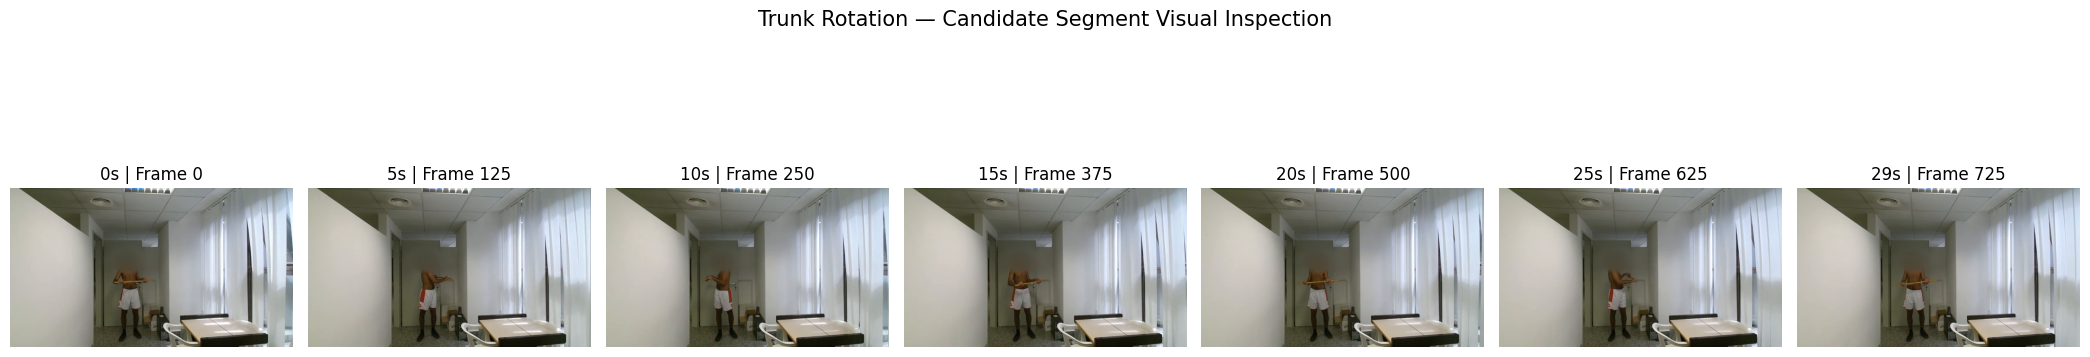

Displayed frames from the first 29.88 seconds.
Original video and NPZ remain unchanged.


In [24]:
import cv2
import matplotlib.pyplot as plt
import os

VIDEO_PATH = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/"
    "Trunk_Rotation/GPP/Stroke/S_ID1/rgb/Blur_rgb060616_122459.mp4"
)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open source video.")

fps = cap.get(cv2.CAP_PROP_FPS)

sample_seconds = [0, 5, 10, 15, 20, 25, 29]

fig, axes = plt.subplots(1, len(sample_seconds), figsize=(21, 5))

for ax, second in zip(axes, sample_seconds):
    frame_number = int(second * fps)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

    success, frame = cap.read()

    if success:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame)
        ax.set_title(f"{second}s | Frame {frame_number}")
    else:
        ax.set_title(f"{second}s | Unavailable")

    ax.axis("off")

cap.release()

plt.suptitle(
    "Trunk Rotation — Candidate Segment Visual Inspection",
    fontsize=15
)
plt.tight_layout()
plt.show()

print("Displayed frames from the first 29.88 seconds.")
print("Original video and NPZ remain unchanged.")

========== MOVEMENT CONTINUITY ==========
Frames: 747
Duration: 29.84 seconds
Shoulder midpoint movement (pixels-normalized): 0.00318
Hip midpoint movement (pixels-normalized): 0.00083
Shoulder angle range: -179.99 to 179.96
Hip angle range: -180.0 to 179.99


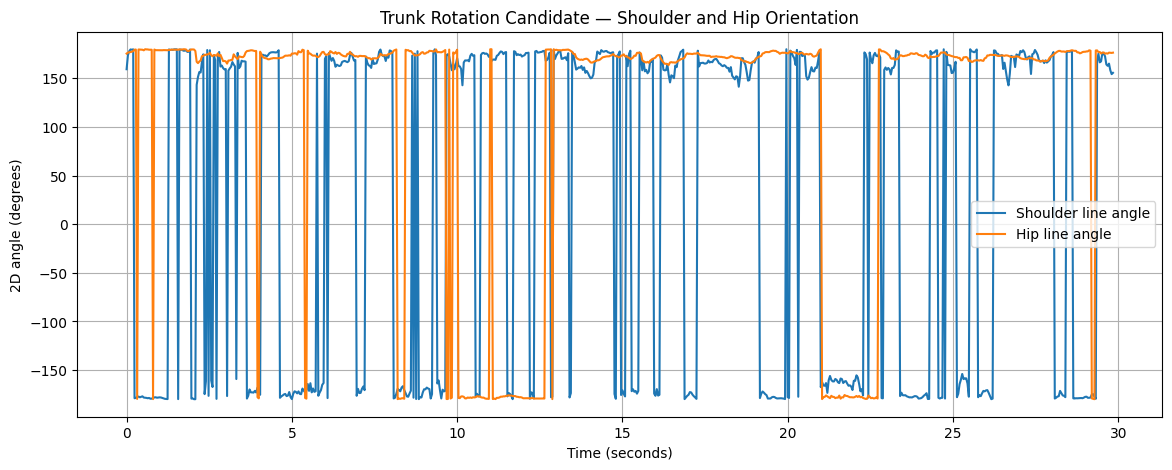

No original data was modified.


In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

NPZ_PATH = os.path.join(
    ROOT,
    "Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID1/"
    "Blur_rgb060616_122459.npz"
)

with np.load(NPZ_PATH, allow_pickle=True) as data:
    pose = data["pose_17"][:747].copy()
    timestamps = data["timestamps_ms"][:747].copy()

# Canonical joint indices
LEFT_SHOULDER = 5
RIGHT_SHOULDER = 6
LEFT_HIP = 11
RIGHT_HIP = 12

# Midpoints of shoulders and hips
shoulder_mid = (
    pose[:, LEFT_SHOULDER, :2] +
    pose[:, RIGHT_SHOULDER, :2]
) / 2

hip_mid = (
    pose[:, LEFT_HIP, :2] +
    pose[:, RIGHT_HIP, :2]
) / 2

# Shoulder and hip line orientations
shoulder_angle = np.degrees(np.arctan2(
    pose[:, RIGHT_SHOULDER, 1] - pose[:, LEFT_SHOULDER, 1],
    pose[:, RIGHT_SHOULDER, 0] - pose[:, LEFT_SHOULDER, 0]
))

hip_angle = np.degrees(np.arctan2(
    pose[:, RIGHT_HIP, 1] - pose[:, LEFT_HIP, 1],
    pose[:, RIGHT_HIP, 0] - pose[:, LEFT_HIP, 0]
))

time_seconds = timestamps / 1000

print("========== MOVEMENT CONTINUITY ==========")
print("Frames:", len(pose))
print("Duration:", round(time_seconds[-1], 2), "seconds")
print("Shoulder midpoint movement (pixels-normalized):",
      round(float(np.mean(np.linalg.norm(
          np.diff(shoulder_mid, axis=0), axis=1
      ))), 5))
print("Hip midpoint movement (pixels-normalized):",
      round(float(np.mean(np.linalg.norm(
          np.diff(hip_mid, axis=0), axis=1
      ))), 5))
print("Shoulder angle range:",
      round(float(np.nanmin(shoulder_angle)), 2),
      "to",
      round(float(np.nanmax(shoulder_angle)), 2))
print("Hip angle range:",
      round(float(np.nanmin(hip_angle)), 2),
      "to",
      round(float(np.nanmax(hip_angle)), 2))

plt.figure(figsize=(14, 5))
plt.plot(time_seconds, shoulder_angle, label="Shoulder line angle")
plt.plot(time_seconds, hip_angle, label="Hip line angle")
plt.xlabel("Time (seconds)")
plt.ylabel("2D angle (degrees)")
plt.title("Trunk Rotation Candidate — Shoulder and Hip Orientation")
plt.legend()
plt.grid(True)
plt.show()

print("No original data was modified.")

========== DEPTH AND WIDTH ANALYSIS ==========

Shoulder depth difference
Valid frames: 747 / 747
Minimum: -0.12715
Maximum: 0.15248
Standard deviation: 0.06225

Hip depth difference
Valid frames: 747 / 747
Minimum: -0.03826
Maximum: 0.07022
Standard deviation: 0.02144

Shoulder width
Valid frames: 747 / 747
Minimum: 0.02405
Maximum: 0.05493
Standard deviation: 0.00692

Hip width
Valid frames: 747 / 747
Minimum: 0.02275
Maximum: 0.03328
Standard deviation: 0.00251


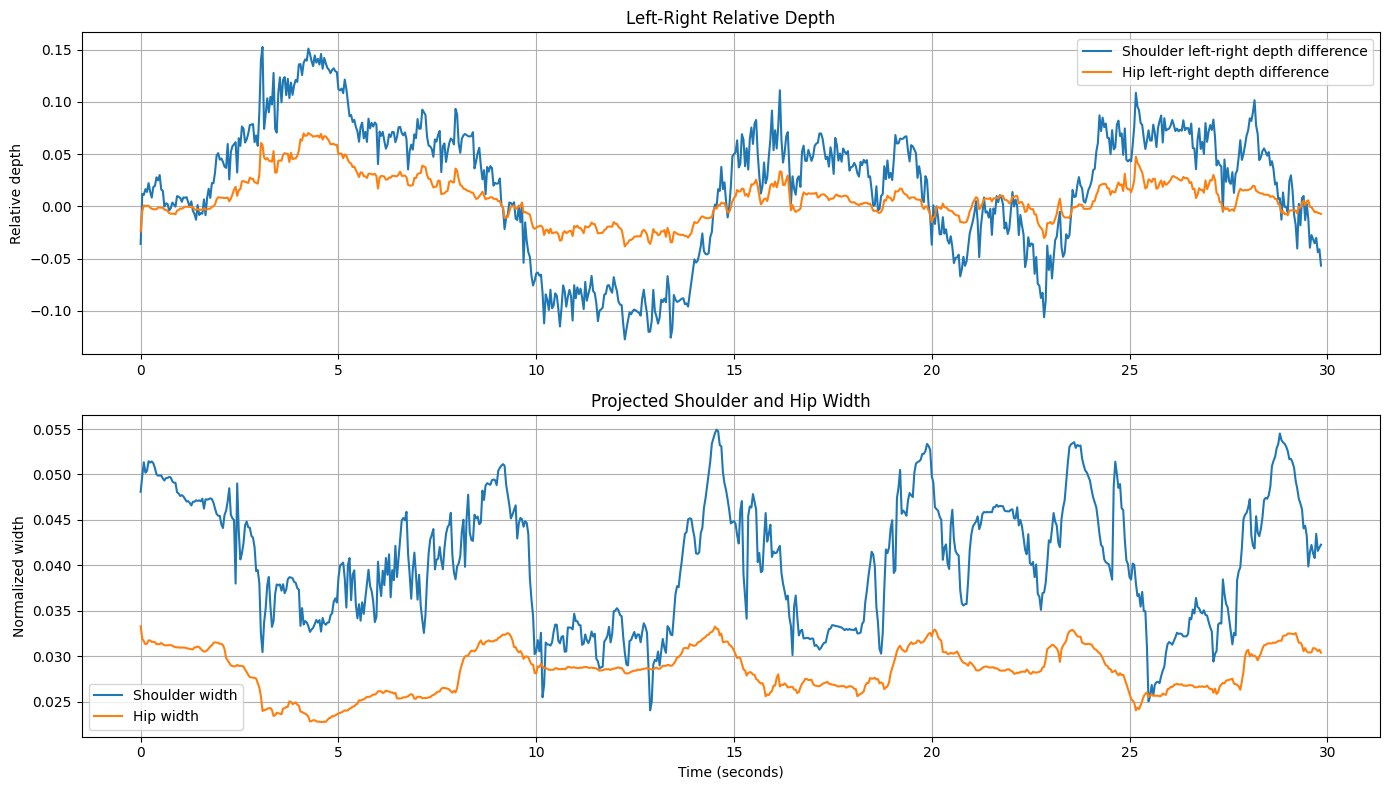


Original NPZ and video remain unchanged.


In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

NPZ_PATH = os.path.join(
    ROOT,
    "Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID1/"
    "Blur_rgb060616_122459.npz"
)

with np.load(NPZ_PATH, allow_pickle=True) as data:
    pose = data["pose_17"][:747].copy()
    timestamps = data["timestamps_ms"][:747].copy()

# Joint indices
LS, RS = 5, 6
LH, RH = 11, 12

# Visibility for both sides
shoulder_visibility = np.minimum(
    pose[:, LS, 3],
    pose[:, RS, 3]
)

hip_visibility = np.minimum(
    pose[:, LH, 3],
    pose[:, RH, 3]
)

# Relative left-right depth differences
shoulder_depth_diff = pose[:, LS, 2] - pose[:, RS, 2]
hip_depth_diff = pose[:, LH, 2] - pose[:, RH, 2]

# Only retain measurements with sufficient visibility
shoulder_depth_diff[shoulder_visibility < 0.5] = np.nan
hip_depth_diff[hip_visibility < 0.5] = np.nan

# Shoulder and hip widths in normalized image coordinates
shoulder_width = np.abs(
    pose[:, LS, 0] - pose[:, RS, 0]
)

hip_width = np.abs(
    pose[:, LH, 0] - pose[:, RH, 0]
)

shoulder_width[shoulder_visibility < 0.5] = np.nan
hip_width[hip_visibility < 0.5] = np.nan

time_seconds = timestamps / 1000

print("========== DEPTH AND WIDTH ANALYSIS ==========")

for name, values in [
    ("Shoulder depth difference", shoulder_depth_diff),
    ("Hip depth difference", hip_depth_diff),
    ("Shoulder width", shoulder_width),
    ("Hip width", hip_width)
]:
    valid = values[np.isfinite(values)]

    print(f"\n{name}")
    print("Valid frames:", len(valid), "/", len(values))

    if len(valid):
        print("Minimum:", round(float(np.min(valid)), 5))
        print("Maximum:", round(float(np.max(valid)), 5))
        print("Standard deviation:", round(float(np.std(valid)), 5))

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(
    time_seconds,
    shoulder_depth_diff,
    label="Shoulder left-right depth difference"
)
axes[0].plot(
    time_seconds,
    hip_depth_diff,
    label="Hip left-right depth difference"
)
axes[0].set_ylabel("Relative depth")
axes[0].set_title("Left-Right Relative Depth")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    time_seconds,
    shoulder_width,
    label="Shoulder width"
)
axes[1].plot(
    time_seconds,
    hip_width,
    label="Hip width"
)
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Normalized width")
axes[1].set_title("Projected Shoulder and Hip Width")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("\nOriginal NPZ and video remain unchanged.")

========== RELATIVE MOVEMENT SUMMARY ==========
Valid frames: 747 / 747
Raw signal minimum: -0.09118
Raw signal maximum: 0.09356
Raw signal standard deviation: 0.04279
Smoothed signal minimum: -0.07893
Smoothed signal maximum: 0.07335
Smoothed signal standard deviation: 0.04149


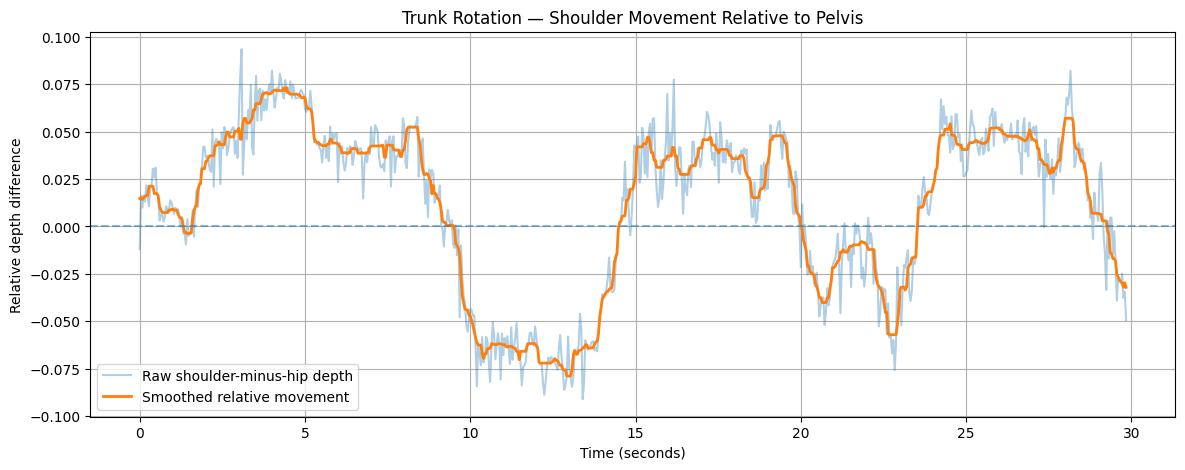

Original NPZ and video remain unchanged.


In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

NPZ_PATH = os.path.join(
    ROOT,
    "Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID1/"
    "Blur_rgb060616_122459.npz"
)

with np.load(NPZ_PATH, allow_pickle=True) as data:
    pose = data["pose_17"][:747].copy()
    timestamps = data["timestamps_ms"][:747].copy()

# Joint indices
LS, RS = 5, 6
LH, RH = 11, 12

# Relative depth asymmetry
shoulder_depth = pose[:, LS, 2] - pose[:, RS, 2]
hip_depth = pose[:, LH, 2] - pose[:, RH, 2]

# Visibility filtering
shoulder_vis = np.minimum(
    pose[:, LS, 3],
    pose[:, RS, 3]
)

hip_vis = np.minimum(
    pose[:, LH, 3],
    pose[:, RH, 3]
)

valid = (shoulder_vis >= 0.5) & (hip_vis >= 0.5)

relative_rotation_signal = shoulder_depth - hip_depth
relative_rotation_signal[~valid] = np.nan

# Interpolate only for visualization/smoothing
valid_indices = np.flatnonzero(valid)

if len(valid_indices) < 20:
    raise RuntimeError("Insufficient valid frames for analysis.")

interpolated = np.interp(
    np.arange(len(relative_rotation_signal)),
    valid_indices,
    relative_rotation_signal[valid]
)

# Rolling median smoothing
window = 11
smoothed = np.array([
    np.median(interpolated[max(0, i-window//2):
                           min(len(interpolated), i+window//2+1)])
    for i in range(len(interpolated))
])

time_seconds = timestamps / 1000

print("========== RELATIVE MOVEMENT SUMMARY ==========")
print("Valid frames:", int(valid.sum()), "/", len(valid))
print("Raw signal minimum:", round(float(np.min(relative_rotation_signal[valid])), 5))
print("Raw signal maximum:", round(float(np.max(relative_rotation_signal[valid])), 5))
print("Raw signal standard deviation:",
      round(float(np.std(relative_rotation_signal[valid])), 5))
print("Smoothed signal minimum:", round(float(np.min(smoothed)), 5))
print("Smoothed signal maximum:", round(float(np.max(smoothed)), 5))
print("Smoothed signal standard deviation:",
      round(float(np.std(smoothed)), 5))

plt.figure(figsize=(14, 5))

plt.plot(
    time_seconds,
    relative_rotation_signal,
    alpha=0.35,
    label="Raw shoulder-minus-hip depth"
)

plt.plot(
    time_seconds,
    smoothed,
    linewidth=2,
    label="Smoothed relative movement"
)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Time (seconds)")
plt.ylabel("Relative depth difference")
plt.title("Trunk Rotation — Shoulder Movement Relative to Pelvis")
plt.legend()
plt.grid(True)
plt.show()

print("Original NPZ and video remain unchanged.")

In [28]:
import os
import numpy as np

# Original file
SOURCE = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed/"
    "Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID1/"
    "Blur_rgb060616_122459.npz"
)

# Separate recovery output directory
OUTPUT_DIR = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "recovery_candidates/Trunk_Rotation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT = os.path.join(
    OUTPUT_DIR,
    "Blur_rgb060616_122459_candidate_frames_000_746.npz"
)

START_FRAME = 0
END_FRAME = 747  # Exclusive: includes frames 0–746

if not os.path.exists(SOURCE):
    raise FileNotFoundError(SOURCE)

if os.path.exists(OUTPUT):
    raise FileExistsError(
        "Recovery candidate already exists. "
        "No file was overwritten: " + OUTPUT
    )

# Read original data
with np.load(SOURCE, allow_pickle=True) as data:
    original = {key: data[key].copy() for key in data.files}

# Validate original pose
pose = original["pose_17"]

if pose.shape[0] != 1199:
    raise ValueError("Unexpected original pose frame count.")

candidate = {}

# Crop all frame-aligned arrays consistently.
for key, value in original.items():

    if (
        isinstance(value, np.ndarray)
        and value.ndim > 0
        and value.shape[0] == 1199
    ):
        candidate[key] = value[START_FRAME:END_FRAME].copy()

    else:
        candidate[key] = value.copy()

# Validate cropped pose and timestamps
if candidate["pose_17"].shape != (747, 17, 4):
    raise ValueError("Unexpected recovered pose shape.")

if candidate["pose_33"].shape != (747, 33, 4):
    raise ValueError("Unexpected recovered pose33 shape.")

if len(candidate["timestamps_ms"]) != 747:
    raise ValueError("Timestamp crop mismatch.")

if np.isnan(candidate["pose_17"]).any():
    raise ValueError("Recovered segment unexpectedly contains NaNs.")

# Add recovery provenance and review status
candidate["recovery_status"] = np.array("PROVISIONAL_REVIEW")
candidate["recovery_start_frame"] = np.array(START_FRAME)
candidate["recovery_end_frame_exclusive"] = np.array(END_FRAME)
candidate["original_frame_count"] = np.array(1199)
candidate["recovery_reason"] = np.array(
    "747 consecutive valid frames; movement evidence reviewed; "
    "requires further exercise and repetition validation."
)
candidate["original_npz_path"] = np.array(SOURCE)

# Save as a new file only
np.savez_compressed(OUTPUT, **candidate)

# Reopen and verify saved copy
with np.load(OUTPUT, allow_pickle=True) as recovered:
    print("========== RECOVERY VERIFICATION ==========")
    print("Output:", OUTPUT)
    print("Pose 17:", recovered["pose_17"].shape)
    print("Pose 33:", recovered["pose_33"].shape)
    print("Timestamps:", recovered["timestamps_ms"].shape)
    print("Status:", recovered["recovery_status"].item())
    print("Participant:", recovered["participant"].item())
    print("Exercise:", recovered["exercise_name"].item())
    print("Dataset:", recovered["dataset"].item())
    print("NaN count:", int(np.isnan(recovered["pose_17"]).sum()))

print("\nOriginal NPZ was not modified.")
print("Original video was not modified.")
print("Recovered copy is NOT yet training-ready.")

========== RECOVERY VERIFICATION ==========
Output: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/recovery_candidates/Trunk_Rotation/Blur_rgb060616_122459_candidate_frames_000_746.npz
Pose 17: (747, 17, 4)
Pose 33: (747, 33, 4)
Timestamps: (747,)
Status: PROVISIONAL_REVIEW
Participant: S_ID1
Exercise: Trunk_Rotation
Dataset: KIMORE
NaN count: 0

Original NPZ was not modified.
Original video was not modified.
Recovered copy is NOT yet training-ready.


In [29]:
import os
import pandas as pd
import numpy as np

METADATA_DIR = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
)

RECOVERY_FILE = os.path.join(
    METADATA_DIR,
    "recovery_candidates/Trunk_Rotation/"
    "Blur_rgb060616_122459_candidate_frames_000_746.npz"
)

AUDIT_FILE = os.path.join(
    METADATA_DIR,
    "RehabIQ_Recovery_Audit_Register.csv"
)

if not os.path.exists(RECOVERY_FILE):
    raise FileNotFoundError(RECOVERY_FILE)

# Read and verify recovered candidate
with np.load(RECOVERY_FILE, allow_pickle=True) as data:

    pose17 = data["pose_17"]
    pose33 = data["pose_33"]
    timestamps = data["timestamps_ms"]

    record = {
        "dataset": str(data["dataset"].item()),
        "exercise": str(data["exercise_name"].item()),
        "exercise_id": str(data["exercise_id"].item()),
        "participant": str(data["participant"].item()),
        "group": str(data["group"].item()),
        "category": str(data["category"].item()),
        "original_filename": str(data["filename"].item()),
        "original_npz": str(data["original_npz_path"].item()),
        "recovered_npz": RECOVERY_FILE,
        "start_frame": int(data["recovery_start_frame"]),
        "end_frame_exclusive": int(data["recovery_end_frame_exclusive"]),
        "recovered_frames": int(len(pose17)),
        "fps": float(data["fps"]),
        "duration_seconds": round(
            (timestamps[-1] - timestamps[0]) / 1000, 3
        ),
        "pose17_shape": str(pose17.shape),
        "pose33_shape": str(pose33.shape),
        "pose17_nan_count": int(np.isnan(pose17).sum()),
        "pose33_nan_count": int(np.isnan(pose33).sum()),
        "recovery_status": "PROVISIONAL_REVIEW",
        "training_approved": False,
        "visual_review": "Initial visual inspection completed",
        "movement_review": "Relative depth variation observed",
        "remaining_validation": (
            "Verify exercise execution, repetition coverage, "
            "and suitability before training approval"
        )
    }

# Load existing register if present
if os.path.exists(AUDIT_FILE):
    audit = pd.read_csv(AUDIT_FILE)

    if (
        "recovered_npz" in audit.columns
        and record["recovered_npz"] in audit["recovered_npz"].astype(str).values
    ):
        raise FileExistsError(
            "This recovery candidate is already registered. "
            "No existing record was changed."
        )

    audit = pd.concat(
        [audit, pd.DataFrame([record])],
        ignore_index=True
    )
else:
    audit = pd.DataFrame([record])

# Save separate audit register
audit.to_csv(AUDIT_FILE, index=False)

print("========== RECOVERY AUDIT REGISTER ==========")
print("Saved:", AUDIT_FILE)
print("Total registered candidates:", len(audit))
print("\nLatest recovery record:")
print(pd.DataFrame([record]).T.to_string(header=False))

print("\nOriginal QC manifest was not modified.")
print("Original dataset files were not modified.")

========== RECOVERY AUDIT REGISTER ==========
Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Recovery_Audit_Register.csv
Total registered candidates: 1

Latest recovery record:
dataset                                                                                                                                               KIMORE
exercise                                                                                                                                      Trunk_Rotation
exercise_id                                                                                                                                              Es3
participant                                                                                                                                            S_ID1
group                                                                                                                                                    GPP
category             

In [30]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

OUTPUT = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Critical_Review_Register.csv"
)

# Seven recordings other than the recovered candidate
critical_files = [
    ("Trunk_Lateral_Bending", "Blur_rgb040716_113944.npz"),
    ("Trunk_Lateral_Bending", "Blur_rgb040716_112330.npz"),
    ("Trunk_Rotation", "Blur_rgb130616_111104.npz"),
    ("Trunk_Rotation", "Blur_rgb040716_114849.npz"),
    ("Trunk_Rotation", "Blur_rgb040716_114043.npz"),
    ("Trunk_Rotation", "Blur_rgb110616_113116.npz"),
    ("Trunk_Rotation", "Blur_rgb040716_112422.npz"),
]

def longest_true_run(mask):
    indices = np.flatnonzero(mask)

    if len(indices) == 0:
        return 0, None, None

    splits = np.split(
        indices,
        np.where(np.diff(indices) != 1)[0] + 1
    )

    longest = max(splits, key=len)

    return len(longest), int(longest[0]), int(longest[-1])


records = []

for exercise, filename in critical_files:

    matches = []

    for current_root, _, files in os.walk(
        os.path.join(ROOT, exercise)
    ):
        if filename in files:
            matches.append(os.path.join(current_root, filename))

    if len(matches) != 1:
        raise RuntimeError(
            f"{filename}: expected exactly one file, found {len(matches)}"
        )

    path = matches[0]

    with np.load(path, allow_pickle=True) as data:

        pose_key = next(
            (
                key for key in [
                    "pose_17", "landmarks_17", "pose17"
                ]
                if key in data.files
            ),
            None
        )

        if pose_key is None:
            raise KeyError(f"No 17-joint pose array in {filename}")

        pose = np.asarray(data[pose_key])
        timestamps = np.asarray(
            data["timestamps_ms"]
        ).reshape(-1)

        if len(pose) != len(timestamps):
            raise ValueError(
                f"Frame/timestamp mismatch in {filename}"
            )

        # A valid frame has finite x/y values for all 17 joints.
        valid_mask = np.isfinite(pose[:, :, :2]).all(axis=(1, 2))

        longest_frames, start_frame, end_frame = longest_true_run(
            valid_mask
        )

        median_interval = (
            float(np.median(np.diff(timestamps)))
            if len(timestamps) > 1 else np.nan
        )

        longest_duration = (
            (timestamps[end_frame] - timestamps[start_frame]
             + median_interval) / 1000
            if start_frame is not None and np.isfinite(median_interval)
            else 0
        )

        records.append({
            "exercise": exercise,
            "filename": filename,
            "original_npz_path": path,
            "total_frames": len(pose),
            "valid_frames": int(valid_mask.sum()),
            "valid_frame_percentage": round(
                float(valid_mask.mean() * 100), 2
            ),
            "number_of_valid_segments": int(
                np.sum(valid_mask & ~np.r_[False, valid_mask[:-1]])
            ),
            "longest_segment_frames": longest_frames,
            "longest_segment_start_frame": start_frame,
            "longest_segment_end_frame": end_frame,
            "longest_segment_seconds": round(
                float(longest_duration), 3
            ),
            "review_status": "HOLD_FRAGMENTED",
            "training_approved": False,
            "decision_note": (
                "Previously assessed as heavily fragmented; "
                "retain original and hold pending further review."
            )
        })

# Save a separate register
register = pd.DataFrame(records)
register.to_csv(OUTPUT, index=False)

print("========== SEVEN CRITICAL FILES ==========")
print(register[[
    "exercise",
    "filename",
    "valid_frame_percentage",
    "number_of_valid_segments",
    "longest_segment_frames",
    "longest_segment_seconds",
    "review_status"
]].to_string(index=False))

print("\nSaved register:", OUTPUT)
print("Files registered:", len(register))
print("Training-approved:", int(register["training_approved"].sum()))
print("\nOriginal NPZ files and QC manifest were not modified.")

========== SEVEN CRITICAL FILES ==========
             exercise                  filename  valid_frame_percentage  number_of_valid_segments  longest_segment_frames  longest_segment_seconds   review_status
Trunk_Lateral_Bending Blur_rgb040716_113944.npz                   38.96                        45                      47                     1.88 HOLD_FRAGMENTED
Trunk_Lateral_Bending Blur_rgb040716_112330.npz                   31.17                        48                      20                     0.80 HOLD_FRAGMENTED
       Trunk_Rotation Blur_rgb130616_111104.npz                   25.71                        19                      47                     1.88 HOLD_FRAGMENTED
       Trunk_Rotation Blur_rgb040716_114849.npz                   43.49                        43                      36                     1.44 HOLD_FRAGMENTED
       Trunk_Rotation Blur_rgb040716_114043.npz                    3.04                         9                       6                     

In [31]:
import os
import pandas as pd

META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

RECOVERY_FILE = os.path.join(
    META, "RehabIQ_Recovery_Audit_Register.csv"
)

HOLD_FILE = os.path.join(
    META, "RehabIQ_Critical_Review_Register.csv"
)

OUTPUT_FILE = os.path.join(
    META, "RehabIQ_Critical_Cases_Consolidated.csv"
)

recovery = pd.read_csv(RECOVERY_FILE)
hold = pd.read_csv(HOLD_FILE)

recovery_records = pd.DataFrame({
    "exercise": recovery["exercise"],
    "filename": recovery["original_filename"],
    "participant": recovery["participant"],
    "original_npz_path": recovery["original_npz"],
    "candidate_npz_path": recovery["recovered_npz"],
    "valid_frames": recovery["recovered_frames"],
    "valid_percentage": None,
    "longest_segment_seconds": recovery["duration_seconds"],
    "review_status": recovery["recovery_status"],
    "training_approved": recovery["training_approved"],
    "decision": "Separate provisional recovery copy created"
})

hold_records = pd.DataFrame({
    "exercise": hold["exercise"],
    "filename": hold["filename"],
    "participant": None,
    "original_npz_path": hold["original_npz_path"],
    "candidate_npz_path": None,
    "valid_frames": hold["valid_frames"],
    "valid_percentage": hold["valid_frame_percentage"],
    "longest_segment_seconds": hold["longest_segment_seconds"],
    "review_status": hold["review_status"],
    "training_approved": hold["training_approved"],
    "decision": "Retain original; hold due to fragmented pose data"
})

combined = pd.concat(
    [recovery_records, hold_records],
    ignore_index=True
)

combined.to_csv(OUTPUT_FILE, index=False)

print("========== CONSOLIDATED CRITICAL CASES ==========")
print("Total cases:", len(combined))
print("Provisional recovery:", int(
    (combined["review_status"] == "PROVISIONAL_REVIEW").sum()
))
print("On hold:", int(
    (combined["review_status"] == "HOLD_FRAGMENTED").sum()
))
print("Training approved:", int(
    combined["training_approved"].fillna(False).astype(bool).sum()
))

print("\n", combined[[
    "exercise",
    "filename",
    "review_status",
    "longest_segment_seconds",
    "training_approved"
]].to_string(index=False))

print("\nSaved:", OUTPUT_FILE)
print("Original QC manifest and NPZ files remain unchanged.")

========== CONSOLIDATED CRITICAL CASES ==========
Total cases: 8
Provisional recovery: 1
On hold: 7
Training approved: 0

              exercise                  filename      review_status  longest_segment_seconds  training_approved
       Trunk_Rotation Blur_rgb060616_122459.mp4 PROVISIONAL_REVIEW                    29.84              False
Trunk_Lateral_Bending Blur_rgb040716_113944.npz    HOLD_FRAGMENTED                     1.88              False
Trunk_Lateral_Bending Blur_rgb040716_112330.npz    HOLD_FRAGMENTED                     0.80              False
       Trunk_Rotation Blur_rgb130616_111104.npz    HOLD_FRAGMENTED                     1.88              False
       Trunk_Rotation Blur_rgb040716_114849.npz    HOLD_FRAGMENTED                     1.44              False
       Trunk_Rotation Blur_rgb040716_114043.npz    HOLD_FRAGMENTED                     0.24              False
       Trunk_Rotation Blur_rgb110616_113116.npz    HOLD_FRAGMENTED                     1.36         

/tmp/ipykernel_3061/2823277853.py:49: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(


In [32]:
import os

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset"

keywords = (
    "annotation",
    "annot",
    "ground_truth",
    "groundtruth",
    "label",
    "score",
    "repetition",
    "rep"
)

print("========== KIMORE ANNOTATION FILE SEARCH ==========")

matches = []

for current_root, dirs, files in os.walk(ROOT):

    # Skip processed pose arrays and recovery outputs
    dirs[:] = [
        d for d in dirs
        if d not in ["pose_sequences", "recovery_candidates"]
    ]

    for filename in files:
        lower = filename.lower()

        if (
            any(keyword in lower for keyword in keywords)
            and lower.endswith((".csv", ".xlsx", ".xls", ".json", ".txt"))
        ):
            path = os.path.join(current_root, filename)

            if "kimore" in path.lower() or "annotation" in lower:
                matches.append(path)

for path in matches[:100]:
    print(path)

print("\nTotal matching files:", len(matches))
print("Search completed. No files were modified.")

========== KIMORE ANNOTATION FILE SEARCH ==========
/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/Rehab24_6/annotation_matching/videos_without_annotations.csv
/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/KIMORE/quality_reports/KIMORE_final_preprocessing_manifest.csv
/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/KIMORE/quality_reports/manual_review_previews/preview_generation_report.csv

Total matching files: 3
Search completed. No files were modified.


In [33]:
import os
import pandas as pd

BASE = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "KIMORE/quality_reports"
)

FILES = [
    "KIMORE_final_preprocessing_manifest.csv",
    "manual_review_previews/preview_generation_report.csv"
]

TARGET = "Blur_rgb060616_122459"

for filename in FILES:

    path = os.path.join(BASE, filename)

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        continue

    df = pd.read_csv(path)

    print("\nShape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nMatching candidate recording:")
    mask = df.astype(str).apply(
        lambda column: column.str.contains(
            TARGET, case=False, na=False
        )
    ).any(axis=1)

    if mask.any():
        print(df.loc[mask].to_string(index=False))
    else:
        print("No matching recording found.")

    print("\nFirst 3 records:")
    print(df.head(3).to_string(index=False))

print("\nNo source reports were modified.")


FILE: KIMORE_final_preprocessing_manifest.csv
Exists: True

Shape: (206, 24)

Columns:
['dataset', 'exercise_name', 'exercise_id', 'group', 'category', 'participant', 'filename', 'output_path', 'status', 'frames', 'fps', 'detected_frames', 'detection_percentage', 'mean_visibility', 'joint_mean_visibility', 'joint_below_050_percentage', 'quality_flag', 'detection_percent', 'automatic_quality_status', 'manual_review_status', 'final_decision', 'preprocessing_decision', 'prepared_path', 'copy_status']

Matching candidate recording:
dataset  exercise_name exercise_id group category participant                  filename                                                                                                                      output_path    status  frames  fps  detected_frames  detection_percentage  mean_visibility                                                                                                                                                                          

Preview exists: True
Image dimensions: (960, 540)
Image format: JPEG


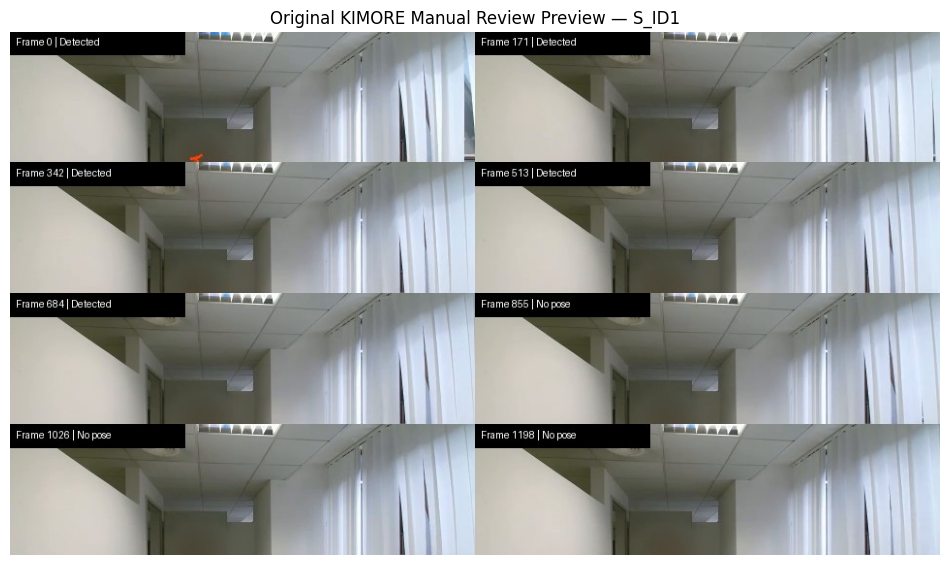


Original preview was not modified.


In [35]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Corrected path: Changed 'processed' to 'metadata' to locate the report files
PREVIEW_PATH = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "KIMORE/quality_reports/manual_review_previews/"
    "Trunk_Rotation_S_ID1_Blur_rgb060616_122459.jpg"
)

print("Preview exists:", os.path.exists(PREVIEW_PATH))

if not os.path.exists(PREVIEW_PATH):
    raise FileNotFoundError(PREVIEW_PATH)

img = Image.open(PREVIEW_PATH)

print("Image dimensions:", img.size)
print("Image format:", img.format)

plt.figure(figsize=(12, 7))
plt.imshow(img)
plt.title("Original KIMORE Manual Review Preview — S_ID1")
plt.axis("off")
plt.show()

print("\nOriginal preview was not modified.")

In [36]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

OUTPUT = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Canonical_Naming_Compatibility_Audit.csv"
)

ALIASES = {
    "pose_17": ["pose_17", "landmarks_17", "pose17"],
    "pose_33": ["pose_33", "landmarks_33", "pose33"],
    "timestamps_ms": ["timestamps_ms"]
}

records = []
errors = []

for current_root, _, files in os.walk(ROOT):
    for filename in files:

        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)

        try:
            with np.load(path, allow_pickle=True) as data:

                keys = data.files
                selected = {}

                for canonical, aliases in ALIASES.items():
                    matches = [key for key in aliases if key in keys]

                    if len(matches) != 1:
                        selected[canonical] = None
                    else:
                        selected[canonical] = matches[0]

                row = {
                    "exercise": path.split("/processed/")[1].split("/")[0],
                    "filename": filename,
                    "path": path,
                    "original_keys": "|".join(keys),
                    "pose17_source_key": selected["pose_17"],
                    "pose33_source_key": selected["pose_33"],
                    "timestamp_source_key": selected["timestamps_ms"]
                }

                valid = True

                for canonical, expected_joints in [
                    ("pose_17", 17),
                    ("pose_33", 33)
                ]:
                    source_key = selected[canonical]

                    if source_key is None:
                        row[canonical + "_status"] = "MISSING_OR_AMBIGUOUS"
                        valid = False
                        continue

                    arr = data[source_key]

                    row[canonical + "_shape"] = str(arr.shape)
                    row[canonical + "_dtype"] = str(arr.dtype)

                    shape_ok = (
                        arr.ndim == 3
                        and arr.shape[1] == expected_joints
                        and arr.shape[2] == 4
                    )

                    row[canonical + "_status"] = (
                        "OK" if shape_ok else "INVALID_SHAPE"
                    )

                    if not shape_ok:
                        valid = False

                timestamp_key = selected["timestamps_ms"]

                if timestamp_key is None:
                    row["timestamp_status"] = "MISSING_OR_AMBIGUOUS"
                    valid = False
                else:
                    timestamps = np.asarray(
                        data[timestamp_key]
                    ).reshape(-1)

                    row["timestamp_count"] = len(timestamps)

                    timestamp_ok = (
                        timestamps.size > 0
                        and np.issubdtype(timestamps.dtype, np.number)
                        and np.isfinite(timestamps).all()
                        and (
                            len(timestamps) < 2
                            or np.all(np.diff(timestamps) > 0)
                        )
                    )

                    row["timestamp_status"] = (
                        "OK" if timestamp_ok else "INVALID"
                    )

                    if not timestamp_ok:
                        valid = False

                # Frame alignment
                if (
                    selected["pose_17"] is not None
                    and selected["pose_33"] is not None
                    and timestamp_key is not None
                ):
                    p17 = data[selected["pose_17"]]
                    p33 = data[selected["pose_33"]]

                    aligned = (
                        p17.shape[0] == p33.shape[0]
                        == len(timestamps)
                    )

                    row["frame_alignment"] = (
                        "OK" if aligned else "MISMATCH"
                    )

                    if not aligned:
                        valid = False
                else:
                    row["frame_alignment"] = "NOT_CHECKED"
                    aligned = False

                # Joint-name metadata
                joint_key = next(
                    (
                        k for k in [
                            "joint_names_17",
                            "joint_names",
                        ]
                        if k in keys
                    ),
                    None
                )

                row["joint_names_key"] = joint_key

                if joint_key is not None:
                    joint_names = np.asarray(
                        data[joint_key]
                    ).reshape(-1)

                    row["joint_names_count"] = len(joint_names)
                    row["joint_names_status"] = (
                        "17_NAMES"
                        if len(joint_names) == 17
                        else "OTHER_COUNT"
                    )
                else:
                    row["joint_names_count"] = None
                    row["joint_names_status"] = "NOT_STORED"

                # Identify naming convention
                naming = (
                    selected["pose_17"],
                    selected["pose_33"]
                )

                if naming == ("pose_17", "pose_33"):
                    row["naming_convention"] = "STANDARD"

                elif naming == ("landmarks_17", "landmarks_33"):
                    row["naming_convention"] = "LANDMARKS"

                elif naming == ("pose17", "pose33"):
                    row["naming_convention"] = "COMPACT"

                else:
                    row["naming_convention"] = "MIXED_OR_OTHER"

                row["compatibility_status"] = (
                    "COMPATIBLE" if valid else "REVIEW_REQUIRED"
                )

                records.append(row)

        except Exception as e:
            errors.append({
                "filename": filename,
                "path": path,
                "error": str(e)
            })

df = pd.DataFrame(records)

df.to_csv(OUTPUT, index=False)

print("========== CANONICAL COMPATIBILITY AUDIT ==========")
print("Files successfully inspected:", len(df))
print("Files with read errors:", len(errors))

print("\nNaming conventions:")
print(df["naming_convention"].value_counts(dropna=False))

print("\nCompatibility:")
print(df["compatibility_status"].value_counts(dropna=False))

print("\nStructural checks:")
for column in [
    "pose_17_status",
    "pose_33_status",
    "timestamp_status",
    "frame_alignment",
    "joint_names_status"
]:
    print("\n" + column)
    print(df[column].value_counts(dropna=False))

print("\nExercise-wise compatibility:")
print(
    df.groupby("exercise")["compatibility_status"]
      .value_counts()
      .unstack(fill_value=0)
      .to_string()
)

if errors:
    print("\nRead errors:")
    print(pd.DataFrame(errors).to_string(index=False))

print("\nAudit saved:", OUTPUT)
print("Original NPZ files were not modified.")

========== CANONICAL COMPATIBILITY AUDIT ==========
Files successfully inspected: 2471
Files with read errors: 0

Naming conventions:
naming_convention
STANDARD     1995
LANDMARKS     243
COMPACT       233
Name: count, dtype: int64

Compatibility:
compatibility_status
COMPATIBLE    2471
Name: count, dtype: int64

Structural checks:

pose_17_status
pose_17_status
OK    2471
Name: count, dtype: int64

pose_33_status
pose_33_status
OK    2471
Name: count, dtype: int64

timestamp_status
timestamp_status
OK    2471
Name: count, dtype: int64

frame_alignment
frame_alignment
OK    2471
Name: count, dtype: int64

joint_names_status
joint_names_status
17_NAMES    2471
Name: count, dtype: int64

Exercise-wise compatibility:
compatibility_status        COMPATIBLE
exercise                              
Arm_Raising                         72
Forward_Lunge                      367
Hip_Flexion                         83
Leg_Abduction                      444
Lumbar_Flexion                     160
Sea

In [37]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

OUTPUT = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Coordinate_Normalization_Audit.csv"
)

# Support all three verified naming conventions
POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

records = []
errors = []

for current_root, _, files in os.walk(ROOT):

    for filename in files:

        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)

        try:
            with np.load(path, allow_pickle=True) as data:

                pose_key = next(
                    (key for key in POSE_KEYS if key in data.files),
                    None
                )

                if pose_key is None:
                    raise KeyError("No recognized 17-joint array")

                pose = np.asarray(data[pose_key])

                if pose.ndim != 3 or pose.shape[1:] != (17, 4):
                    raise ValueError(
                        f"Unexpected pose shape: {pose.shape}"
                    )

                xy = pose[:, :, :2]
                z = pose[:, :, 2]
                visibility = pose[:, :, 3]

                # Calculate only from finite values
                def safe_stats(array):
                    values = array[np.isfinite(array)]

                    if len(values) == 0:
                        return {
                            "min": np.nan,
                            "max": np.nan,
                            "mean": np.nan,
                            "std": np.nan
                        }

                    return {
                        "min": float(np.min(values)),
                        "max": float(np.max(values)),
                        "mean": float(np.mean(values)),
                        "std": float(np.std(values))
                    }

                x_stats = safe_stats(xy[:, :, 0])
                y_stats = safe_stats(xy[:, :, 1])
                z_stats = safe_stats(z)
                vis_stats = safe_stats(visibility)

                records.append({
                    "exercise": path.split("/processed/")[1].split("/")[0],
                    "filename": filename,
                    "path": path,
                    "frames": len(pose),
                    "pose_key": pose_key,

                    "x_min": x_stats["min"],
                    "x_max": x_stats["max"],
                    "x_mean": x_stats["mean"],
                    "x_std": x_stats["std"],

                    "y_min": y_stats["min"],
                    "y_max": y_stats["max"],
                    "y_mean": y_stats["mean"],
                    "y_std": y_stats["std"],

                    "z_min": z_stats["min"],
                    "z_max": z_stats["max"],
                    "z_mean": z_stats["mean"],
                    "z_std": z_stats["std"],

                    "visibility_min": vis_stats["min"],
                    "visibility_max": vis_stats["max"],
                    "visibility_mean": vis_stats["mean"],

                    "finite_xy_percentage": (
                        np.isfinite(xy).sum() / xy.size * 100
                    ),

                    "finite_z_percentage": (
                        np.isfinite(z).sum() / z.size * 100
                    )
                })

        except Exception as e:
            errors.append({
                "filename": filename,
                "path": path,
                "error": str(e)
            })

df = pd.DataFrame(records)

os.makedirs(os.path.dirname(OUTPUT), exist_ok=True)
df.to_csv(OUTPUT, index=False)

print("========== COORDINATE NORMALIZATION AUDIT ==========")

print("Files successfully audited:", len(df))
print("Read errors:", len(errors))

print("\n========== GLOBAL COORDINATE STATISTICS ==========")

columns = [
    "x_min", "x_max", "x_mean", "x_std",
    "y_min", "y_max", "y_mean", "y_std",
    "z_min", "z_max", "z_mean", "z_std",
    "visibility_min", "visibility_max", "visibility_mean",
    "finite_xy_percentage", "finite_z_percentage"
]

print(df[columns].describe().round(5).to_string())

print("\n========== EXERCISE-WISE MEDIAN STATISTICS ==========")

print(
    df.groupby("exercise")[[
        "x_min", "x_max",
        "y_min", "y_max",
        "z_min", "z_max",
        "visibility_mean",
        "finite_xy_percentage"
    ]].median().round(5).to_string()
)

print("\n========== FILES WITH COORDINATES OUTSIDE [0,1] ==========")

outside = df[
    (df["x_min"] < 0) |
    (df["x_max"] > 1) |
    (df["y_min"] < 0) |
    (df["y_max"] > 1)
]

print("Files:", len(outside))

print("\n========== AUDIT ERRORS ==========")

if errors:
    print(pd.DataFrame(errors).to_string(index=False))
else:
    print("No errors.")

print("\nAudit saved:", OUTPUT)
print("Original NPZ files were NOT modified.")
print("No normalization transformation was performed.")


========== COORDINATE NORMALIZATION AUDIT ==========
Files successfully audited: 2471
Read errors: 0

========== GLOBAL COORDINATE STATISTICS ==========
            x_min       x_max      x_mean       x_std       y_min       y_max      y_mean       y_std       z_min       z_max      z_mean       z_std  visibility_min  visibility_max  visibility_mean  finite_xy_percentage  finite_z_percentage
count  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000  2471.00000      2471.00000      2471.00000       2471.00000            2471.00000           2471.00000
mean      0.25166     0.65847     0.46257     0.07827     0.26875     0.84614     0.50909     0.16236    -0.66000     0.53315    -0.09463     0.22264         0.41330         0.99998          0.92654              99.31742             99.31742
std       0.16045     0.16694     0.07777     0.04384     0.10064     0.13239     0.06344     0.05076     0.32116     0.3

In [38]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

JOINT_NAMES = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]

records = []

for current_root, _, files in os.walk(ROOT):
    for filename in files:

        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)

        with np.load(path, allow_pickle=True) as data:

            key = next(k for k in POSE_KEYS if k in data.files)
            pose = np.asarray(data[key])

            xy = pose[:, :, :2]

            # Out-of-range means either x or y outside [0,1]
            invalid = (
                ((xy < 0) | (xy > 1)) &
                np.isfinite(xy)
            )

            affected = invalid.any(axis=2)

            if not affected.any():
                continue

            for joint_idx, joint_name in enumerate(JOINT_NAMES):

                joint_xy = xy[:, joint_idx, :]
                joint_invalid = invalid[:, joint_idx, :]

                if not joint_invalid.any():
                    continue

                finite_x = joint_xy[:, 0][
                    np.isfinite(joint_xy[:, 0])
                ]
                finite_y = joint_xy[:, 1][
                    np.isfinite(joint_xy[:, 1])
                ]

                records.append({
                    "exercise": path.split("/processed/")[1].split("/")[0],
                    "filename": filename,
                    "joint": joint_name,
                    "affected_frames": int(
                        joint_invalid.any(axis=1).sum()
                    ),
                    "x_min": (
                        float(finite_x.min())
                        if len(finite_x) else np.nan
                    ),
                    "x_max": (
                        float(finite_x.max())
                        if len(finite_x) else np.nan
                    ),
                    "y_min": (
                        float(finite_y.min())
                        if len(finite_y) else np.nan
                    ),
                    "y_max": (
                        float(finite_y.max())
                        if len(finite_y) else np.nan
                    )
                })

df = pd.DataFrame(records)

OUTPUT = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Out_of_Range_Joint_Analysis.csv"
)

df.to_csv(OUTPUT, index=False)

print("========== OUT-OF-RANGE JOINT ANALYSIS ==========")
print("Affected file/joint combinations:", len(df))
print("Affected files:", df["filename"].nunique())

print("\nAffected joints:")
print(
    df.groupby("joint")["affected_frames"]
      .sum()
      .sort_values(ascending=False)
      .to_string()
)

print("\nAffected exercises:")
print(
    df.groupby("exercise")["filename"]
      .nunique()
      .sort_values(ascending=False)
      .to_string()
)

print("\nMost affected records:")
print(
    df.sort_values("affected_frames", ascending=False)
      .head(20)
      .to_string(index=False)
)

print("\nSaved:", OUTPUT)
print("Original NPZ files unchanged.")


========== OUT-OF-RANGE JOINT ANALYSIS ==========
Affected file/joint combinations: 1687
Affected files: 229

Affected joints:
joint
right_ankle       14347
left_ankle        13755
right_knee         2933
left_knee          2260
nose               1816
left_wrist         1781
right_eye          1752
left_eye           1706
right_wrist        1698
right_ear          1293
left_ear           1140
right_shoulder      820
right_elbow         772
right_hip           691
left_shoulder       656
left_hip            606
left_elbow          580

Affected exercises:
exercise
Shoulder_Circumduction        47
Shoulder_External_Rotation    31
Shoulder_Abduction            29
Lumbar_Flexion                24
Hip_Flexion                   21
Squat                         20
Arm_Raising                   16
Trunk_Rotation                12
Trunk_Lateral_Bending         11
Forward_Lunge                  9
Leg_Abduction                  9

Most affected records:
             exercise                  fil

In [39]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

records = []

for current_root, _, files in os.walk(ROOT):
    for filename in files:

        if not filename.endswith(".npz"):
            continue

        path = os.path.join(current_root, filename)

        with np.load(path, allow_pickle=True) as data:
            key = next(k for k in POSE_KEYS if k in data.files)
            pose = np.asarray(data[key])
            xy = pose[:, :, :2]

            finite = np.isfinite(xy)

            # Distance beyond the valid image-coordinate range.
            excursion = np.maximum(
                np.maximum(-xy, xy - 1.0),
                0.0
            )

            excursion[~finite] = np.nan

            x_exc = excursion[:, :, 0]
            y_exc = excursion[:, :, 1]

            joint_exc = np.nanmax(excursion, axis=2)
            frame_exc = np.nanmax(joint_exc, axis=1)

            affected_joints = np.any(
                (excursion > 0) & finite, axis=(0, 2)
            )

            affected_frames = np.any(
                (excursion > 0) & finite, axis=(1, 2)
            )

            valid_exc = excursion[np.isfinite(excursion)]
            positive_exc = valid_exc[valid_exc > 0]

            records.append({
                "exercise": path.split("/processed/")[1].split("/")[0],
                "filename": filename,
                "frames": len(pose),
                "affected_frames": int(affected_frames.sum()),
                "affected_frame_percentage": (
                    affected_frames.mean() * 100
                ),
                "affected_joints": int(affected_joints.sum()),
                "x_out_of_range_values": int(
                    np.sum((x_exc > 0) & np.isfinite(x_exc))
                ),
                "y_out_of_range_values": int(
                    np.sum((y_exc > 0) & np.isfinite(y_exc))
                ),
                "max_excursion": (
                    float(np.max(positive_exc))
                    if len(positive_exc) else 0.0
                ),
                "mean_excursion": (
                    float(np.mean(positive_exc))
                    if len(positive_exc) else 0.0
                ),
                "frames_excursion_le_002": int(
                    np.sum((frame_exc > 0) & (frame_exc <= 0.02))
                ),
                "frames_excursion_002_to_01": int(
                    np.sum((frame_exc > 0.02) & (frame_exc <= 0.1))
                ),
                "frames_excursion_gt_01": int(
                    np.sum(frame_exc > 0.1)
                )
            })

df = pd.DataFrame(records)

OUTPUT = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Out_of_Range_Severity_Audit.csv"
)

df.to_csv(OUTPUT, index=False)

affected = df[df["affected_frames"] > 0]

print("========== OUT-OF-RANGE SEVERITY ==========")
print("Total files:", len(df))
print("Affected files:", len(affected))
print("Unaffected files:", len(df) - len(affected))

print("\nAffected-frame severity totals:")
print(
    affected[[
        "frames_excursion_le_002",
        "frames_excursion_002_to_01",
        "frames_excursion_gt_01"
    ]].sum().to_string()
)

print("\nMaximum coordinate excursion:", round(
    float(df["max_excursion"].max()), 5
))

print("\nMost severe recordings:")
print(
    affected.sort_values("max_excursion", ascending=False)
    [[
        "exercise", "filename", "affected_frame_percentage",
        "max_excursion", "mean_excursion",
        "frames_excursion_gt_01"
    ]]
    .head(20).to_string(index=False)
)

print("\nExercise-wise affected files:")
print(
    affected.groupby("exercise").size()
    .sort_values(ascending=False).to_string()
)

print("\nSaved:", OUTPUT)
print("Original NPZ files unchanged.")
print("No coordinates were clipped or normalized.")


/tmp/ipykernel_3061/3641177807.py:37: RuntimeWarning: All-NaN slice encountered
  joint_exc = np.nanmax(excursion, axis=2)
/tmp/ipykernel_3061/3641177807.py:38: RuntimeWarning: All-NaN slice encountered
  frame_exc = np.nanmax(joint_exc, axis=1)


========== OUT-OF-RANGE SEVERITY ==========
Total files: 2471
Affected files: 229
Unaffected files: 2242

Affected-frame severity totals:
frames_excursion_le_002        4682
frames_excursion_002_to_01    11162
frames_excursion_gt_01         2934

Maximum coordinate excursion: 4.03796

Most severe recordings:
                  exercise              filename  affected_frame_percentage  max_excursion  mean_excursion  frames_excursion_gt_01
        Shoulder_Abduction E01_P23_AF_VML_GM.npz                   0.524109       4.037958        1.063128                       1
    Shoulder_Circumduction  E05_P22_AF_VO_GM.npz                   2.657480       1.188006        0.232688                      25
    Shoulder_Circumduction  E05_P19_AF_VO_GM.npz                   4.387991       0.906071        0.115687                      14
        Shoulder_Abduction  E01_P20_AF_VO_GM.npz                   2.985984       0.905022        0.232367                      49
        Shoulder_Abduction  E01_P19

In [40]:

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

TARGET_FILES = [
    "E01_P23_AF_VML_GM.npz",
    "E05_P22_AF_VO_GM.npz",
    "E05_P19_AF_VO_GM.npz",
    "E01_P20_AF_VO_GM.npz",
    "E01_P19_AF_VO_GM.npz",
]

JOINT_NAMES = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

results = []

for current_root, _, files in os.walk(ROOT):

    for filename in files:

        if filename not in TARGET_FILES:
            continue

        path = os.path.join(current_root, filename)

        with np.load(path, allow_pickle=True) as data:

            key = next(k for k in POSE_KEYS if k in data.files)
            pose = np.asarray(data[key])

            xy = pose[:, :, :2]
            visibility = pose[:, :, 3]

            excursion = np.maximum(
                np.maximum(-xy, xy - 1.0), 0
            )

            excursion[~np.isfinite(xy)] = 0

            for frame, joint in zip(*np.where(
                np.max(excursion, axis=2) > 0.1
            )):

                x, y = xy[frame, joint]

                results.append({
                    "exercise": path.split("/processed/")[1].split("/")[0],
                    "filename": filename,
                    "frame": int(frame),
                    "joint": JOINT_NAMES[joint],
                    "x": float(x),
                    "y": float(y),
                    "visibility": float(visibility[frame, joint]),
                    "excursion": float(excursion[frame, joint].max())
                })

df = pd.DataFrame(results)

print("========== SEVERE COORDINATE DETAILS ==========")
print("Affected frame/joint records:", len(df))

if not df.empty:
    print(
        df.sort_values("excursion", ascending=False)
        .head(40)
        .to_string(index=False)
    )

OUTPUT = (
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Severe_Coordinate_Details.csv"
)

df.to_csv(OUTPUT, index=False)

print("\nSaved:", OUTPUT)
print("Original NPZ files unchanged.")


========== SEVERE COORDINATE DETAILS ==========
Affected frame/joint records: 620
              exercise              filename  frame         joint         x        y  visibility  excursion
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183    left_ankle -4.037958 0.189462    0.811641   4.037958
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183      left_hip -3.757845 0.959018    0.895750   3.757845
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183     right_hip -3.539750 0.528709    0.897229   3.539750
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183   right_ankle -3.520431 0.040010    0.835289   3.520431
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183     left_knee -3.114971 0.437421    0.843518   3.114971
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183    right_knee -2.643700 0.060741    0.849352   2.643700
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183    left_elbow -1.784614 1.314373    0.712892   1.784614
    Shoulder_Abduction E01_P23_AF_VML_GM.npz    183   

In [41]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
DETAILS = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Severe_Coordinate_Details.csv"

JOINT_NAMES = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
VIS_THRESHOLD = 0.1
EXCURSION_THRESHOLD = 0.1

details = pd.read_csv(DETAILS)

# Select the five most severely affected recordings from the previous audit.
selected = [
    ("Shoulder_Abduction", "E01_P23_AF_VML_GM.npz"),
    ("Shoulder_Circumduction", "E05_P22_AF_VO_GM.npz"),
    ("Shoulder_Circumduction", "E05_P19_AF_VO_GM.npz"),
    ("Shoulder_Abduction", "E01_P20_AF_VO_GM.npz"),
    ("Shoulder_Abduction", "E01_P19_AF_VO_GM.npz"),
]

# Build a recursive file lookup.
file_lookup = {}
for exercise in os.listdir(ROOT):
    exercise_path = os.path.join(ROOT, exercise)
    if not os.path.isdir(exercise_path):
        continue
    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if filename.endswith(".npz"):
                file_lookup[(exercise, filename)] = os.path.join(current, filename)

def get_runs(frame_indices):
    if len(frame_indices) == 0:
        return []
    groups = np.split(
        frame_indices,
        np.where(np.diff(frame_indices) != 1)[0] + 1
    )
    return [(int(g[0]), int(g[-1]), len(g)) for g in groups if len(g)]

print("========== TEMPORAL OUTLIER INVESTIGATION ==========")

for exercise, filename in selected:
    path = file_lookup.get((exercise, filename))

    if path is None:
        print(f"\nNOT FOUND: {exercise}/{filename}")
        continue

    with np.load(path, allow_pickle=True) as data:
        pose_key = next((k for k in POSE_KEYS if k in data.files), None)

        if pose_key is None:
            print(f"\nNO POSE KEY: {filename}")
            continue

        pose = np.asarray(data[pose_key], dtype=np.float32)

    if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
        print(f"\nINVALID SHAPE: {filename} {pose.shape}")
        continue

    xy = pose[:, :, :2]
    visibility = pose[:, :, 3]

    # A joint is anomalous if either x or y is outside [0, 1].
    joint_outside = (
        (xy[:, :, 0] < 0) | (xy[:, :, 0] > 1) |
        (xy[:, :, 1] < 0) | (xy[:, :, 1] > 1)
    )
    joint_outside &= np.isfinite(xy).all(axis=2)

    # A frame is anomalous if at least one joint is outside [0, 1].
    frame_indices = np.where(joint_outside.any(axis=1))[0]
    runs = get_runs(frame_indices)

    print(f"\n--- {exercise} / {filename} ---")
    print("Frames:", len(pose))
    print("Frames with out-of-range joints:", len(frame_indices))
    print("Continuous anomaly ranges (start, end, frame_count):", runs[:20])

    if len(frame_indices) == 0:
        continue

    print("\nFirst 15 anomalous frames:")
    print("frame | bad_joints | min_x | max_x | min_y | max_y | mean_visibility")

    for frame in frame_indices[:15]:
        valid_xy = xy[frame][np.isfinite(xy[frame]).all(axis=1)]
        print(
            f"{frame:5d} | "
            f"{int(joint_outside[frame].sum()):10d} | "
            f"{valid_xy[:,0].min():.3f} | "
            f"{valid_xy[:,0].max():.3f} | "
            f"{valid_xy[:,1].min():.3f} | "
            f"{valid_xy[:,1].max():.3f} | "
            f"{np.nanmean(visibility[frame]):.3f}"
        )

    # Identify joints most frequently outside the image.
    joint_counts = joint_outside.sum(axis=0)
    order = np.argsort(joint_counts)[::-1]

    print("\nMost frequently affected joints:")
    for j in order[:6]:
        if joint_counts[j] > 0:
            print(f"  {JOINT_NAMES[j]}: {joint_counts[j]} frames")

print("\n========== INVESTIGATION COMPLETE ==========")
print("No original NPZ files were modified.")

========== TEMPORAL OUTLIER INVESTIGATION ==========

--- Shoulder_Abduction / E01_P23_AF_VML_GM.npz ---
Frames: 954
Frames with out-of-range joints: 5
Continuous anomaly ranges (start, end, frame_count): [(183, 183, 1), (185, 185, 1), (191, 191, 1), (196, 196, 1), (280, 280, 1)]

First 15 anomalous frames:
frame | bad_joints | min_x | max_x | min_y | max_y | mean_visibility
  183 |         16 | -4.038 | 0.518 | 0.040 | 1.314 | 0.846
  185 |          2 | 0.144 | 0.363 | 0.636 | 1.045 | 0.850
  191 |          2 | 0.235 | 0.469 | 0.624 | 1.018 | 0.877
  196 |          1 | 0.164 | 0.486 | 0.600 | 1.005 | 0.887
  280 |          2 | 0.205 | 0.400 | 0.632 | 1.027 | 0.935

Most frequently affected joints:
  left_ankle: 5 frames
  right_ankle: 4 frames
  right_knee: 1 frames
  left_knee: 1 frames
  right_hip: 1 frames
  left_hip: 1 frames

--- Shoulder_Circumduction / E05_P22_AF_VO_GM.npz ---
Frames: 1016
Frames with out-of-range joints: 27
Continuous anomaly ranges (start, end, frame_count): 

In [42]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
OUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

JOINTS = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]
INDEX = {name: i for i, name in enumerate(JOINTS)}

# Joints most relevant to evaluating each exercise.
RELEVANT = {
    "Arm_Raising": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_Abduction": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_Circumduction": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_External_Rotation": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Forward_Lunge": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Hip_Flexion": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Leg_Abduction": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Seated_Leg_Raise": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Squat": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Lumbar_Flexion": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
    "Trunk_Lateral_Bending": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
    "Trunk_Rotation": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
}

VIS_THRESHOLD = 0.50
POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

records = []
errors = []

for exercise in sorted(os.listdir(ROOT)):
    exercise_path = os.path.join(ROOT, exercise)
    if not os.path.isdir(exercise_path) or exercise not in RELEVANT:
        continue

    relevant_names = RELEVANT[exercise]
    relevant_idx = np.array([INDEX[j] for j in relevant_names])

    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if not filename.endswith(".npz"):
                continue

            path = os.path.join(current, filename)

            try:
                with np.load(path, allow_pickle=True) as data:
                    pose_key = next((k for k in POSE_KEYS if k in data.files), None)
                    if pose_key is None:
                        raise ValueError("No recognized 17-joint pose key")

                    pose = np.asarray(data[pose_key], dtype=np.float32)

                if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
                    raise ValueError(f"Unexpected pose shape: {pose.shape}")

                xy = pose[:, :, :2][:, relevant_idx, :]
                vis = pose[:, :, 3][:, relevant_idx]

                finite = np.isfinite(xy).all(axis=2) & np.isfinite(vis)
                in_bounds = (
                    (xy[:, :, 0] >= 0) & (xy[:, :, 0] <= 1) &
                    (xy[:, :, 1] >= 0) & (xy[:, :, 1] <= 1)
                )
                visible = vis >= VIS_THRESHOLD

                # A relevant joint is usable only if coordinates are finite,
                # visibility is adequate, and it lies inside the image.
                usable = finite & visible & in_bounds

                total_frames = len(pose)
                total_relevant = len(relevant_names)

                joint_valid_pct = 100 * usable.sum() / (total_frames * total_relevant)
                frame_all_valid_pct = 100 * usable.all(axis=1).mean()
                frame_80_valid_pct = 100 * (usable.mean(axis=1) >= 0.80).mean()
                frame_any_valid_pct = 100 * usable.any(axis=1).mean()

                records.append({
                    "exercise": exercise,
                    "filename": filename,
                    "path": path,
                    "frames": total_frames,
                    "relevant_joints": ",".join(relevant_names),
                    "relevant_joint_valid_pct": round(joint_valid_pct, 3),
                    "all_relevant_joints_valid_frame_pct": round(frame_all_valid_pct, 3),
                    "at_least_80pct_relevant_joints_valid_frame_pct": round(frame_80_valid_pct, 3),
                    "at_least_one_relevant_joint_valid_frame_pct": round(frame_any_valid_pct, 3),
                    "frames_with_any_relevant_joint_out_of_bounds": int((finite & ~in_bounds).any(axis=1).sum()),
                    "frames_with_any_relevant_joint_low_visibility": int((finite & ~visible).any(axis=1).sum()),
                    "frames_with_any_relevant_joint_nonfinite": int((~finite).any(axis=1).sum()),
                })

            except Exception as e:
                errors.append({
                    "exercise": exercise,
                    "filename": filename,
                    "error": str(e)
                })

df = pd.DataFrame(records)
err_df = pd.DataFrame(errors)

os.makedirs(OUT, exist_ok=True)

report_path = os.path.join(OUT, "RehabIQ_Exercise_Relevant_Joint_Audit.csv")
error_path = os.path.join(OUT, "RehabIQ_Exercise_Relevant_Joint_Audit_Errors.csv")
df.to_csv(report_path, index=False)
err_df.to_csv(error_path, index=False)

print("========== EXERCISE-RELEVANT JOINT AUDIT ==========")
print("Files audited:", len(df))
print("Read/validation errors:", len(err_df))

if len(df):
    print("\nExercise summary:")
    summary = df.groupby("exercise").agg(
        recordings=("filename", "count"),
        mean_joint_valid_pct=("relevant_joint_valid_pct", "mean"),
        mean_all_joints_valid_frame_pct=("all_relevant_joints_valid_frame_pct", "mean"),
        mean_80pct_valid_frame_pct=("at_least_80pct_relevant_joints_valid_frame_pct", "mean"),
    ).round(2)
    print(summary.to_string())

    print("\nLowest 20 recordings by relevant-joint validity:")
    print(
        df.sort_values("relevant_joint_valid_pct")[
            ["exercise", "filename", "frames", "relevant_joint_valid_pct",
             "all_relevant_joints_valid_frame_pct",
             "frames_with_any_relevant_joint_out_of_bounds"]
        ].head(20).to_string(index=False)
    )

print("\nSaved:", report_path)
print("Errors:", error_path)
print("Original NPZ files were not modified.")

========== EXERCISE-RELEVANT JOINT AUDIT ==========
Files audited: 2471
Read/validation errors: 0

Exercise summary:
                            recordings  mean_joint_valid_pct  mean_all_joints_valid_frame_pct  mean_80pct_valid_frame_pct
exercise                                                                                                                 
Arm_Raising                         72                 96.81                            95.83                       96.18
Forward_Lunge                      367                 99.67                            98.09                       99.94
Hip_Flexion                         83                 97.68                            88.65                       98.50
Leg_Abduction                      444                 92.02                            74.01                       78.13
Lumbar_Flexion                     160                 98.48                            98.34                       98.34
Seated_Leg_Raise             

In [43]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
OUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

JOINTS = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]
IDX = {j: i for i, j in enumerate(JOINTS)}

RELEVANT = {
    "Arm_Raising": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_Abduction": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_Circumduction": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_External_Rotation": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Forward_Lunge": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Hip_Flexion": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Leg_Abduction": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Seated_Leg_Raise": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Squat": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Lumbar_Flexion": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
    "Trunk_Lateral_Bending": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
    "Trunk_Rotation": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
}

VIS_THRESHOLD = 0.50
POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

joint_records = []
recording_records = []
errors = []

for exercise, relevant_names in RELEVANT.items():
    relevant_idx = [IDX[j] for j in relevant_names]

    exercise_path = os.path.join(ROOT, exercise)
    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if not filename.endswith(".npz"):
                continue

            path = os.path.join(current, filename)

            try:
                with np.load(path, allow_pickle=True) as data:
                    key = next((k for k in POSE_KEYS if k in data.files), None)
                    if key is None:
                        raise ValueError("No recognized 17-joint key")
                    pose = np.asarray(data[key], dtype=np.float32)

                if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
                    raise ValueError(f"Unexpected shape {pose.shape}")

                xy = pose[:, :, :2]
                vis = pose[:, :, 3]
                n = len(pose)

                usable_by_joint = []

                for joint in relevant_names:
                    j = IDX[joint]
                    coords = xy[:, j, :]
                    v = vis[:, j]

                    finite = np.isfinite(coords).all(axis=1) & np.isfinite(v)
                    in_bounds = (
                        (coords[:, 0] >= 0) & (coords[:, 0] <= 1) &
                        (coords[:, 1] >= 0) & (coords[:, 1] <= 1)
                    )
                    visible = v >= VIS_THRESHOLD
                    usable = finite & in_bounds & visible
                    usable_by_joint.append(usable)

                    joint_records.append({
                        "exercise": exercise,
                        "joint": joint,
                        "filename": filename,
                        "frames": n,
                        "valid_pct": round(100 * usable.mean(), 3),
                        "low_visibility_frames": int((finite & ~visible).sum()),
                        "nonfinite_frames": int((~finite).sum()),
                        "out_of_bounds_frames": int((finite & ~in_bounds).sum()),
                    })

                usable_matrix = np.stack(usable_by_joint, axis=1)
                all_valid_frames = int(usable_matrix.all(axis=1).sum())

                recording_records.append({
                    "exercise": exercise,
                    "filename": filename,
                    "frames": n,
                    "all_relevant_joints_valid_frames": all_valid_frames,
                    "all_relevant_joints_valid_pct": round(
                        100 * all_valid_frames / n, 3
                    ),
                    "at_least_80pct_valid_frames_pct": round(
                        100 * (usable_matrix.mean(axis=1) >= 0.80).mean(), 3
                    ),
                    "relevant_joint_valid_pct": round(
                        100 * usable_matrix.mean(), 3
                    ),
                })

            except Exception as e:
                errors.append({
                    "exercise": exercise,
                    "filename": filename,
                    "error": str(e)
                })

joint_df = pd.DataFrame(joint_records)
recording_df = pd.DataFrame(recording_records)
error_df = pd.DataFrame(errors)

# Aggregate joint-level statistics by exercise.
summary = joint_df.groupby(["exercise", "joint"]).agg(
    recordings=("filename", "nunique"),
    mean_valid_pct=("valid_pct", "mean"),
    mean_low_visibility_frames=("low_visibility_frames", "mean"),
    mean_nonfinite_frames=("nonfinite_frames", "mean"),
    mean_out_of_bounds_frames=("out_of_bounds_frames", "mean"),
).reset_index().round(2)

# Files where no frame has all relevant joints valid.
zero_all = recording_df[
    recording_df["all_relevant_joints_valid_frames"] == 0
].sort_values(["exercise", "relevant_joint_valid_pct"])

joint_path = os.path.join(OUT, "RehabIQ_Joint_Level_Quality_Breakdown.csv")
recording_path = os.path.join(OUT, "RehabIQ_Recording_Validity_Breakdown.csv")
zero_path = os.path.join(OUT, "RehabIQ_Zero_Fully_Valid_Recordings.csv")
error_path = os.path.join(OUT, "RehabIQ_Joint_Breakdown_Errors.csv")

summary.to_csv(joint_path, index=False)
recording_df.to_csv(recording_path, index=False)
zero_all.to_csv(zero_path, index=False)
error_df.to_csv(error_path, index=False)

print("========== JOINT-LEVEL QUALITY BREAKDOWN ==========")
print("Recordings audited:", len(recording_df))
print("Joint-level records:", len(joint_df))
print("Errors:", len(error_df))

print("\nMean joint validity by exercise and joint:")
print(summary.to_string(index=False))

print("\nRecordings with ZERO fully valid frames:", len(zero_all))
print(zero_all.head(30).to_string(index=False))

print("\nSaved reports:")
print(joint_path)
print(recording_path)
print(zero_path)
print(error_path)

print("\nOriginal NPZ files unchanged.")

========== JOINT-LEVEL QUALITY BREAKDOWN ==========
Recordings audited: 2471
Joint-level records: 14238
Errors: 0

Mean joint validity by exercise and joint:
                  exercise          joint  recordings  mean_valid_pct  mean_low_visibility_frames  mean_nonfinite_frames  mean_out_of_bounds_frames
               Arm_Raising     left_elbow          72           96.53                        5.35                  15.42                       0.00
               Arm_Raising  left_shoulder          72           97.40                        0.00                  15.42                       0.00
               Arm_Raising     left_wrist          72           96.28                        6.18                  15.42                       0.56
               Arm_Raising    right_elbow          72           96.73                        3.75                  15.42                       0.00
               Arm_Raising right_shoulder          72           97.40                        0.00     

In [49]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

zero_path = os.path.join(META, "RehabIQ_Zero_Fully_Valid_Recordings.csv")
zero = pd.read_csv(zero_path)

JOINTS = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]
IDX = {j: i for i, j in enumerate(JOINTS)}

RELEVANT = {
    "Arm_Raising": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_Abduction": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_Circumduction": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Shoulder_External_Rotation": ["left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist"],
    "Forward_Lunge": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Hip_Flexion": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Leg_Abduction": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Seated_Leg_Raise": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Squat": ["left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"],
    "Lumbar_Flexion": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
    "Trunk_Lateral_Bending": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
    "Trunk_Rotation": ["left_shoulder", "right_shoulder", "left_hip", "right_hip"],
}

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
VIS_THRESHOLD = 0.50

# Locate only the 176 requested recordings.
wanted = set(zip(zero["exercise"], zero["filename"]))
file_lookup = {}

for exercise in zero["exercise"].unique():
    exercise_path = os.path.join(ROOT, exercise)
    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if (exercise, filename) in wanted:
                file_lookup[(exercise, filename)] = os.path.join(current, filename)

joint_rows = []
errors = []

for _, row in zero.iterrows():
    exercise = row["exercise"]
    filename = row["filename"]
    path = file_lookup.get((exercise, filename))

    if path is None:
        errors.append((exercise, filename, "File not found"))
        continue

    try:
        with np.load(path, allow_pickle=True) as data:
            key = next((k for k in POSE_KEYS if k in data.files), None)
            if key is None:
                raise ValueError("No recognized 17-joint key")
            pose = np.asarray(data[key], dtype=np.float32)

        if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
            raise ValueError(f"Unexpected shape: {pose.shape}")

        for joint in RELEVANT[exercise]:
            j = IDX[joint]
            coords = pose[:, j, :2]
            visibility = pose[:, j, 3]

            finite = np.isfinite(coords).all(axis=1) & np.isfinite(visibility)
            in_bounds = (
                (coords[:, 0] >= 0) & (coords[:, 0] <= 1) &
                (coords[:, 1] >= 0) & (coords[:, 1] <= 1)
            )
            visible = visibility >= VIS_THRESHOLD
            valid = finite & in_bounds & visible

            joint_rows.append({
                "exercise": exercise,
                "filename": filename,
                "camera": row.get("camera", "Not encoded"),
                "joint": joint,
                "valid_pct": round(100 * valid.mean(), 2),
                "low_visibility_pct": round(100 * (finite & ~visible).mean(), 2),
                "nonfinite_pct": round(100 * (~finite).mean(), 2),
                "out_of_bounds_pct": round(100 * (finite & ~in_bounds).mean(), 2),
            })

    except Exception as e:
        errors.append((exercise, filename, str(e)))

result = pd.DataFrame(joint_rows)

print("========== 176 RECORDINGS: JOINT DIAGNOSTICS ==========")
print("Recordings requested:", len(zero))
print("Recordings found:", len(file_lookup))
print("Joint records calculated:", len(result))
print("Errors:", len(errors))

if len(result):
    print("\nMean validity by exercise and joint:")
    print(
        result.groupby(["exercise", "joint"])["valid_pct"]
        .mean().round(2).to_string()
    )

    print("\nCamera18 joint validity:")
    camera18 = result[result["camera"] == "Camera18"]
    if len(camera18):
        print(
            camera18.groupby(["exercise", "joint"])["valid_pct"]
            .mean().round(2).to_string()
        )

    print("\nLowest-validity individual joint recordings:")
    print(
        result.sort_values("valid_pct").head(25)[
            ["exercise", "filename", "joint", "valid_pct",
             "low_visibility_pct", "nonfinite_pct", "out_of_bounds_pct"]
        ].to_string(index=False)
    )

output = os.path.join(META, "RehabIQ_Zero_Valid_Recordings_Joint_Diagnostics.csv")
result.to_csv(output, index=False)

print("\nSaved:", output)
print("Original NPZ files unchanged.")
if errors:
    print("\nErrors (first 10):")
    print(errors[:10])

========== 176 RECORDINGS: JOINT DIAGNOSTICS ==========
Recordings requested: 176
Recordings found: 176
Joint records calculated: 1056
Errors: 0

Mean validity by exercise and joint:
exercise                    joint         
Leg_Abduction               left_ankle        100.00
                            left_hip          100.00
                            left_knee         100.00
                            right_ankle        10.51
                            right_hip         100.00
                            right_knee          0.00
Seated_Leg_Raise            left_ankle        100.00
                            left_hip          100.00
                            left_knee         100.00
                            right_ankle         0.00
                            right_hip         100.00
                            right_knee          0.00
Shoulder_Abduction          left_elbow         59.20
                            left_shoulder      99.49
                            left

In [50]:
import os
import re
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

zero = pd.read_csv(
    os.path.join(META, "RehabIQ_Zero_Fully_Valid_Recordings.csv")
)

JOINT_DIAG = pd.read_csv(
    os.path.join(META, "RehabIQ_Zero_Valid_Recordings_Joint_Diagnostics.csv")
)

# Extract camera directly from filenames.
JOINT_DIAG["camera"] = JOINT_DIAG["filename"].str.extract(
    r"(Camera\d+)", expand=False
).fillna("Not_encoded")

print("========== CAMERA-SPECIFIC JOINT ANALYSIS ==========")
print("\nRecording counts by exercise and camera:")
print(
    zero.assign(
        camera=zero["filename"].str.extract(
            r"(Camera\d+)", expand=False
        ).fillna("Not_encoded")
    ).groupby(["exercise", "camera"]).size().to_string()
)

print("\nMean joint validity by camera:")
print(
    JOINT_DIAG.groupby(["exercise", "camera", "joint"])["valid_pct"]
    .mean().round(2).to_string()
)

print("\nMean low visibility percentage by camera:")
print(
    JOINT_DIAG.groupby(["exercise", "camera", "joint"])["low_visibility_pct"]
    .mean().round(2).to_string()
)

print("\nMean non-finite percentage by camera:")
print(
    JOINT_DIAG.groupby(["exercise", "camera", "joint"])["nonfinite_pct"]
    .mean().round(2).to_string()
)

print("\n========== COMPLETE ==========")

========== CAMERA-SPECIFIC JOINT ANALYSIS ==========

Recording counts by exercise and camera:
exercise                    camera     
Leg_Abduction               Camera18       90
Seated_Leg_Raise            Not_encoded     1
Shoulder_Abduction          Not_encoded    16
Shoulder_External_Rotation  Not_encoded     1
Squat                       Camera18       68

Mean joint validity by camera:
exercise                    camera       joint         
Leg_Abduction               Camera18     left_ankle        100.00
                                         left_hip          100.00
                                         left_knee         100.00
                                         right_ankle        10.51
                                         right_hip         100.00
                                         right_knee          0.00
Seated_Leg_Raise            Not_encoded  left_ankle        100.00
                                         left_hip          100.00
                   

In [51]:
import os
import re
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

EXERCISES = ["Leg_Abduction", "Squat"]
POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
VIS_THRESHOLD = 0.50

JOINTS = [
    "left_hip", "right_hip",
    "left_knee", "right_knee",
    "left_ankle", "right_ankle"
]
IDX = {
    "left_hip": 11, "right_hip": 12,
    "left_knee": 13, "right_knee": 14,
    "left_ankle": 15, "right_ankle": 16
}

rows = []
errors = []

for exercise in EXERCISES:
    exercise_path = os.path.join(ROOT, exercise)

    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if not filename.endswith(".npz"):
                continue

            full_path = os.path.join(current, filename)

            # Camera can appear in filename or its parent folders.
            camera_text = filename + " " + current
            camera_match = re.search(r"Camera(17|18)", camera_text, re.I)

            if not camera_match:
                continue

            camera = "Camera" + camera_match.group(1)

            participant_match = re.search(r"PM[_-]?(\d+)", filename, re.I)
            participant = (
                "PM_" + participant_match.group(1)
                if participant_match else "Unknown"
            )

            try:
                with np.load(full_path, allow_pickle=True) as data:
                    key = next((k for k in POSE_KEYS if k in data.files), None)
                    if key is None:
                        raise ValueError("17-joint pose key not found")
                    pose = np.asarray(data[key], dtype=np.float32)

                if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
                    raise ValueError(f"Unexpected pose shape: {pose.shape}")

                for joint in JOINTS:
                    j = IDX[joint]
                    xy = pose[:, j, :2]
                    vis = pose[:, j, 3]

                    finite = np.isfinite(xy).all(axis=1) & np.isfinite(vis)
                    visible = vis >= VIS_THRESHOLD
                    in_bounds = (
                        (xy[:, 0] >= 0) & (xy[:, 0] <= 1) &
                        (xy[:, 1] >= 0) & (xy[:, 1] <= 1)
                    )

                    valid = finite & visible & in_bounds

                    rows.append({
                        "exercise": exercise,
                        "camera": camera,
                        "participant": participant,
                        "filename": filename,
                        "joint": joint,
                        "frames": len(pose),
                        "valid_pct": 100 * valid.mean(),
                        "low_visibility_pct": 100 * (finite & ~visible).mean(),
                        "nonfinite_pct": 100 * (~finite).mean(),
                        "out_of_bounds_pct": 100 * (finite & ~in_bounds).mean()
                    })

            except Exception as e:
                errors.append({
                    "exercise": exercise,
                    "filename": filename,
                    "error": str(e)
                })

df = pd.DataFrame(rows)
error_df = pd.DataFrame(errors)

print("========== CAMERA17 vs CAMERA18 ==========")
print("Joint records:", len(df))
print("Read/validation errors:", len(error_df))

if len(df):
    print("\nRecording counts by exercise and camera:")
    print(
        df[["exercise", "camera", "filename"]]
        .drop_duplicates()
        .groupby(["exercise", "camera"])
        .size().to_string()
    )

    print("\nMean joint validity by exercise, camera and joint:")
    print(
        df.groupby(["exercise", "camera", "joint"])["valid_pct"]
        .mean().round(2).to_string()
    )

    print("\nMean low visibility by camera:")
    print(
        df.groupby(["exercise", "camera", "joint"])["low_visibility_pct"]
        .mean().round(2).to_string()
    )

    print("\nParticipant counts by camera:")
    print(
        df[["exercise", "camera", "participant"]]
        .drop_duplicates()
        .groupby(["exercise", "camera"])["participant"]
        .nunique().to_string()
    )

    # Participant overlap between cameras.
    participants = df[["exercise", "camera", "participant"]].drop_duplicates()

    for exercise in EXERCISES:
        subset = participants[
            (participants["exercise"] == exercise) &
            (participants["participant"] != "Unknown")
        ]
        cam17 = set(subset[subset["camera"] == "Camera17"]["participant"])
        cam18 = set(subset[subset["camera"] == "Camera18"]["participant"])

        print(f"\n{exercise} participant comparison:")
        print("Camera17 participants:", len(cam17))
        print("Camera18 participants:", len(cam18))
        print("Participants present in both:", len(cam17 & cam18))
        print("Camera17 only:", len(cam17 - cam18))
        print("Camera18 only:", len(cam18 - cam17))

output = os.path.join(META, "RehabIQ_Camera17_Camera18_Comparison.csv")
error_output = os.path.join(META, "RehabIQ_Camera17_Camera18_Comparison_Errors.csv")

df.to_csv(output, index=False)
error_df.to_csv(error_output, index=False)

print("\nSaved:", output)
print("Errors:", error_output)
print("Original NPZ files unchanged.")

========== CAMERA17 vs CAMERA18 ==========
Joint records: 5112
Read/validation errors: 0

Recording counts by exercise and camera:
exercise       camera  
Leg_Abduction  Camera17    222
               Camera18    222
Squat          Camera17    204
               Camera18    204

Mean joint validity by exercise, camera and joint:
exercise       camera    joint      
Leg_Abduction  Camera17  left_ankle      99.99
                         left_hip       100.00
                         left_knee       99.75
                         right_ankle    100.00
                         right_hip      100.00
                         right_knee     100.00
               Camera18  left_ankle      99.29
                         left_hip       100.00
                         left_knee      100.00
                         right_ankle     56.21
                         right_hip      100.00
                         right_knee      49.06
Squat          Camera17  left_ankle     100.00
                     

In [52]:
import os
import pandas as pd

META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"
PATH = os.path.join(META, "RehabIQ_Camera17_Camera18_Comparison.csv")

df = pd.read_csv(PATH)

# Keep only the right-side joints relevant to these exercises.
target_joints = ["right_knee", "right_ankle"]
df = df[df["joint"].isin(target_joints)].copy()

# Participant-level average validity for each camera.
participant = (
    df.groupby(["exercise", "participant", "camera", "joint"])["valid_pct"]
    .mean()
    .reset_index()
)

paired = participant.pivot_table(
    index=["exercise", "participant", "joint"],
    columns="camera",
    values="valid_pct"
).reset_index()

paired["camera18_minus_camera17"] = (
    paired["Camera18"] - paired["Camera17"]
)

print("========== PAIRED PARTICIPANT COMPARISON ==========")

for exercise in paired["exercise"].unique():
    subset = paired[paired["exercise"] == exercise]

    print(f"\n--- {exercise} ---")

    for joint in target_joints:
        jdf = subset[subset["joint"] == joint]

        if len(jdf) == 0:
            continue

        print(f"\n{joint}")
        print("Participants:", len(jdf))
        print("Camera17 mean:", round(jdf["Camera17"].mean(), 2))
        print("Camera18 mean:", round(jdf["Camera18"].mean(), 2))
        print(
            "Participants with lower Camera18 validity:",
            int((jdf["camera18_minus_camera17"] < 0).sum())
        )
        print(
            "Mean paired difference:",
            round(jdf["camera18_minus_camera17"].mean(), 2)
        )

        print(
            jdf[[
                "participant", "Camera17", "Camera18",
                "camera18_minus_camera17"
            ]].round(2).to_string(index=False)
        )

output = os.path.join(
    META, "RehabIQ_Paired_Camera_Participant_Comparison.csv"
)
paired.to_csv(output, index=False)

print("\nSaved:", output)

========== PAIRED PARTICIPANT COMPARISON ==========

--- Leg_Abduction ---

right_knee
Participants: 12
Camera17 mean: 100.0
Camera18 mean: 51.49
Participants with lower Camera18 validity: 11
Mean paired difference: -48.5
participant  Camera17  Camera18  camera18_minus_camera17
     PM_005    100.00      0.00                  -100.00
     PM_006    100.00     99.97                    -0.03
     PM_018    100.00      0.00                  -100.00
     PM_020     99.98    100.00                     0.02
     PM_027    100.00     44.07                   -55.93
     PM_034    100.00     17.31                   -82.69
     PM_035    100.00     99.73                    -0.27
     PM_041    100.00     52.44                   -47.56
     PM_103    100.00     60.66                   -39.34
     PM_111    100.00     54.69                   -45.31
     PM_116    100.00     39.11                   -60.89
     PM_124    100.00     49.95                   -50.05

right_ankle
Participants: 12
Camera1

In [53]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

rows = []
errors = []

for exercise in sorted(os.listdir(ROOT)):
    exercise_path = os.path.join(ROOT, exercise)
    if not os.path.isdir(exercise_path):
        continue

    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if not filename.endswith(".npz"):
                continue

            path = os.path.join(current, filename)

            try:
                with np.load(path, allow_pickle=True) as data:
                    keys = list(data.files)

                    row = {
                        "exercise": exercise,
                        "filename": filename,
                        "keys": ",".join(keys)
                    }

                    # Inspect possible image-dimension metadata.
                    for key in keys:
                        value = data[key]

                        if value.size <= 10:
                            try:
                                flat = np.asarray(value).reshape(-1)
                                if any(term in key.lower() for term in [
                                    "width", "height", "image", "frame_size",
                                    "resolution", "shape"
                                ]):
                                    row[key] = str(flat.tolist())
                            except Exception:
                                pass

                    rows.append(row)

            except Exception as e:
                errors.append({
                    "exercise": exercise,
                    "filename": filename,
                    "error": str(e)
                })

df = pd.DataFrame(rows)
error_df = pd.DataFrame(errors)

print("========== IMAGE DIMENSION METADATA AUDIT ==========")
print("NPZ files inspected:", len(df))
print("Errors:", len(error_df))

print("\nAvailable metadata fields:")
all_keys = sorted(set(
    key
    for value in df["keys"].dropna()
    for key in value.split(",")
))
print(all_keys)

print("\nExample NPZ metadata (first 3 files per exercise):")
for exercise in sorted(df["exercise"].unique()):
    print(f"\n--- {exercise} ---")
    print(
        df[df["exercise"] == exercise]
        .head(3)
        .drop(columns=["keys"], errors="ignore")
        .to_string(index=False)
    )

output = os.path.join(META, "RehabIQ_Image_Dimension_Metadata_Audit.csv")
df.to_csv(output, index=False)

print("\nSaved:", output)
print("Original NPZ files unchanged.")

========== IMAGE DIMENSION METADATA AUDIT ==========
NPZ files inspected: 2471
Errors: 0

Available metadata fields:
['annotation_json', 'camera', 'category', 'coordinate_format', 'correctness', 'dataset', 'decoded_frames', 'detected', 'end_frame', 'exercise', 'exercise_id', 'exercise_name', 'exercise_subtype', 'filename', 'fps', 'frame_count', 'group', 'height', 'joint_indices', 'joint_names', 'joint_names_17', 'landmarks_17', 'landmarks_33', 'mediapipe_version', 'model_name', 'original_first_frame', 'original_last_frame', 'participant', 'person_id', 'pose17', 'pose33', 'pose_17', 'pose_33', 'pose_detected', 'repetition_number', 'reported_frames', 'selected_indices', 'source_filename', 'source_path', 'source_video', 'start_frame', 'timestamps_ms', 'variation', 'video_id', 'width']

Example NPZ metadata (first 3 files per exercise):

--- Arm_Raising ---
   exercise                  filename width height
Arm_Raising Blur_rgb011214_103748.npz [960]  [540]
Arm_Raising Blur_rgb011214_10443

In [54]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = [
    "pose_17", "landmarks_17", "pose17"
]

def scalar_value(data, key):
    if key not in data.files:
        return None
    value = np.asarray(data[key])
    if value.size == 1:
        return value.reshape(-1)[0].item()
    return str(value.tolist())

rows = []
errors = []

for exercise in sorted(os.listdir(ROOT)):
    exercise_path = os.path.join(ROOT, exercise)
    if not os.path.isdir(exercise_path):
        continue

    for current, _, files in os.walk(exercise_path):
        for filename in files:
            if not filename.endswith(".npz"):
                continue

            path = os.path.join(current, filename)

            try:
                with np.load(path, allow_pickle=True) as data:
                    pose_key = next(
                        (k for k in POSE_KEYS if k in data.files), None
                    )

                    pose = (
                        np.asarray(data[pose_key], dtype=np.float32)
                        if pose_key else None
                    )

                    width = scalar_value(data, "width")
                    height = scalar_value(data, "height")

                    rows.append({
                        "exercise": exercise,
                        "filename": filename,
                        "dataset": scalar_value(data, "dataset"),
                        "coordinate_format": scalar_value(data, "coordinate_format"),
                        "width": width,
                        "height": height,
                        "fps": scalar_value(data, "fps"),
                        "source_video": scalar_value(data, "source_video"),
                        "source_path": scalar_value(data, "source_path"),
                        "pose_key": pose_key,
                        "pose_shape": str(pose.shape) if pose is not None else None,
                    })

            except Exception as e:
                errors.append({
                    "exercise": exercise,
                    "filename": filename,
                    "error": str(e)
                })

df = pd.DataFrame(rows)
error_df = pd.DataFrame(errors)

# Convert dimensions to numeric where possible.
df["width_num"] = pd.to_numeric(df["width"], errors="coerce")
df["height_num"] = pd.to_numeric(df["height"], errors="coerce")

df["dimension_status"] = np.where(
    df["width_num"].notna() & df["height_num"].notna(),
    "BOTH_PRESENT",
    np.where(
        df["width_num"].notna() | df["height_num"].notna(),
        "PARTIAL",
        "MISSING"
    )
)

print("========== COORDINATE FORMAT AND DIMENSION AUDIT ==========")
print("Files inspected:", len(df))
print("Errors:", len(error_df))

print("\nCoordinate format distribution:")
print(df["coordinate_format"].fillna("MISSING").value_counts().to_string())

print("\nDimension availability:")
print(df["dimension_status"].value_counts().to_string())

print("\nDimension availability by exercise:")
print(pd.crosstab(df["exercise"], df["dimension_status"]).to_string())

print("\nDataset distribution:")
print(df["dataset"].fillna("MISSING").value_counts().to_string())

print("\nCoordinate format by exercise:")
print(
    pd.crosstab(
        df["exercise"],
        df["coordinate_format"].fillna("MISSING")
    ).to_string()
)

print("\nStored dimension combinations:")
print(
    df.groupby(["width_num", "height_num"], dropna=False)
    .size()
    .sort_values(ascending=False)
    .head(20)
    .to_string()
)

print("\nSource video/path availability:")
print("Source video present:", int(df["source_video"].notna().sum()))
print("Source path present:", int(df["source_path"].notna().sum()))

print("\nExamples with missing dimensions:")
print(
    df[df["dimension_status"] != "BOTH_PRESENT"][
        ["exercise", "filename", "dataset", "coordinate_format",
         "source_video", "source_path", "pose_shape"]
    ].head(20).to_string(index=False)
)

output = os.path.join(
    META, "RehabIQ_Coordinate_Format_Dimension_Audit.csv"
)
error_output = os.path.join(
    META, "RehabIQ_Coordinate_Format_Dimension_Audit_Errors.csv"
)

df.to_csv(output, index=False)
error_df.to_csv(error_output, index=False)

print("\nSaved:", output)
print("Errors:", error_output)
print("Original NPZ files unchanged.")

========== COORDINATE FORMAT AND DIMENSION AUDIT ==========
Files inspected: 2471
Errors: 0

Coordinate format distribution:
coordinate_format
MISSING                                 2265
normalized_x_y_relative_z_visibility     206

Dimension availability:
dimension_status
BOTH_PRESENT    1990
MISSING          481

Dimension availability by exercise:
dimension_status            BOTH_PRESENT  MISSING
exercise                                         
Arm_Raising                           72        0
Forward_Lunge                        367        0
Hip_Flexion                            0       83
Leg_Abduction                        444        0
Lumbar_Flexion                         0      160
Seated_Leg_Raise                      54        0
Shoulder_Abduction                   257        5
Shoulder_Circumduction                 0      233
Shoulder_External_Rotation           254        0
Squat                                408        0
Trunk_Lateral_Bending                 66      

In [55]:
# STEP: Recover missing image dimensions from matching source videos
# CPU only. Reads metadata; does not modify NPZ files or videos.

import os
import cv2
import numpy as np
import pandas as pd
from collections import defaultdict

BASE = "/content/gdrive/MyDrive/RehabIQ_Dataset"
PROCESSED = os.path.join(BASE, "processed")
VIDEO_ROOT = os.path.join(BASE, "organized_by_exercise")
META = os.path.join(BASE, "metadata")

os.makedirs(META, exist_ok=True)

VIDEO_EXTENSIONS = (".mp4", ".mov", ".avi", ".mkv", ".m4v")

print("Indexing source videos...")
video_index = defaultdict(list)

for root, dirs, files in os.walk(VIDEO_ROOT):
    for filename in files:
        if filename.lower().endswith(VIDEO_EXTENSIONS):
            video_index[os.path.splitext(filename)[0]].append(
                os.path.join(root, filename)
            )

print("Unique video filenames indexed:", len(video_index))

# Find NPZ files with missing width or height
targets = []

for root, dirs, files in os.walk(PROCESSED):
    for filename in files:
        if not filename.lower().endswith(".npz"):
            continue

        npz_path = os.path.join(root, filename)

        try:
            with np.load(npz_path, allow_pickle=True) as data:
                width = data["width"].item() if "width" in data.files else None
                height = data["height"].item() if "height" in data.files else None

            def valid_dimension(value):
                try:
                    return np.isfinite(float(value)) and float(value) > 0
                except:
                    return False

            if not (valid_dimension(width) and valid_dimension(height)):
                exercise = os.path.relpath(root, PROCESSED).split(os.sep)[0]
                targets.append({
                    "exercise": exercise,
                    "filename": filename,
                    "npz_path": npz_path
                })

        except Exception as e:
            print("NPZ read error:", filename, str(e))

print("NPZ files requiring dimension recovery:", len(targets))

# Match NPZ filename stem to source video filename stem
results = []

for i, item in enumerate(targets, 1):
    stem = os.path.splitext(item["filename"])[0]
    matches = video_index.get(stem, [])

    if not matches:
        results.append({
            **item,
            "match_status": "NO_VIDEO_MATCH",
            "video_path": None,
            "width": np.nan,
            "height": np.nan,
            "fps": np.nan,
            "video_frames": np.nan,
            "duration_seconds": np.nan
        })
        continue

    # Inspect every matching video; do not silently choose between duplicates.
    for video_path in matches:
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            results.append({
                **item,
                "match_status": "VIDEO_OPEN_FAILED",
                "video_path": video_path,
                "width": np.nan,
                "height": np.nan,
                "fps": np.nan,
                "video_frames": np.nan,
                "duration_seconds": np.nan
            })
            cap.release()
            continue

        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = cap.get(cv2.CAP_PROP_FPS)
        frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        cap.release()

        results.append({
            **item,
            "match_status": "MATCHED" if width > 0 and height > 0 else "INVALID_VIDEO_DIMENSIONS",
            "video_path": video_path,
            "width": width if width > 0 else np.nan,
            "height": height if height > 0 else np.nan,
            "fps": fps if fps > 0 else np.nan,
            "video_frames": frames,
            "duration_seconds": frames / fps if fps > 0 else np.nan
        })

    if i % 50 == 0:
        print(f"Checked {i}/{len(targets)} NPZ files")

df = pd.DataFrame(results)

output_path = os.path.join(
    META, "RehabIQ_Missing_Dimension_Video_Recovery_Audit.csv"
)
df.to_csv(output_path, index=False)

print("\n========== VIDEO DIMENSION RECOVERY AUDIT ==========")
print("NPZ files requiring dimensions:", len(targets))
print("Video matches:", int(df["match_status"].isin(
    ["MATCHED", "INVALID_VIDEO_DIMENSIONS"]
).sum()))
print("Successfully read video dimensions:", int(
    (df["match_status"] == "MATCHED").sum()
))
print("No video match:", int((df["match_status"] == "NO_VIDEO_MATCH").sum()))
print("Video open failures:", int((df["match_status"] == "VIDEO_OPEN_FAILED").sum()))

print("\nResults by exercise:")
print(
    df.groupby(["exercise", "match_status"])
      .size()
      .unstack(fill_value=0)
      .to_string()
)

print("\nDimension combinations recovered:")
print(
    df[df["match_status"] == "MATCHED"]
      .groupby(["width", "height"])
      .size()
      .sort_values(ascending=False)
      .to_string()
)

print("\nSample matched records:")
display(
    df[df["match_status"] == "MATCHED"][
        ["exercise", "filename", "width", "height", "fps", "video_frames", "video_path"]
    ].head(15)
)

print("\nSaved:", output_path)
print("Original NPZ files unchanged.")

Indexing source videos...
Unique video filenames indexed: 267
NPZ files requiring dimension recovery: 481

========== VIDEO DIMENSION RECOVERY AUDIT ==========
NPZ files requiring dimensions: 481
Video matches: 0
Successfully read video dimensions: 0
No video match: 481
Video open failures: 0

Results by exercise:
match_status            NO_VIDEO_MATCH
exercise                              
Hip_Flexion                         83
Lumbar_Flexion                     160
Shoulder_Abduction                   5
Shoulder_Circumduction             233

Dimension combinations recovered:
Series([], )

Sample matched records:


,exercise,filename,width,height,fps,video_frames,video_path



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Missing_Dimension_Video_Recovery_Audit.csv
Original NPZ files unchanged.


In [56]:
# STEP: Search all dataset folders for videos and alternate dimension metadata
# Read-only audit. No NPZ or video files are modified.

import os
import numpy as np
import pandas as pd

BASE = "/content/gdrive/MyDrive/RehabIQ_Dataset"
PROCESSED = os.path.join(BASE, "processed")
META = os.path.join(BASE, "metadata")

VIDEO_EXTENSIONS = (".mp4", ".mov", ".avi", ".mkv", ".m4v")

# 1. Search the entire dataset root, not just organized_by_exercise
video_files = []

for root, dirs, files in os.walk(BASE):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for filename in files:
        if filename.lower().endswith(VIDEO_EXTENSIONS):
            video_files.append(os.path.join(root, filename))

print("========== FULL VIDEO INVENTORY ==========")
print("Total videos found:", len(video_files))

for path in video_files[:30]:
    print(path)

# 2. Inspect representative NPZ files with missing dimensions
target_exercises = [
    "Hip_Flexion",
    "Lumbar_Flexion",
    "Shoulder_Abduction",
    "Shoulder_Circumduction"
]

records = []

for exercise in target_exercises:
    exercise_dir = os.path.join(PROCESSED, exercise)
    inspected = 0

    for root, dirs, files in os.walk(exercise_dir):
        for filename in sorted(files):
            if not filename.endswith(".npz"):
                continue

            path = os.path.join(root, filename)

            try:
                with np.load(path, allow_pickle=True) as data:
                    keys = list(data.files)

                    # Inspect likely dimension-related keys
                    dimension_keys = [
                        k for k in keys
                        if any(term in k.lower() for term in [
                            "width", "height", "size", "shape",
                            "resolution", "dimension", "format",
                            "video", "image", "source", "path"
                        ])
                    ]

                    details = []
                    for key in dimension_keys:
                        value = data[key]

                        if value.size <= 10:
                            try:
                                value_text = repr(value.tolist())
                            except:
                                value_text = str(value.shape)
                        else:
                            value_text = f"array shape={value.shape}, dtype={value.dtype}"

                        details.append(f"{key}={value_text}")

                    records.append({
                        "exercise": exercise,
                        "filename": filename,
                        "npz_path": path,
                        "all_keys": ", ".join(keys),
                        "dimension_related_metadata": " | ".join(details)
                    })

                inspected += 1
                if inspected >= 2:
                    break

            except Exception as e:
                print("Read error:", path, str(e))

        if inspected >= 2:
            break

df = pd.DataFrame(records)

print("\n========== NPZ METADATA INSPECTION ==========")
for _, row in df.iterrows():
    print("\nExercise:", row["exercise"])
    print("File:", row["filename"])
    print("All keys:", row["all_keys"])
    print("Dimension-related fields:",
          row["dimension_related_metadata"] or "None found")

# Save audit
output_path = os.path.join(
    META, "RehabIQ_Alternate_Dimension_Metadata_Audit.csv"
)
df.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Original files unchanged.")

========== FULL VIDEO INVENTORY ==========
Total videos found: 320
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID1/rgb/Blur_rgb011214_103748.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID10/rgb/Blur_rgb011214_104432.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID11/rgb/Blur_rgb011214_105004.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID12/rgb/Blur_rgb011214_105445.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID13/rgb/Blur_rgb021214_115453.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID14/rgb/Blur_rgb021214_121918.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_ID15/rgb/Blur_rgb300516_120850.mp4
/content/gdrive/MyDrive/RehabIQ_Dataset/organized_by_exercise/Arm_Raising/CG/Expert/E_I

In [57]:
# STEP: Compare coordinate ranges by exercise and metadata availability
# CPU only; read-only.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
OUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Coordinate_Range_By_Exercise.csv"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
rows = []

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        exercise = os.path.relpath(root, ROOT).split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as d:
                key = next((k for k in POSE_KEYS if k in d.files), None)
                if key is None:
                    continue

                pose = np.asarray(d[key], dtype=np.float64)
                if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 3:
                    continue

                x, y, z = pose[:, :, 0], pose[:, :, 1], pose[:, :, 2]
                fmt = "MISSING"
                if "coordinate_format" in d.files:
                    fmt = str(np.asarray(d["coordinate_format"]).item())

                width = d["width"].item() if "width" in d.files else np.nan
                height = d["height"].item() if "height" in d.files else np.nan

                rows.append({
                    "exercise": exercise,
                    "filename": filename,
                    "coordinate_format": fmt,
                    "width": width,
                    "height": height,
                    "frames": len(pose),
                    "x_min": np.nanmin(x),
                    "x_max": np.nanmax(x),
                    "x_mean": np.nanmean(x),
                    "y_min": np.nanmin(y),
                    "y_max": np.nanmax(y),
                    "y_mean": np.nanmean(y),
                    "z_min": np.nanmin(z),
                    "z_max": np.nanmax(z),
                    "x_outside_0_1_pct": np.mean((x < 0) | (x > 1)) * 100,
                    "y_outside_0_1_pct": np.mean((y < 0) | (y > 1)) * 100
                })

        except Exception as e:
            print("Error:", filename, str(e))

df = pd.DataFrame(rows)
df.to_csv(OUT, index=False)

print("Files analyzed:", len(df))
print("\nCoordinate format summary:")
print(df.groupby("coordinate_format").agg(
    files=("filename", "count"),
    x_min=("x_min", "min"),
    x_max=("x_max", "max"),
    y_min=("y_min", "min"),
    y_max=("y_max", "max")
).to_string())

print("\nExercise summary:")
print(df.groupby("exercise").agg(
    files=("filename", "count"),
    x_min=("x_min", "min"),
    x_max=("x_max", "max"),
    y_min=("y_min", "min"),
    y_max=("y_max", "max"),
    x_outside_pct=("x_outside_0_1_pct", "mean"),
    y_outside_pct=("y_outside_0_1_pct", "mean")
).round(3).to_string())

print("\nSaved:", OUT)
print("Original NPZ files unchanged.")

Files analyzed: 2471

Coordinate format summary:
                                      files     x_min     x_max     y_min     y_max
coordinate_format                                                                  
MISSING                                2265 -4.037958  2.188006 -0.062647  1.906071
normalized_x_y_relative_z_visibility    206  0.237257  1.033644  0.023965  1.316658

Exercise summary:
                            files  x_min  x_max  y_min  y_max  x_outside_pct  y_outside_pct
exercise                                                                                   
Arm_Raising                    72  0.287  0.888  0.039  1.260          0.000          1.719
Forward_Lunge                 367 -0.042  1.050  0.194  0.924          0.017          0.000
Hip_Flexion                    83 -0.437  1.535  0.057  1.402          0.281          0.021
Leg_Abduction                 444  0.030  1.085  0.065  1.070          0.021          0.000
Lumbar_Flexion                160 -0.346  1.

In [58]:
# STEP: Compare documented and undocumented coordinate distributions
# CPU only; read-only. No normalization or source-file changes.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
OUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Coordinate_Convention_Comparison.csv"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
groups = {"DOCUMENTED": [], "UNDOCUMENTED": []}

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        exercise = os.path.relpath(root, ROOT).split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as d:
                key = next((k for k in POSE_KEYS if k in d.files), None)
                if key is None:
                    continue

                pose = np.asarray(d[key], dtype=np.float64)
                if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
                    continue

                documented = False
                if "coordinate_format" in d.files:
                    fmt = str(np.asarray(d["coordinate_format"]).item())
                    documented = fmt == "normalized_x_y_relative_z_visibility"

                x, y, z, v = [pose[:, :, i].ravel() for i in range(4)]

                def pct(a, q):
                    a = a[np.isfinite(a)]
                    return float(np.percentile(a, q)) if len(a) else np.nan

                record = {
                    "exercise": exercise,
                    "filename": filename,
                    "frames": pose.shape[0],
                    "x_p01": pct(x, 1),
                    "x_p50": pct(x, 50),
                    "x_p99": pct(x, 99),
                    "y_p01": pct(y, 1),
                    "y_p50": pct(y, 50),
                    "y_p99": pct(y, 99),
                    "z_p01": pct(z, 1),
                    "z_p50": pct(z, 50),
                    "z_p99": pct(z, 99),
                    "visibility_p01": pct(v, 1),
                    "visibility_p50": pct(v, 50),
                    "visibility_p99": pct(v, 99),
                    "finite_xy_pct": np.mean(np.isfinite(x) & np.isfinite(y)) * 100
                }

                groups["DOCUMENTED" if documented else "UNDOCUMENTED"].append(record)

        except Exception as e:
            print("Error:", filename, str(e))

df = pd.DataFrame(
    [(group, row) for group, records in groups.items() for row in records],
    columns=["group", "record"]
)

if len(df):
    result = pd.DataFrame([
        {"group": group, **pd.DataFrame(records).select_dtypes(
            include=[np.number]
        ).median().to_dict()}
        for group, records in groups.items()
    ])

    print("Files compared:")
    print({k: len(v) for k, v in groups.items()})

    print("\nMedian of per-file coordinate percentiles:")
    print(result.round(5).to_string(index=False))

    # Save per-file values for later inspection
    flat = []
    for group, records in groups.items():
        for row in records:
            flat.append({"group": group, **row})

    pd.DataFrame(flat).to_csv(OUT, index=False)
    print("\nSaved:", OUT)
else:
    print("No valid files found.")

Files compared:
{'DOCUMENTED': 206, 'UNDOCUMENTED': 2265}

Median of per-file coordinate percentiles:
       group  frames   x_p01   x_p50   x_p99   y_p01   y_p50   y_p99    z_p01    z_p50   z_p99  visibility_p01  visibility_p50  visibility_p99  finite_xy_pct
  DOCUMENTED   727.5 0.38826 0.48914 0.58951 0.30142 0.45283 0.88628 -0.36650 -0.03599 0.24200         0.68829         0.99230         0.99992          100.0
UNDOCUMENTED   106.0 0.28721 0.46149 0.61133 0.28494 0.47858 0.85321 -0.48703 -0.10443 0.39237         0.43849         0.99883         0.99999          100.0

Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Coordinate_Convention_Comparison.csv


In [59]:
# REHABIQ: SAFE COORDINATE NORMALIZATION — STAGED COPY
# CPU only. Original NPZ files are never modified.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
OUTPUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
METADATA = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

os.makedirs(OUTPUT, exist_ok=True)

POSE17_KEYS = ["pose_17", "landmarks_17", "pose17"]
POSE33_KEYS = ["pose_33", "landmarks_33", "pose33"]

manifest = []
errors = []

for root, dirs, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        source_path = os.path.join(root, filename)
        relative_path = os.path.relpath(source_path, SOURCE)
        output_path = os.path.join(OUTPUT, relative_path)
        os.makedirs(os.path.dirname(output_path), exist_ok=True)

        try:
            with np.load(source_path, allow_pickle=True) as data:
                arrays = {key: data[key].copy() for key in data.files}

            # Determine documented coordinate convention
            documented = False
            if "coordinate_format" in arrays:
                fmt = str(np.asarray(arrays["coordinate_format"]).item())
                documented = (
                    fmt == "normalized_x_y_relative_z_visibility"
                )

            # Verify dimensions
            try:
                width = float(np.asarray(arrays["width"]).item())
                height = float(np.asarray(arrays["height"]).item())
                dimensions_valid = (
                    np.isfinite(width) and np.isfinite(height)
                    and width > 0 and height > 0
                )
            except:
                width, height = np.nan, np.nan
                dimensions_valid = False

            if documented and dimensions_valid:
                # Convert normalized image coordinates to
                # aspect-ratio-corrected coordinates.
                scale_x = width / max(width, height)
                scale_y = height / max(width, height)

                for key in POSE17_KEYS + POSE33_KEYS:
                    if key not in arrays:
                        continue

                    pose = arrays[key]
                    if pose.ndim != 3 or pose.shape[2] < 2:
                        raise ValueError(f"Unexpected pose shape: {key}")

                    pose = pose.astype(np.float64, copy=True)
                    pose[:, :, 0] *= scale_x
                    pose[:, :, 1] *= scale_y
                    arrays[key] = pose

                status = "NORMALIZED"
                action = "ASPECT_RATIO_CORRECTED"

            elif not dimensions_valid:
                status = "DIMENSIONS_MISSING"
                action = "COPIED_UNCHANGED"

            else:
                status = "FORMAT_UNVERIFIED"
                action = "COPIED_UNCHANGED"

            # Write only to the separate output directory
            np.savez_compressed(output_path, **arrays)

            manifest.append({
                "relative_path": relative_path,
                "status": status,
                "action": action,
                "width": width,
                "height": height,
                "source_path": source_path,
                "output_path": output_path
            })

        except Exception as e:
            errors.append({
                "relative_path": relative_path,
                "error": str(e)
            })

manifest_df = pd.DataFrame(manifest)
errors_df = pd.DataFrame(errors)

manifest_path = os.path.join(
    METADATA, "RehabIQ_Normalization_Staging_Manifest.csv"
)
errors_path = os.path.join(
    METADATA, "RehabIQ_Normalization_Staging_Errors.csv"
)

manifest_df.to_csv(manifest_path, index=False)
errors_df.to_csv(errors_path, index=False)

print("\n========== STAGING RESULTS ==========")
print("Files processed:", len(manifest_df))
print("Errors:", len(errors_df))
print("\nStatus counts:")
print(manifest_df["status"].value_counts().to_string())
print("\nActions:")
print(manifest_df["action"].value_counts().to_string())
print("\nManifest:", manifest_path)
print("Errors:", errors_path)
print("Staged dataset:", OUTPUT)
print("Original NPZ files unchanged.")


========== STAGING RESULTS ==========
Files processed: 2471
Errors: 0

Status counts:
status
FORMAT_UNVERIFIED     1784
DIMENSIONS_MISSING     481
NORMALIZED             206

Actions:
action
COPIED_UNCHANGED          2265
ASPECT_RATIO_CORRECTED     206

Manifest: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Normalization_Staging_Manifest.csv
Errors: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Normalization_Staging_Errors.csv
Staged dataset: /content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged
Original NPZ files unchanged.


In [60]:
# REHABIQ: STAGED DATASET INTEGRITY VALIDATION
# Original files are read-only.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
STAGED = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17",
             "pose_33", "landmarks_33", "pose33"]

results = []

for root, dirs, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        original_path = os.path.join(root, filename)
        relative = os.path.relpath(original_path, SOURCE)
        staged_path = os.path.join(STAGED, relative)

        row = {
            "file": relative,
            "exists": os.path.exists(staged_path),
            "shape_match": False,
            "timestamps_match": True,
            "visibility_match": True,
            "depth_match": True,
            "nan_count_match": True,
            "xy_changed": False,
            "status": "ERROR"
        }

        try:
            with np.load(original_path, allow_pickle=True) as a, \
                 np.load(staged_path, allow_pickle=True) as b:

                if set(a.files) != set(b.files):
                    raise ValueError("NPZ keys differ")

                row["shape_match"] = all(
                    a[k].shape == b[k].shape for k in a.files
                )

                for key in a.files:
                    av, bv = a[key], b[key]

                    if key in ["timestamps_ms"]:
                        row["timestamps_match"] &= np.array_equal(
                            av, bv, equal_nan=True
                        )

                    if key in POSE_KEYS:
                        if av.shape != bv.shape or av.ndim != 3:
                            raise ValueError(f"Pose mismatch: {key}")

                        row["nan_count_match"] &= (
                            np.isnan(av).sum() == np.isnan(bv).sum()
                        )

                        if av.shape[2] >= 4:
                            row["visibility_match"] &= np.allclose(
                                av[:, :, 3], bv[:, :, 3],
                                equal_nan=True
                            )

                        if av.shape[2] >= 3:
                            row["depth_match"] &= np.allclose(
                                av[:, :, 2], bv[:, :, 2],
                                equal_nan=True
                            )

                        if not np.allclose(
                            av[:, :, :2], bv[:, :, :2],
                            equal_nan=True
                        ):
                            row["xy_changed"] = True

                checks = [
                    row["shape_match"],
                    row["timestamps_match"],
                    row["visibility_match"],
                    row["depth_match"],
                    row["nan_count_match"]
                ]

                row["status"] = "PASS" if all(checks) else "FAIL"

        except Exception as e:
            row["error"] = str(e)

        results.append(row)

df = pd.DataFrame(results)

output = os.path.join(META, "RehabIQ_Staged_Integrity_Validation.csv")
df.to_csv(output, index=False)

print("========== INTEGRITY VALIDATION ==========")
print("Files checked:", len(df))
print("Missing staged files:", int((~df["exists"]).sum()))
print("Passed:", int((df["status"] == "PASS").sum()))
print("Failed:", int((df["status"] == "FAIL").sum()))
print("Errors:", int((df["status"] == "ERROR").sum()))
print("\nXY changed:", int(df["xy_changed"].sum()))
print("\nFailure examples:")
display(df[df["status"] != "PASS"].head(10))
print("\nSaved:", output)

========== INTEGRITY VALIDATION ==========
Files checked: 2471
Missing staged files: 0
Passed: 2471
Failed: 0
Errors: 0

XY changed: 206

Failure examples:


,file,exists,shape_match,timestamps_match,visibility_match,depth_match,nan_count_match,xy_changed,status



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Staged_Integrity_Validation.csv


In [61]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
OUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Source_Provenance_Audit.csv"

rows = []

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        exercise = os.path.relpath(root, ROOT).split(os.sep)[0]

        try:
            with np.load(path, allow_pickle=True) as d:
                record = {
                    "exercise": exercise,
                    "filename": filename,
                    "relative_folder": os.path.relpath(root, ROOT),
                    "keys": "|".join(d.files)
                }

                for key in [
                    "dataset", "source", "source_dataset",
                    "coordinate_format", "camera", "category",
                    "participant", "exercise", "filename",
                    "source_filename", "source_path", "fps",
                    "width", "height"
                ]:
                    if key in d.files:
                        value = d[key]
                        if value.size <= 5:
                            record[key] = str(value.tolist())
                        else:
                            record[key] = f"array:{value.shape}"

                rows.append(record)

        except Exception as e:
            rows.append({
                "exercise": exercise,
                "filename": filename,
                "error": str(e)
            })

df = pd.DataFrame(rows)
df.to_csv(OUT, index=False)

print("Files audited:", len(df))
print("\nFolder distribution:")
print(df.groupby(["exercise", "relative_folder"]).size().to_string())

print("\nMetadata field availability:")
for key in ["dataset", "source", "source_dataset",
            "coordinate_format", "camera", "source_filename",
            "source_path", "width", "height"]:
    if key in df.columns:
        print(f"{key}: {df[key].notna().sum()}")

print("\nRepresentative metadata:")
display(df.groupby("exercise", group_keys=False).head(2))

print("\nSaved:", OUT)

Files audited: 2471

Folder distribution:
exercise                    relative_folder                                          
Arm_Raising                 Arm_Raising/pose_sequences/CG/Expert/E_ID1                     1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID10                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID11                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID12                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID13                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID14                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID15                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID16                    1
                            Arm_Raising/pose_sequences/CG/Expert/E_ID17                    1
                            Arm_Rai

,exercise,filename,relative_folder,keys,participant,fps,source_filename,width,height,camera,dataset,coordinate_format,category,source_path
0,Shoulder Abduction,E01_P01_AF_VFL_GM.mp4,Shoulder_Abduction/pose_sequences,pose_17|pose_33|timestamps_ms|joint_names|part...,P01,29.866787774221542,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Shoulder Abduction,E01_P02_AF_VHJ_GM.mp4,Shoulder_Abduction/pose_sequences,pose_17|pose_33|timestamps_ms|joint_names|part...,P02,30.011846496287628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Shoulder_Abduction,E01_P01_AF_VHJ_GM.npz,Shoulder_Abduction/pose_sequences,pose_33|pose_17|timestamps_ms|joint_names|sour...,NaN,29.86678629768997,E01_P01_AF_VHJ_GM.mp4,1080,1920,NaN,NaN,NaN,NaN,NaN
6,Shoulder_Abduction,E01_P01_AF_VLJ_GM.npz,Shoulder_Abduction/pose_sequences,pose_33|pose_17|timestamps_ms|joint_names|sour...,NaN,29.8667887408126,E01_P01_AF_VLJ_GM.mp4,1080,1920,NaN,NaN,NaN,NaN,NaN
262,Shoulder_External_Rotation,E03_P01_AF_VFL_GM.npz,Shoulder_External_Rotation/pose_sequences,pose_33|pose_17|timestamps_ms|joint_names|sour...,NaN,29.866794098321485,E03_P01_AF_VFL_GM.mp4,1080,1920,NaN,NaN,NaN,NaN,NaN
263,Shoulder_External_Rotation,E03_P02_AF_VHJ_GM.npz,Shoulder_External_Rotation/pose_sequences,pose_33|pose_17|timestamps_ms|joint_names|sour...,NaN,30.009082749045376,E03_P02_AF_VHJ_GM.mp4,1080,1920,NaN,NaN,NaN,NaN,NaN
516,Shoulder_Circumduction,E05_P01_AF_VFL_GM.npz,Shoulder_Circumduction/pose_sequences,pose17|pose33|timestamps_ms|joint_indices|join...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
517,Shoulder_Circumduction,E05_P02_AF_VHJ_GM.npz,Shoulder_Circumduction/pose_sequences,pose17|pose33|timestamps_ms|joint_indices|join...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
749,Hip_Flexion,E07_P02_AF_VFL_GM.npz,Hip_Flexion/pose_sequences,landmarks_33|landmarks_17|timestamps_ms|pose_d...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
750,Hip_Flexion,E07_P03_AF_VHJ_GM.npz,Hip_Flexion/pose_sequences,landmarks_33|landmarks_17|timestamps_ms|pose_d...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Source_Provenance_Audit.csv


In [62]:
# REHABIQ: DATASET SOURCE CLASSIFICATION
# Read-only audit. No files are modified.

import os
import re
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

rows = []

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.lower().endswith((".npz", ".mp4")):
            continue

        path = os.path.join(root, filename)
        relative = os.path.relpath(path, ROOT)
        parts = relative.split(os.sep)
        exercise = parts[0]
        name = os.path.basename(filename)

        # Classify only where the evidence is explicit.
        if "KIMORE" in relative.upper() or any(
            x in parts for x in ["CG", "GPP"]
        ):
            source = "KIMORE_CONFIRMED"
            reason = "KIMORE folder structure"

        elif exercise.startswith("UCO_") or name.startswith("UCO_"):
            source = "UCO_CONFIRMED"
            reason = "UCO identifier"

        elif re.match(r"^E\d+_P\d+_", name):
            source = "EXERCISE_ID_FORMAT_UNVERIFIED"
            reason = "E##_P## filename pattern"

        elif re.match(r"^Ex\d+_PM_", name):
            source = "PM_CAMERA_FORMAT_UNVERIFIED"
            reason = "Ex#_PM filename pattern"

        elif name.startswith("Blur_rgb"):
            source = "KIMORE_LIKE_UNVERIFIED"
            reason = "Blur_rgb filename; source folder not confirmed"

        else:
            source = "OTHER_UNVERIFIED"
            reason = "No recognized source identifier"

        rows.append({
            "filename": name,
            "relative_path": relative,
            "exercise": exercise,
            "extension": os.path.splitext(name)[1].lower(),
            "source_class": source,
            "classification_reason": reason
        })

df = pd.DataFrame(rows)

out = os.path.join(META, "RehabIQ_Source_Classification.csv")
df.to_csv(out, index=False)

print("========== SOURCE CLASSIFICATION ==========")
print("Total files:", len(df))

print("\nSource classes:")
print(df["source_class"].value_counts().to_string())

print("\nSource class by exercise:")
print(pd.crosstab(
    df["exercise"], df["source_class"]
).to_string())

print("\nUnverified examples:")
display(
    df[df["source_class"].str.contains("UNVERIFIED")].head(15)
)

print("\nSaved:", out)
print("Original files unchanged.")

========== SOURCE CLASSIFICATION ==========
Total files: 2471

Source classes:
source_class
PM_CAMERA_FORMAT_UNVERIFIED      1219
EXERCISE_ID_FORMAT_UNVERIFIED     992
KIMORE_CONFIRMED                  206
UCO_CONFIRMED                      54

Source class by exercise:
source_class                EXERCISE_ID_FORMAT_UNVERIFIED  KIMORE_CONFIRMED  PM_CAMERA_FORMAT_UNVERIFIED  UCO_CONFIRMED
exercise                                                                                                               
Arm_Raising                                             0                72                            0              0
Forward_Lunge                                           0                 0                          367              0
Hip_Flexion                                            83                 0                            0              0
Leg_Abduction                                           0                 0                          444              0
Lumbar_Fl

,filename,relative_path,exercise,extension,source_class,classification_reason
0,E01_P01_AF_VFL_GM.npz,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
1,E01_P02_AF_VHJ_GM.npz,Shoulder_Abduction/pose_sequences/E01_P02_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
2,E01_P03_AF_VLJ_GM.npz,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
3,E01_P04_AF_VLL_GM.npz,Shoulder_Abduction/pose_sequences/E01_P04_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
4,E01_P26_AF_VLR_GF.npz,Shoulder_Abduction/pose_sequences/E01_P26_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
5,E01_P01_AF_VHJ_GM.npz,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
6,E01_P01_AF_VLJ_GM.npz,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
7,E01_P01_AF_VLL_GM.npz,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
8,E01_P01_AF_VML_GM.npz,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern
9,E01_P01_AF_VO_GM.npz,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,Shoulder_Abduction,.npz,EXERCISE_ID_FORMAT_UNVERIFIED,E##_P## filename pattern



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Source_Classification.csv
Original files unchanged.


In [63]:
import os

BASE = "/content/gdrive/MyDrive/RehabIQ_Dataset"

extensions = (".md", ".txt", ".pdf", ".json", ".yaml", ".yml")
keywords = ("readme", "dataset", "metadata", "description",
            "annotation", "manifest", "license", "info")

found = []

for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in [
        "processed", "normalized_staged", ".ipynb_checkpoints"
    ]]

    for name in files:
        lower = name.lower()
        if lower.endswith(extensions) and any(k in lower for k in keywords):
            found.append(os.path.join(root, name))

print("Documentation files found:", len(found))
for path in found:
    print(path)

Documentation files found: 0


In [64]:
# REHABIQ STAGE 5 — BODY-CENTERING FEASIBILITY AUDIT
# Read-only audit of staged poses. No coordinate changes.

import os
import re
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

# Canonical MediaPipe 17-joint indices
LEFT_SHOULDER, RIGHT_SHOULDER = 5, 6
LEFT_HIP, RIGHT_HIP = 11, 12

rows = []
errors = []

def identify_source(filename, relative_path):
    name = filename.lower()
    path = relative_path.lower()

    if "kimore" in path or "/cg/" in path or "/gpp/" in path:
        return "KIMORE"
    if name.startswith("uco_"):
        return "UCO"
    if re.match(r"^e\d+_p\d+_", name):
        return "MobiPhysio"
    if re.match(r"^ex\d+_pm_", name):
        return "Rehab24-6"
    return "UNKNOWN"

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]
        source = identify_source(filename, relative)

        try:
            with np.load(path, allow_pickle=True) as data:
                key = next((k for k in POSE_KEYS if k in data.files), None)
                if key is None:
                    raise ValueError("17-joint pose array missing")

                pose = np.asarray(data[key], dtype=np.float64)

                if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
                    raise ValueError(f"Unexpected pose shape: {pose.shape}")

                visibility = pose[:, :, 3]

                ls = pose[:, LEFT_SHOULDER, :2]
                rs = pose[:, RIGHT_SHOULDER, :2]
                lh = pose[:, LEFT_HIP, :2]
                rh = pose[:, RIGHT_HIP, :2]

                shoulder_vis = (
                    np.isfinite(visibility[:, LEFT_SHOULDER]) &
                    np.isfinite(visibility[:, RIGHT_SHOULDER]) &
                    (visibility[:, LEFT_SHOULDER] >= 0.5) &
                    (visibility[:, RIGHT_SHOULDER] >= 0.5)
                )

                hip_vis = (
                    np.isfinite(visibility[:, LEFT_HIP]) &
                    np.isfinite(visibility[:, RIGHT_HIP]) &
                    (visibility[:, LEFT_HIP] >= 0.5) &
                    (visibility[:, RIGHT_HIP] >= 0.5)
                )

                anchor_vis = shoulder_vis & hip_vis

                finite_anchors = (
                    np.isfinite(ls).all(axis=1) &
                    np.isfinite(rs).all(axis=1) &
                    np.isfinite(lh).all(axis=1) &
                    np.isfinite(rh).all(axis=1)
                )

                valid = anchor_vis & finite_anchors

                shoulder_mid = (ls + rs) / 2
                hip_mid = (lh + rh) / 2

                scale = np.linalg.norm(shoulder_mid - hip_mid, axis=1)
                valid_scale = valid & np.isfinite(scale) & (scale > 1e-6)

                rows.append({
                    "source": source,
                    "exercise": exercise,
                    "filename": filename,
                    "frames": len(pose),
                    "both_shoulders_visible_pct": shoulder_vis.mean() * 100,
                    "both_hips_visible_pct": hip_vis.mean() * 100,
                    "all_four_anchors_valid_pct": valid.mean() * 100,
                    "usable_scale_frames_pct": valid_scale.mean() * 100,
                    "median_shoulder_hip_scale": (
                        float(np.median(scale[valid_scale]))
                        if valid_scale.any() else np.nan
                    ),
                    "valid_scale_frame_count": int(valid_scale.sum())
                })

        except Exception as e:
            errors.append({
                "source": source,
                "exercise": exercise,
                "filename": filename,
                "error": str(e)
            })

df = pd.DataFrame(rows)
err = pd.DataFrame(errors)

file_report = os.path.join(
    META, "RehabIQ_Body_Centering_Feasibility_By_File.csv"
)
summary_report = os.path.join(
    META, "RehabIQ_Body_Centering_Feasibility_Summary.csv"
)
error_report = os.path.join(
    META, "RehabIQ_Body_Centering_Feasibility_Errors.csv"
)

df.to_csv(file_report, index=False)
err.to_csv(error_report, index=False)

if not df.empty:
    summary = df.groupby("source").agg(
        recordings=("filename", "count"),
        mean_shoulder_visibility=("both_shoulders_visible_pct", "mean"),
        mean_hip_visibility=("both_hips_visible_pct", "mean"),
        mean_all_anchor_valid=("all_four_anchors_valid_pct", "mean"),
        mean_usable_scale_frames=("usable_scale_frames_pct", "mean"),
        recordings_with_no_valid_scale=(
            "valid_scale_frame_count", lambda x: int((x == 0).sum())
        )
    ).round(2)

    summary.to_csv(summary_report)

    print("========== BODY-CENTERING FEASIBILITY ==========")
    print("Files audited:", len(df))
    print("Errors:", len(err))
    print("\nBy source:")
    print(summary.to_string())

    print("\nBy source and exercise:")
    print(
        df.groupby(["source", "exercise"]).agg(
            recordings=("filename", "count"),
            usable_scale_pct=("usable_scale_frames_pct", "mean"),
            no_valid_scale=("valid_scale_frame_count",
                            lambda x: int((x == 0).sum()))
        ).round(2).to_string()
    )

    print("\nLowest feasibility recordings:")
    display(
        df.sort_values("usable_scale_frames_pct")
          [["source", "exercise", "filename",
            "usable_scale_frames_pct", "median_shoulder_hip_scale"]]
          .head(10)
    )

print("\nSaved file report:", file_report)
print("Saved summary:", summary_report)
print("Saved errors:", error_report)
print("All staged NPZ files unchanged.")

========== BODY-CENTERING FEASIBILITY ==========
Files audited: 2471
Errors: 0

By source:
            recordings  mean_shoulder_visibility  mean_hip_visibility  mean_all_anchor_valid  mean_usable_scale_frames  recordings_with_no_valid_scale
source                                                                                                                                                
KIMORE             206                     93.81                93.81                  93.81                     93.81                               0
MobiPhysio         992                     99.59                99.59                  99.59                     99.59                               0
Rehab24-6         1219                    100.00               100.00                 100.00                    100.00                               0
UCO                 54                    100.00               100.00                 100.00                    100.00                               0

By

,source,exercise,filename,usable_scale_frames_pct,median_shoulder_hip_scale
2451,KIMORE,Trunk_Rotation,Blur_rgb040716_114043.npz,3.036053,0.033418
2421,KIMORE,Trunk_Rotation,Blur_rgb130616_111104.npz,25.714286,0.016162
2399,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_112330.npz,31.166348,0.053435
2460,KIMORE,Trunk_Rotation,Blur_rgb110616_113116.npz,37.012113,0.046414
2382,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_113944.npz,38.961039,0.053537
2445,KIMORE,Trunk_Rotation,Blur_rgb040716_114849.npz,43.485342,0.039351
2467,KIMORE,Trunk_Rotation,Blur_rgb040716_112422.npz,43.736264,0.086016
2408,KIMORE,Trunk_Rotation,Blur_rgb160616_160003.npz,54.182754,0.071136
2390,KIMORE,Trunk_Lateral_Bending,Blur_rgb070616_104810.npz,56.078431,0.037958
2272,KIMORE,Arm_Raising,Blur_rgb160616_155807.npz,64.242424,0.106624



Saved file report: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Centering_Feasibility_By_File.csv
Saved summary: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Centering_Feasibility_Summary.csv
Saved errors: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Centering_Feasibility_Errors.csv
All staged NPZ files unchanged.


In [65]:
# STAGE 5 — TORSO SCALE DISTRIBUTION AUDIT
# Read-only; no coordinate changes.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
rows = []

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        if "KIMORE" in relative.upper() or "/CG/" in relative.upper() or "/GPP/" in relative.upper():
            source = "KIMORE"
        elif filename.startswith("UCO_"):
            source = "UCO"
        elif filename.startswith("E") and "_P" in filename:
            source = "MobiPhysio"
        elif filename.startswith("Ex"):
            source = "Rehab24-6"
        else:
            source = "UNKNOWN"

        try:
            with np.load(path, allow_pickle=True) as d:
                key = next(k for k in POSE_KEYS if k in d.files)
                p = np.asarray(d[key], dtype=float)

                ls, rs = p[:, 5, :2], p[:, 6, :2]
                lh, rh = p[:, 11, :2], p[:, 12, :2]
                v = p[:, :, 3]

                valid = (
                    (v[:, 5] >= .5) & (v[:, 6] >= .5) &
                    (v[:, 11] >= .5) & (v[:, 12] >= .5) &
                    np.isfinite(ls).all(axis=1) &
                    np.isfinite(rs).all(axis=1) &
                    np.isfinite(lh).all(axis=1) &
                    np.isfinite(rh).all(axis=1)
                )

                sm = (ls + rs) / 2
                hm = (lh + rh) / 2
                scale = np.linalg.norm(sm - hm, axis=1)
                s = scale[valid & np.isfinite(scale) & (scale > 1e-6)]

                rows.append({
                    "source": source,
                    "exercise": exercise,
                    "filename": filename,
                    "valid_frames": len(s),
                    "scale_p05": np.percentile(s, 5) if len(s) else np.nan,
                    "scale_median": np.median(s) if len(s) else np.nan,
                    "scale_p95": np.percentile(s, 95) if len(s) else np.nan,
                    "scale_min": np.min(s) if len(s) else np.nan,
                    "scale_max": np.max(s) if len(s) else np.nan
                })

        except Exception as e:
            print("Error:", filename, str(e))

df = pd.DataFrame(rows)
out = os.path.join(META, "RehabIQ_Torso_Scale_Distribution_Audit.csv")
df.to_csv(out, index=False)

print("Files:", len(df))
print("\nBy source:")
print(df.groupby("source")[[
    "scale_p05", "scale_median", "scale_p95"
]].median().round(5).to_string())

print("\nBy exercise:")
print(df.groupby(["source", "exercise"])[
    ["scale_median", "scale_min", "scale_max"]
].median().round(5).to_string())

print("\nSmallest torso scales:")
display(df.nsmallest(10, "scale_median"))

print("\nLargest torso scales:")
display(df.nlargest(10, "scale_median"))

print("\nSaved:", out)

Files: 2471

By source:
            scale_p05  scale_median  scale_p95
source                                        
KIMORE        0.08973       0.10468    0.11265
MobiPhysio    0.17288       0.18820    0.20439
UCO           0.16537       0.16953    0.17389

By exercise:
                                       scale_median  scale_min  scale_max
source     exercise                                                      
KIMORE     Arm_Raising                      0.10571    0.08500    0.12348
           Trunk_Lateral_Bending            0.10507    0.07733    0.11957
           Trunk_Rotation                   0.10034    0.06461    0.11466
MobiPhysio Forward_Lunge                    0.18544    0.17123    0.19684
           Hip_Flexion                      0.21269    0.19264    0.23654
           Leg_Abduction                    0.19343    0.18204    0.20389
           Lumbar_Flexion                   0.19806    0.16239    0.23088
           Shoulder_Abduction               0.19041    0.1759

,source,exercise,filename,valid_frames,scale_p05,scale_median,scale_p95,scale_min,scale_max
2421,KIMORE,Trunk_Rotation,Blur_rgb130616_111104.npz,162,0.003137,0.016162,0.049252,0.001139,0.088174
2376,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_114753.npz,587,0.006240,0.018749,0.050538,0.001337,0.112573
2451,KIMORE,Trunk_Rotation,Blur_rgb040716_114043.npz,16,0.021376,0.033418,0.069898,0.020524,0.103824
2439,KIMORE,Trunk_Rotation,Blur_rgb240415_112619.npz,1082,0.008838,0.033440,0.098986,0.000524,0.107525
2390,KIMORE,Trunk_Lateral_Bending,Blur_rgb070616_104810.npz,429,0.006662,0.037958,0.086153,0.002419,0.115233
2445,KIMORE,Trunk_Rotation,Blur_rgb040716_114849.npz,267,0.018336,0.039351,0.051748,0.002098,0.085228
2309,KIMORE,Arm_Raising,Blur_rgb040716_114642.npz,369,0.005085,0.044942,0.090307,0.000672,0.109547
2460,KIMORE,Trunk_Rotation,Blur_rgb110616_113116.npz,275,0.028581,0.046414,0.096188,0.002323,0.097524
2325,KIMORE,Arm_Raising,Blur_rgb110616_112849.npz,352,0.013632,0.046727,0.089390,0.003158,0.124144
2399,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_112330.npz,163,0.007015,0.053435,0.098009,0.001973,0.109726



Largest torso scales:


,source,exercise,filename,valid_frames,scale_p05,scale_median,scale_p95,scale_min,scale_max
954,MobiPhysio,Lumbar_Flexion,E08_P37_AF_VO_GM.npz,87,0.148230,0.375220,0.426597,0.144729,0.436807
465,MobiPhysio,Shoulder_External_Rotation,E03_P48_AF_VLJ_GM.npz,117,0.302325,0.307797,0.314161,0.299932,0.317269
464,MobiPhysio,Shoulder_External_Rotation,E03_P48_AF_VHJ_GM.npz,121,0.300946,0.306268,0.309564,0.299314,0.310662
243,MobiPhysio,Shoulder_Abduction,E01_P59_AF_VHJ_GF.npz,70,0.295047,0.301883,0.312995,0.293330,0.313273
933,MobiPhysio,Lumbar_Flexion,E08_P29_AF_VLR_GM.npz,114,0.285956,0.298452,0.329719,0.284669,0.334582
220,MobiPhysio,Shoulder_Abduction,E01_P53_AF_VML_GF.npz,83,0.290252,0.296309,0.307817,0.289275,0.308481
463,MobiPhysio,Shoulder_External_Rotation,E03_P48_AF_VFL_GM.npz,107,0.289296,0.293998,0.300780,0.288882,0.303416
431,MobiPhysio,Shoulder_External_Rotation,E03_P35_AF_VFL_GM.npz,88,0.283840,0.289595,0.292780,0.275030,0.293144
144,MobiPhysio,Shoulder_Abduction,E01_P28_AF_VO_GM.npz,116,0.285384,0.289301,0.291933,0.284322,0.292214
197,MobiPhysio,Shoulder_Abduction,E01_P39_AF_VO_GM.npz,57,0.282676,0.288815,0.294956,0.273989,0.295834



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Torso_Scale_Distribution_Audit.csv


In [66]:
# STAGE 5 — TEMPORAL TORSO SCALE STABILITY AUDIT
# Read-only. No coordinates are modified.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
rows = []

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]

        if "KIMORE" in relative.upper() or "/CG/" in relative.upper() or "/GPP/" in relative.upper():
            source = "KIMORE"
        elif filename.startswith("UCO_"):
            source = "UCO"
        elif filename.startswith("E") and "_P" in filename:
            source = "MobiPhysio"
        elif filename.startswith("Ex"):
            source = "Rehab24-6"
        else:
            source = "UNKNOWN"

        try:
            with np.load(path, allow_pickle=True) as d:
                key = next(k for k in POSE_KEYS if k in d.files)
                p = np.asarray(d[key], dtype=float)

                v = p[:, :, 3]
                ls, rs = p[:, 5, :2], p[:, 6, :2]
                lh, rh = p[:, 11, :2], p[:, 12, :2]

                valid = (
                    (v[:, 5] >= .5) & (v[:, 6] >= .5) &
                    (v[:, 11] >= .5) & (v[:, 12] >= .5) &
                    np.isfinite(ls).all(axis=1) &
                    np.isfinite(rs).all(axis=1) &
                    np.isfinite(lh).all(axis=1) &
                    np.isfinite(rh).all(axis=1)
                )

                shoulder_mid = (ls + rs) / 2
                hip_mid = (lh + rh) / 2
                scale = np.linalg.norm(shoulder_mid - hip_mid, axis=1)

                good = valid & np.isfinite(scale) & (scale > 1e-6)
                s = scale[good]

                if len(s) == 0:
                    continue

                median = np.median(s)
                ratio = s / median

                rows.append({
                    "source": source,
                    "exercise": exercise,
                    "filename": filename,
                    "valid_frames": len(s),
                    "median_scale": median,
                    "below_half_median_pct": np.mean(ratio < 0.5) * 100,
                    "above_double_median_pct": np.mean(ratio > 2.0) * 100,
                    "within_half_to_double_pct": np.mean(
                        (ratio >= 0.5) & (ratio <= 2.0)
                    ) * 100,
                    "scale_ratio_p05": np.percentile(ratio, 5),
                    "scale_ratio_p95": np.percentile(ratio, 95)
                })

        except Exception as e:
            print("Error:", filename, str(e))

df = pd.DataFrame(rows)

output = os.path.join(
    META, "RehabIQ_Torso_Scale_Stability_Audit.csv"
)
df.to_csv(output, index=False)

print("========== SCALE STABILITY ==========")
print("Recordings:", len(df))

print("\nBy source:")
print(df.groupby("source").agg(
    recordings=("filename", "count"),
    median_scale=("median_scale", "median"),
    median_within_range=("within_half_to_double_pct", "median"),
    recordings_below_80_pct=(
        "within_half_to_double_pct",
        lambda x: int((x < 80).sum())
    )
).round(2).to_string())

print("\nLeast stable recordings:")
display(df.nsmallest(12, "within_half_to_double_pct"))

print("\nSaved:", output)
print("Original and staged NPZ files unchanged.")

========== SCALE STABILITY ==========
Recordings: 2471

By source:
            recordings  median_scale  median_within_range  recordings_below_80_pct
source                                                                            
KIMORE             206          0.10                100.0                       11
MobiPhysio        2211          0.19                100.0                        5
UCO                 54          0.17                100.0                        0

Least stable recordings:


,source,exercise,filename,valid_frames,median_scale,below_half_median_pct,above_double_median_pct,within_half_to_double_pct,scale_ratio_p05,scale_ratio_p95
2421,KIMORE,Trunk_Rotation,Blur_rgb130616_111104.npz,162,0.016162,30.864198,25.308642,43.827160,0.194091,3.047369
2439,KIMORE,Trunk_Rotation,Blur_rgb240415_112619.npz,1082,0.033440,14.695009,30.036969,55.268022,0.264303,2.960096
961,MobiPhysio,Lumbar_Flexion,E08_P38_AF_VO_GM.npz,73,0.135366,0.000000,42.465753,57.534247,0.902214,3.157318
2390,KIMORE,Trunk_Lateral_Bending,Blur_rgb070616_104810.npz,429,0.037958,23.776224,12.354312,63.869464,0.175500,2.269709
2309,KIMORE,Arm_Raising,Blur_rgb040716_114642.npz,369,0.044942,24.390244,8.943089,66.666667,0.113139,2.009428
942,MobiPhysio,Lumbar_Flexion,E08_P32_AF_VO_GM.npz,70,0.126312,0.000000,31.428571,68.571429,0.874173,2.350443
954,MobiPhysio,Lumbar_Flexion,E08_P37_AF_VO_GM.npz,87,0.375220,31.034483,0.000000,68.965517,0.395049,1.136925
2398,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_111159.npz,732,0.108327,30.464481,0.000000,69.535519,0.073172,1.112991
2376,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_114753.npz,587,0.018749,18.057922,11.413969,70.528109,0.332808,2.695527
2465,KIMORE,Trunk_Rotation,Blur_rgb130616_104449.npz,452,0.093796,28.539823,0.000000,71.460177,0.257407,1.160555



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Torso_Scale_Stability_Audit.csv
Original and staged NPZ files unchanged.


In [67]:
# REHABIQ — CORRECTED TORSO SCALE STABILITY AUDIT
# CPU only; read-only.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
rows = []

def identify_source(filename, relative):
    path = relative.upper()
    name = filename.upper()

    if "KIMORE" in path or "/CG/" in path or "/GPP/" in path:
        return "KIMORE"
    if name.startswith("UCO_"):
        return "UCO"
    if name.startswith("EX") and "_PM_" in name:
        return "Rehab24-6"
    if name.startswith("E") and "_P" in name:
        return "MobiPhysio"
    return "UNKNOWN"

for root, dirs, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]
        source = identify_source(filename, relative)

        try:
            with np.load(path, allow_pickle=True) as d:
                key = next(k for k in POSE_KEYS if k in d.files)
                p = np.asarray(d[key], dtype=float)

                v = p[:, :, 3]
                ls, rs = p[:, 5, :2], p[:, 6, :2]
                lh, rh = p[:, 11, :2], p[:, 12, :2]

                valid = (
                    (v[:, 5] >= .5) & (v[:, 6] >= .5) &
                    (v[:, 11] >= .5) & (v[:, 12] >= .5) &
                    np.isfinite(ls).all(axis=1) &
                    np.isfinite(rs).all(axis=1) &
                    np.isfinite(lh).all(axis=1) &
                    np.isfinite(rh).all(axis=1)
                )

                sm = (ls + rs) / 2
                hm = (lh + rh) / 2
                scale = np.linalg.norm(sm - hm, axis=1)
                s = scale[valid & np.isfinite(scale) & (scale > 1e-6)]

                if len(s) == 0:
                    continue

                ratio = s / np.median(s)

                rows.append({
                    "source": source,
                    "exercise": exercise,
                    "filename": filename,
                    "valid_frames": len(s),
                    "median_scale": np.median(s),
                    "within_half_to_double_pct":
                        np.mean((ratio >= .5) & (ratio <= 2)) * 100,
                    "below_half_median_pct": np.mean(ratio < .5) * 100,
                    "above_double_median_pct": np.mean(ratio > 2) * 100
                })

        except Exception as e:
            print("Error:", filename, str(e))

df = pd.DataFrame(rows)

out = os.path.join(
    META, "RehabIQ_Torso_Scale_Stability_Corrected.csv"
)
df.to_csv(out, index=False)

print("Files:", len(df))
print("\nCorrected source counts:")
print(df["source"].value_counts().to_string())

print("\nCorrected source summary:")
print(df.groupby("source").agg(
    recordings=("filename", "count"),
    median_scale=("median_scale", "median"),
    median_stability=("within_half_to_double_pct", "median"),
    recordings_below_80=(
        "within_half_to_double_pct", lambda x: int((x < 80).sum())
    )
).round(2).to_string())

print("\nLeast stable recordings:")
display(df.nsmallest(10, "within_half_to_double_pct"))

print("\nSaved:", out)
print("Original files unchanged.")

Files: 2471

Corrected source counts:
source
Rehab24-6     1219
MobiPhysio     992
KIMORE         206
UCO             54

Corrected source summary:
            recordings  median_scale  median_stability  recordings_below_80
source                                                                     
KIMORE             206          0.10             100.0                   11
MobiPhysio         992          0.18             100.0                    5
Rehab24-6         1219          0.19             100.0                    0
UCO                 54          0.17             100.0                    0

Least stable recordings:


,source,exercise,filename,valid_frames,median_scale,within_half_to_double_pct,below_half_median_pct,above_double_median_pct
2421,KIMORE,Trunk_Rotation,Blur_rgb130616_111104.npz,162,0.016162,43.827160,30.864198,25.308642
2439,KIMORE,Trunk_Rotation,Blur_rgb240415_112619.npz,1082,0.033440,55.268022,14.695009,30.036969
961,MobiPhysio,Lumbar_Flexion,E08_P38_AF_VO_GM.npz,73,0.135366,57.534247,0.000000,42.465753
2390,KIMORE,Trunk_Lateral_Bending,Blur_rgb070616_104810.npz,429,0.037958,63.869464,23.776224,12.354312
2309,KIMORE,Arm_Raising,Blur_rgb040716_114642.npz,369,0.044942,66.666667,24.390244,8.943089
942,MobiPhysio,Lumbar_Flexion,E08_P32_AF_VO_GM.npz,70,0.126312,68.571429,0.000000,31.428571
954,MobiPhysio,Lumbar_Flexion,E08_P37_AF_VO_GM.npz,87,0.375220,68.965517,31.034483,0.000000
2398,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_111159.npz,732,0.108327,69.535519,30.464481,0.000000
2376,KIMORE,Trunk_Lateral_Bending,Blur_rgb040716_114753.npz,587,0.018749,70.528109,18.057922,11.413969
2465,KIMORE,Trunk_Rotation,Blur_rgb130616_104449.npz,452,0.093796,71.460177,28.539823,0.000000



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Torso_Scale_Stability_Corrected.csv
Original files unchanged.


In [68]:
# REHABIQ STAGE 5 — BODY-CENTERING NORMALIZATION CANDIDATE
# CPU only. Original NPZ files remain untouched.
# Uses hip midpoint and recording-level median torso scale.
# Does not clip coordinates or replace missing landmarks.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
OUTPUT = "/content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

os.makedirs(OUTPUT, exist_ok=True)

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
POSE33_KEYS = ["pose_33", "landmarks_33", "pose33"]

VISIBILITY_THRESHOLD = 0.5
MIN_SCALE = 1e-6

manifest = []
errors = []

for root, dirs, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        source_path = os.path.join(root, filename)
        relative = os.path.relpath(source_path, SOURCE)
        output_path = os.path.join(OUTPUT, relative)
        os.makedirs(os.path.dirname(output_path), exist_ok=True)

        try:
            with np.load(source_path, allow_pickle=True) as data:
                arrays = {k: data[k].copy() for k in data.files}

            pose_key = next(
                (k for k in POSE_KEYS if k in arrays), None
            )

            if pose_key is None:
                raise ValueError("17-joint pose missing")

            pose = np.asarray(arrays[pose_key], dtype=np.float64).copy()

            if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
                raise ValueError(f"Invalid pose shape: {pose.shape}")

            # Canonical anchors: left/right hips and shoulders
            visibility = pose[:, :, 3]

            lh = pose[:, 11, :2]
            rh = pose[:, 12, :2]
            ls = pose[:, 5, :2]
            rs = pose[:, 6, :2]

            anchors_valid = (
                np.isfinite(lh).all(axis=1) &
                np.isfinite(rh).all(axis=1) &
                np.isfinite(ls).all(axis=1) &
                np.isfinite(rs).all(axis=1) &
                np.isfinite(visibility[:, [5, 6, 11, 12]]).all(axis=1) &
                (visibility[:, 5] >= VISIBILITY_THRESHOLD) &
                (visibility[:, 6] >= VISIBILITY_THRESHOLD) &
                (visibility[:, 11] >= VISIBILITY_THRESHOLD) &
                (visibility[:, 12] >= VISIBILITY_THRESHOLD)
            )

            hip_mid = (lh + rh) / 2
            shoulder_mid = (ls + rs) / 2

            torso_scale = np.linalg.norm(
                shoulder_mid - hip_mid, axis=1
            )

            valid_scale = (
                anchors_valid &
                np.isfinite(torso_scale) &
                (torso_scale > MIN_SCALE)
            )

            valid_values = torso_scale[valid_scale]

            if len(valid_values) == 0:
                raise ValueError("No valid torso scale frames")

            recording_scale = float(np.median(valid_values))

            # Reject recordings with an extremely small scale estimate.
            # These files remain copied unchanged and flagged.
            if recording_scale < 0.05:
                status = "REVIEW_SCALE_TOO_SMALL"
                action = "COPIED_UNCHANGED"
                normalized_frames = 0

            else:
                # Center and scale only frames with valid hip anchors.
                # Other frames remain unchanged.
                normalized = pose.copy()

                for frame in np.where(valid_scale)[0]:
                    normalized[frame, :, 0:2] = (
                        pose[frame, :, 0:2] - hip_mid[frame]
                    ) / recording_scale

                pose = normalized
                arrays[pose_key] = pose

                # Apply same transformation to 33-joint coordinates only
                # when matching frame counts and anchor arrays are available.
                pose33_key = next(
                    (k for k in POSE33_KEYS if k in arrays), None
                )

                if pose33_key is not None:
                    p33 = np.asarray(
                        arrays[pose33_key], dtype=np.float64
                    ).copy()

                    if len(p33) == len(pose) and p33.shape[2] >= 2:
                        # MediaPipe 33-joint indices for shoulders and hips
                        # 11/12 = shoulders, 23/24 = hips
                        if p33.shape[1] >= 25:
                            p33_lh = p33[:, 23, :2]
                            p33_rh = p33[:, 24, :2]
                            p33_hip_mid = (p33_lh + p33_rh) / 2

                            for frame in np.where(valid_scale)[0]:
                                p33[frame, :, 0:2] = (
                                    p33[frame, :, 0:2] -
                                    p33_hip_mid[frame]
                                ) / recording_scale

                            arrays[pose33_key] = p33

                status = "NORMALIZED_CANDIDATE"
                action = "HIP_CENTERED_TORSO_SCALED"
                normalized_frames = int(valid_scale.sum())

            np.savez_compressed(output_path, **arrays)

            manifest.append({
                "relative_path": relative,
                "status": status,
                "action": action,
                "recording_scale": recording_scale,
                "valid_scale_frames": int(valid_scale.sum()),
                "normalized_frames": normalized_frames,
                "total_frames": len(pose),
                "source_path": source_path,
                "output_path": output_path
            })

        except Exception as e:
            errors.append({
                "relative_path": relative,
                "error": str(e)
            })

manifest_df = pd.DataFrame(manifest)
errors_df = pd.DataFrame(errors)

manifest_path = os.path.join(
    META, "RehabIQ_Body_Normalization_Candidate_Manifest.csv"
)
error_path = os.path.join(
    META, "RehabIQ_Body_Normalization_Candidate_Errors.csv"
)

manifest_df.to_csv(manifest_path, index=False)
errors_df.to_csv(error_path, index=False)

print("\n========== BODY NORMALIZATION RESULTS ==========")
print("Files processed:", len(manifest_df))
print("Errors:", len(errors_df))
print("\nStatus:")
print(manifest_df["status"].value_counts().to_string())
print("\nActions:")
print(manifest_df["action"].value_counts().to_string())
print("\nTotal normalized frames:",
      int(manifest_df["normalized_frames"].sum()))
print("\nManifest:", manifest_path)
print("Errors:", error_path)
print("Output:", OUTPUT)
print("Original and staged NPZ files unchanged.")


========== BODY NORMALIZATION RESULTS ==========
Files processed: 2471
Errors: 0

Status:
status
NORMALIZED_CANDIDATE      2462
REVIEW_SCALE_TOO_SMALL       9

Actions:
action
HIP_CENTERED_TORSO_SCALED    2462
COPIED_UNCHANGED                9

Total normalized frames: 1080261

Manifest: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Candidate_Manifest.csv
Errors: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Candidate_Errors.csv
Output: /content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate
Original and staged NPZ files unchanged.


In [70]:
# REHABIQ — NORMALIZATION INTEGRITY VALIDATION
# Compares every candidate against its staged source.
# Does not modify any files.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
CANDIDATE = "/content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

# Include both 17 and 33-joint keys in the recognized pose keys to allow modification validation
POSE_KEYS = ["pose_17", "landmarks_17", "pose17", "pose_33", "landmarks_33", "pose33"]
VISIBILITY_THRESHOLD = 0.5

manifest_path = os.path.join(
    META, "RehabIQ_Body_Normalization_Candidate_Manifest.csv"
)
manifest = pd.read_csv(manifest_path)
manifest_lookup = manifest.set_index("relative_path")

results = []
errors = []

for root, _, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        src_path = os.path.join(root, filename)
        rel = os.path.relpath(src_path, SOURCE)
        out_path = os.path.join(CANDIDATE, rel)

        try:
            with np.load(src_path, allow_pickle=True) as src, \
                 np.load(out_path, allow_pickle=True) as out:

                if set(src.files) != set(out.files):
                    raise ValueError("NPZ keys changed")

                for key in src.files:
                    if key not in POSE_KEYS:
                        if not np.array_equal(
                            src[key], out[key], equal_nan=True
                        ):
                            raise ValueError(f"Non-pose data changed: {key}")

                # Find the primary 17-joint pose key
                pose_key = next(
                    (k for k in ["pose_17", "landmarks_17", "pose17"] if k in src.files), None
                )
                if pose_key is None:
                    raise ValueError("17-joint pose missing")

                original = src[pose_key]
                transformed = out[pose_key]

                if original.shape != transformed.shape:
                    raise ValueError("Pose shape changed")

                if not np.array_equal(
                    original[:, :, 2:], transformed[:, :, 2:],
                    equal_nan=True
                ):
                    raise ValueError("Depth/visibility channels changed")

                visibility = original[:, :, 3]

                anchors_valid = (
                    np.isfinite(original[:, [5, 6, 11, 12], :2]).all(
                        axis=(1, 2)
                    ) &
                    np.isfinite(visibility[:, [5, 6, 11, 12]]).all(axis=1) &
                    (visibility[:, 5] >= VISIBILITY_THRESHOLD) &
                    (visibility[:, 6] >= VISIBILITY_THRESHOLD) &
                    (visibility[:, 11] >= VISIBILITY_THRESHOLD) &
                    (visibility[:, 12] >= VISIBILITY_THRESHOLD)
                )

                hip_mid = (
                    original[:, 11, :2] + original[:, 12, :2]
                ) / 2

                shoulder_mid = (
                    original[:, 5, :2] + original[:, 6, :2]
                ) / 2

                scale = np.linalg.norm(
                    shoulder_mid - hip_mid, axis=1
                )

                valid = (
                    anchors_valid &
                    np.isfinite(scale) &
                    (scale > 1e-6)
                )

                status = manifest_lookup.loc[rel, "status"]

                if status == "NORMALIZED_CANDIDATE":
                    recording_scale = float(np.median(scale[valid]))

                    expected = (
                        original[valid, :, :2] -
                        hip_mid[valid, None, :]
                    ) / recording_scale

                    max_transform_error = float(np.nanmax(
                        np.abs(transformed[valid, :, :2] - expected)
                    ))

                    new_hip_mid = (
                        transformed[valid, 11, :2] +
                        transformed[valid, 12, :2]
                    ) / 2

                    hip_center_error = float(np.nanmax(
                        np.abs(new_hip_mid)
                    ))

                    new_torso = np.linalg.norm(
                        (
                            transformed[valid, 5, :2] +
                            transformed[valid, 6, :2]
                        ) / 2 -
                        new_hip_mid,
                        axis=1
                    )

                    median_new_torso = float(np.median(new_torso))

                else:
                    max_transform_error = 0.0
                    hip_center_error = np.nan
                    median_new_torso = np.nan

                    if not np.array_equal(
                        original, transformed, equal_nan=True
                    ):
                        raise ValueError(
                            "Review-scale file was unexpectedly changed"
                        )

                results.append({
                    "relative_path": rel,
                    "status": status,
                    "frames": len(original),
                    "valid_anchor_frames": int(valid.sum()),
                    "max_transform_error": max_transform_error,
                    "hip_center_error": hip_center_error,
                    "median_normalized_torso_scale": median_new_torso,
                    "validation": "PASS"
                })

        except Exception as e:
            errors.append({
                "relative_path": rel,
                "error": str(e)
            })

df = pd.DataFrame(results)
err = pd.DataFrame(errors)

report = os.path.join(
    META, "RehabIQ_Body_Normalization_Integrity_Validation.csv"
)
error_report = os.path.join(
    META, "RehabIQ_Body_Normalization_Integrity_Errors.csv"
)

df.to_csv(report, index=False)
err.to_csv(error_report, index=False)

print("\n========== NORMALIZATION VALIDATION ==========")
print("Files checked:", len(df))
print("Errors:", len(err))
if not df.empty:
    print("Validation:")
    print(df["validation"].value_counts().to_string())

    print("\nMaximum transformation error:",
          df["max_transform_error"].max())

    print("Maximum hip-centering error:",
          df["hip_center_error"].max())

    print("\nMedian normalized torso scale:")
    print(df["median_normalized_torso_scale"].median())

    print("\nStatus:")
    print(df["status"].value_counts().to_string())

print("\nValidation report:", report)
print("Error report:", error_report)


========== NORMALIZATION VALIDATION ==========
Files checked: 0
Errors: 2471

Validation report: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Integrity_Validation.csv
Error report: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Integrity_Errors.csv


In [71]:
import pandas as pd

path = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Integrity_Errors.csv"

errors = pd.read_csv(path)

print("Total errors:", len(errors))
print("\nFirst 10 errors:\n")

for _, row in errors.head(10).iterrows():
    print("File:", row["relative_path"])
    print("Error:", row["error"])
    print("-" * 60)

Total errors: 2471

First 10 errors:

File: Shoulder_Abduction/pose_sequences/E01_P01_AF_VFL_GM.npz
Error: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
------------------------------------------------------------
File: Shoulder_Abduction/pose_sequences/E01_P02_AF_VHJ_GM.npz
Error: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
------------------------------------------------------------
File: Shoulder_Abduction/pose_sequences/E01_P03_AF_VLJ_GM.npz
Error: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
------------------------------------------------------------
File: Shoulder_Abduction/pose_sequences/E01_P04_AF_VLL_GM.npz
Error: ufunc 'isnan' not supported for the input

In [72]:
# REHABIQ — CORRECTED NORMALIZATION INTEGRITY VALIDATION
# CPU only. Read-only validation; does not modify files.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
CANDIDATE = "/content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE17_KEYS = ["pose_17", "landmarks_17", "pose17"]
POSE33_KEYS = ["pose_33", "landmarks_33", "pose33"]
ALL_POSE_KEYS = POSE17_KEYS + POSE33_KEYS

THRESHOLD = 0.5

def arrays_equal_safe(a, b):
    a = np.asarray(a)
    b = np.asarray(b)

    if a.shape != b.shape:
        return False

    if a.dtype.kind in "biufc" and b.dtype.kind in "biufc":
        return np.array_equal(a, b, equal_nan=True)

    return np.array_equal(a, b)

manifest_path = os.path.join(
    META, "RehabIQ_Body_Normalization_Candidate_Manifest.csv"
)
manifest = pd.read_csv(manifest_path).set_index("relative_path")

results = []
errors = []

for root, _, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        src_path = os.path.join(root, filename)
        rel = os.path.relpath(src_path, SOURCE)
        out_path = os.path.join(CANDIDATE, rel)

        try:
            with np.load(src_path, allow_pickle=True) as src, \
                 np.load(out_path, allow_pickle=True) as out:

                if set(src.files) != set(out.files):
                    raise ValueError("NPZ keys changed")

                # Validate all non-pose metadata safely.
                for key in src.files:
                    if key not in ALL_POSE_KEYS:
                        if not arrays_equal_safe(src[key], out[key]):
                            raise ValueError(
                                f"Non-pose metadata changed: {key}"
                            )

                key17 = next(
                    (k for k in POSE17_KEYS if k in src.files), None
                )

                if key17 is None:
                    raise ValueError("17-joint pose missing")

                original = np.asarray(src[key17], dtype=np.float64)
                transformed = np.asarray(out[key17], dtype=np.float64)

                if original.shape != transformed.shape:
                    raise ValueError("17-joint pose shape changed")

                # Depth and visibility must remain unchanged.
                if not np.array_equal(
                    original[:, :, 2:],
                    transformed[:, :, 2:],
                    equal_nan=True
                ):
                    raise ValueError("Depth or visibility changed")

                visibility = original[:, :, 3]

                anchors_valid = (
                    np.isfinite(
                        original[:, [5, 6, 11, 12], :2]
                    ).all(axis=(1, 2)) &
                    np.isfinite(
                        visibility[:, [5, 6, 11, 12]]
                    ).all(axis=1) &
                    (visibility[:, 5] >= THRESHOLD) &
                    (visibility[:, 6] >= THRESHOLD) &
                    (visibility[:, 11] >= THRESHOLD) &
                    (visibility[:, 12] >= THRESHOLD)
                )

                hip_mid = (
                    original[:, 11, :2] +
                    original[:, 12, :2]
                ) / 2

                shoulder_mid = (
                    original[:, 5, :2] +
                    original[:, 6, :2]
                ) / 2

                scale = np.linalg.norm(
                    shoulder_mid - hip_mid, axis=1
                )

                valid = (
                    anchors_valid &
                    np.isfinite(scale) &
                    (scale > 1e-6)
                )

                status = manifest.loc[rel, "status"]

                if status == "NORMALIZED_CANDIDATE":
                    if not valid.any():
                        raise ValueError(
                            "No valid frames for transformed recording"
                        )

                    recording_scale = float(np.median(scale[valid]))

                    expected = (
                        original[valid, :, :2] -
                        hip_mid[valid, None, :]
                    ) / recording_scale

                    max_error = float(np.max(
                        np.abs(
                            transformed[valid, :, :2] - expected
                        )
                    ))

                    new_hip_mid = (
                        transformed[valid, 11, :2] +
                        transformed[valid, 12, :2]
                    ) / 2

                    hip_error = float(np.max(
                        np.abs(new_hip_mid)
                    ))

                    new_torso = np.linalg.norm(
                        (
                            transformed[valid, 5, :2] +
                            transformed[valid, 6, :2]
                        ) / 2 - new_hip_mid,
                        axis=1
                    )

                    median_torso = float(np.median(new_torso))

                    if max_error > 1e-8:
                        raise ValueError(
                            f"Transformation mismatch: {max_error}"
                        )

                    if hip_error > 1e-8:
                        raise ValueError(
                            f"Hip centering mismatch: {hip_error}"
                        )

                else:
                    if not arrays_equal_safe(original, transformed):
                        raise ValueError(
                            "Unchanged review file was modified"
                        )

                    max_error = 0.0
                    hip_error = np.nan
                    median_torso = np.nan

                # Check 33-joint pose shape and preserved channels.
                key33 = next(
                    (k for k in POSE33_KEYS if k in src.files), None
                )

                if key33 is not None:
                    p33_src = np.asarray(src[key33])
                    p33_out = np.asarray(out[key33])

                    if p33_src.shape != p33_out.shape:
                        raise ValueError("33-joint pose shape changed")

                    if p33_src.ndim != 3 or p33_src.shape[2] < 2:
                        raise ValueError("Invalid 33-joint pose shape")

                    if p33_src.shape[2] > 2:
                        if not np.array_equal(
                            p33_src[:, :, 2:],
                            p33_out[:, :, 2:],
                            equal_nan=True
                        ):
                            raise ValueError(
                                "33-joint depth/visibility changed"
                            )

                results.append({
                    "relative_path": rel,
                    "status": status,
                    "frames": len(original),
                    "valid_anchor_frames": int(valid.sum()),
                    "max_transform_error": max_error,
                    "hip_center_error": hip_error,
                    "median_normalized_torso_scale": median_torso,
                    "validation": "PASS"
                })

        except Exception as e:
            errors.append({
                "relative_path": rel,
                "error": str(e)
            })

df = pd.DataFrame(results)
err = pd.DataFrame(errors)

report = os.path.join(
    META, "RehabIQ_Body_Normalization_Integrity_Validation.csv"
)
error_report = os.path.join(
    META, "RehabIQ_Body_Normalization_Integrity_Errors.csv"
)

df.to_csv(report, index=False)
err.to_csv(error_report, index=False)

print("\n========== CORRECTED VALIDATION ==========")
print("Files checked:", len(df))
print("Errors:", len(err))

if len(df):
    print("\nValidation:")
    print(df["validation"].value_counts().to_string())

    print("\nStatus:")
    print(df["status"].value_counts().to_string())

    print("\nMaximum transformation error:",
          df["max_transform_error"].max())

    print("Maximum hip-centering error:",
          df["hip_center_error"].max())

    print("Median normalized torso scale:",
          df["median_normalized_torso_scale"].median())

if len(err):
    print("\nFirst 10 errors:")
    print(err.head(10).to_string(index=False))

print("\nValidation report:", report)
print("Error report:", error_report)


========== CORRECTED VALIDATION ==========
Files checked: 2471
Errors: 0

Validation:
validation
PASS    2471

Status:
status
NORMALIZED_CANDIDATE      2462
REVIEW_SCALE_TOO_SMALL       9

Maximum transformation error: 0.0
Maximum hip-centering error: 0.0
Median normalized torso scale: 1.0

Validation report: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Integrity_Validation.csv
Error report: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Body_Normalization_Integrity_Errors.csv


In [73]:
# REHABIQ — 33-JOINT AND INVALID-FRAME VALIDATION
# Read-only. Does not modify source or candidate files.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
CANDIDATE = "/content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE17_KEYS = ["pose_17", "landmarks_17", "pose17"]
POSE33_KEYS = ["pose_33", "landmarks_33", "pose33"]

manifest = pd.read_csv(
    os.path.join(
        META, "RehabIQ_Body_Normalization_Candidate_Manifest.csv"
    )
).set_index("relative_path")

rows = []
errors = []

for root, _, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        src_path = os.path.join(root, filename)
        rel = os.path.relpath(src_path, SOURCE)
        out_path = os.path.join(CANDIDATE, rel)

        try:
            with np.load(src_path, allow_pickle=True) as src, \
                 np.load(out_path, allow_pickle=True) as out:

                k17 = next((k for k in POSE17_KEYS if k in src.files), None)
                k33 = next((k for k in POSE33_KEYS if k in src.files), None)

                p17 = np.asarray(src[k17], dtype=np.float64)
                q17 = np.asarray(out[k17], dtype=np.float64)

                visibility = p17[:, :, 3]
                anchors = p17[:, [5, 6, 11, 12], :2]

                valid = (
                    np.isfinite(anchors).all(axis=(1, 2)) &
                    np.isfinite(visibility[:, [5, 6, 11, 12]]).all(axis=1) &
                    (visibility[:, 5] >= 0.5) &
                    (visibility[:, 6] >= 0.5) &
                    (visibility[:, 11] >= 0.5) &
                    (visibility[:, 12] >= 0.5)
                )

                hip_mid = (p17[:, 11, :2] + p17[:, 12, :2]) / 2
                shoulder_mid = (p17[:, 5, :2] + p17[:, 6, :2]) / 2
                scale_values = np.linalg.norm(
                    shoulder_mid - hip_mid, axis=1
                )

                valid_scale = valid & np.isfinite(scale_values) & (
                    scale_values > 1e-6
                )

                status = manifest.loc[rel, "status"]

                invalid_xy_preserved = np.array_equal(
                    p17[~valid_scale, :, :2],
                    q17[~valid_scale, :, :2],
                    equal_nan=True
                )

                nan_count_source = int(np.isnan(p17[:, :, :2]).sum())
                nan_count_output = int(np.isnan(q17[:, :, :2]).sum())

                err33 = np.nan
                status33 = "NO_33_JOINT_DATA"

                if k33 is not None:
                    p33 = np.asarray(src[k33], dtype=np.float64)
                    q33 = np.asarray(out[k33], dtype=np.float64)

                    if p33.shape != q33.shape:
                        raise ValueError("33-joint shape mismatch")

                    if (
                        status == "NORMALIZED_CANDIDATE"
                        and len(p33) == len(p17)
                        and p33.ndim == 3
                        and p33.shape[1] >= 25
                    ):
                        scale = float(np.median(scale_values[valid_scale]))

                        hip33 = (
                            p33[:, 23, :2] + p33[:, 24, :2]
                        ) / 2

                        expected33 = (
                            p33[valid_scale, :, :2] -
                            hip33[valid_scale, None, :]
                        ) / scale

                        err33 = float(np.max(np.abs(
                            q33[valid_scale, :, :2] - expected33
                        )))

                        invalid33_preserved = np.array_equal(
                            p33[~valid_scale, :, :2],
                            q33[~valid_scale, :, :2],
                            equal_nan=True
                        )

                        status33 = (
                            "PASS"
                            if err33 <= 1e-8 and invalid33_preserved
                            else "FAIL"
                        )

                    else:
                        status33 = "UNCHANGED_OR_NOT_APPLICABLE"

                rows.append({
                    "relative_path": rel,
                    "status": status,
                    "invalid_17_xy_preserved": invalid_xy_preserved,
                    "source_17_nan_count": nan_count_source,
                    "output_17_nan_count": nan_count_output,
                    "33_joint_max_error": err33,
                    "33_joint_validation": status33
                })

        except Exception as e:
            errors.append({"relative_path": rel, "error": str(e)})

df = pd.DataFrame(rows)
err_df = pd.DataFrame(errors)

report = os.path.join(
    META, "RehabIQ_33Joint_InvalidFrame_Validation.csv"
)
error_report = os.path.join(
    META, "RehabIQ_33Joint_InvalidFrame_Errors.csv"
)

df.to_csv(report, index=False)
err_df.to_csv(error_report, index=False)

print("\n========== 33-JOINT / INVALID-FRAME AUDIT ==========")
print("Files checked:", len(df))
print("Errors:", len(err_df))

if len(df):
    print("\nInvalid 17-joint frames preserved:")
    print(df["invalid_17_xy_preserved"].value_counts().to_string())

    print("\n33-joint validation:")
    print(df["33_joint_validation"].value_counts().to_string())

    print("\n17-joint NaN counts preserved:",
          (df["source_17_nan_count"] ==
           df["output_17_nan_count"]).all())

    print("\nMaximum 33-joint transformation error:",
          df["33_joint_max_error"].max())

print("\nReport:", report)
print("Errors:", error_report)


========== 33-JOINT / INVALID-FRAME AUDIT ==========
Files checked: 2471
Errors: 0

Invalid 17-joint frames preserved:
invalid_17_xy_preserved
True    2471

33-joint validation:
33_joint_validation
PASS                           2462
UNCHANGED_OR_NOT_APPLICABLE       9

17-joint NaN counts preserved: True

Maximum 33-joint transformation error: 0.0

Report: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_33Joint_InvalidFrame_Validation.csv
Errors: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_33Joint_InvalidFrame_Errors.csv


In [74]:
# REHABIQ — NORMALIZED COORDINATE RANGE AUDIT
# Audits 17-joint and 33-joint candidate coordinates.
# No clipping, filtering, or modification.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = {
    "17": ["pose_17", "landmarks_17", "pose17"],
    "33": ["pose_33", "landmarks_33", "pose33"]
}

def classify_source(path):
    p = path.replace("\\", "/")
    name = os.path.basename(path)

    if "/CG/" in p or "/GPP/" in p or name.startswith("Blur_rgb"):
        return "KIMORE"
    if name.startswith("UCO_"):
        return "UCO"
    if name.startswith("Ex") and "_PM_" in name:
        return "Rehab24-6"
    if name.startswith("E") and "_P" in name:
        return "MobiPhysio"
    return "UNKNOWN"

rows = []
errors = []

for root, _, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        relative = os.path.relpath(path, ROOT)
        exercise = relative.split(os.sep)[0]
        source = classify_source(path)

        try:
            with np.load(path, allow_pickle=True) as data:
                for joint_count, aliases in POSE_KEYS.items():
                    key = next((k for k in aliases if k in data.files), None)
                    if key is None:
                        continue

                    pose = np.asarray(data[key], dtype=np.float64)

                    if pose.ndim != 3 or pose.shape[2] < 2:
                        raise ValueError(f"Invalid {joint_count}-joint shape")

                    xy = pose[:, :, :2]
                    finite = np.isfinite(xy)
                    values = xy[finite]

                    if len(values) == 0:
                        raise ValueError("No finite XY coordinates")

                    rows.append({
                        "relative_path": relative,
                        "source": source,
                        "exercise": exercise,
                        "joint_format": joint_count,
                        "frames": len(pose),
                        "joint_count": pose.shape[1],
                        "finite_xy_pct": 100 * finite.mean(),
                        "x_min": np.nanmin(xy[:, :, 0]),
                        "x_max": np.nanmax(xy[:, :, 0]),
                        "y_min": np.nanmin(xy[:, :, 1]),
                        "y_max": np.nanmax(xy[:, :, 1]),
                        "xy_p01": np.percentile(values, 1),
                        "xy_p50": np.percentile(values, 50),
                        "xy_p99": np.percentile(values, 99),
                        "max_abs_xy": np.max(np.abs(values)),
                        "values_abs_gt_5": int(np.sum(np.abs(values) > 5)),
                        "values_abs_gt_10": int(np.sum(np.abs(values) > 10)),
                        "values_abs_gt_20": int(np.sum(np.abs(values) > 20))
                    })

        except Exception as e:
            errors.append({
                "relative_path": relative,
                "error": str(e)
            })

df = pd.DataFrame(rows)
err = pd.DataFrame(errors)

file_report = os.path.join(
    META, "RehabIQ_Normalized_Coordinate_Range_By_File.csv"
)
group_report = os.path.join(
    META, "RehabIQ_Normalized_Coordinate_Range_By_Source_Exercise.csv"
)
error_report = os.path.join(
    META, "RehabIQ_Normalized_Coordinate_Range_Errors.csv"
)

df.to_csv(file_report, index=False)
err.to_csv(error_report, index=False)

if len(df):
    grouped = df.groupby(
        ["source", "exercise", "joint_format"]
    ).agg(
        recordings=("relative_path", "count"),
        mean_finite_xy_pct=("finite_xy_pct", "mean"),
        median_xy_p01=("xy_p01", "median"),
        median_xy_p50=("xy_p50", "median"),
        median_xy_p99=("xy_p99", "median"),
        max_abs_xy=("max_abs_xy", "max"),
        recordings_abs_gt_5=("values_abs_gt_5",
                             lambda x: int((x > 0).sum())),
        recordings_abs_gt_10=("values_abs_gt_10",
                              lambda x: int((x > 0).sum())),
        recordings_abs_gt_20=("values_abs_gt_20",
                              lambda x: int((x > 0).sum()))
    ).reset_index()

    grouped.to_csv(group_report, index=False)

    print("\n========== NORMALIZED COORDINATE AUDIT ==========")
    print("File-format records:", len(df))
    print("Errors:", len(err))
    print("\nSource counts:")
    print(df.groupby(["source", "joint_format"]).size().to_string())

    print("\nCoordinate extremes:")
    print(df.groupby("joint_format")[
        ["max_abs_xy", "values_abs_gt_5",
         "values_abs_gt_10", "values_abs_gt_20"]
    ].agg(["max", "sum"]).to_string())

    print("\nLargest coordinate values:")
    print(
        df.sort_values("max_abs_xy", ascending=False)[
            ["relative_path", "joint_format", "max_abs_xy",
             "values_abs_gt_5", "values_abs_gt_10"]
        ].head(15).to_string(index=False)
    )

print("\nFile report:", file_report)
print("Grouped report:", group_report)
print("Errors:", error_report)


========== NORMALIZED COORDINATE AUDIT ==========
File-format records: 4942
Errors: 0

Source counts:
source      joint_format
KIMORE      17               206
            33               206
MobiPhysio  17               992
            33               992
Rehab24-6   17              1219
            33              1219
UCO         17                54
            33                54

Coordinate extremes:
             max_abs_xy              values_abs_gt_5      values_abs_gt_10     values_abs_gt_20    
                    max          sum             max  sum              max sum              max sum
joint_format                                                                                       
17            33.515175  4691.617485              75  139               11  11                9   9
33            33.618544  5188.940336             142  293               23  23               18  18

Largest coordinate values:
                                                 relative_

In [75]:
# REHABIQ — EXTREME COORDINATE FORENSIC AUDIT
# Read-only. No clipping, deletion, or modification.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
CANDIDATE = "/content/gdrive/MyDrive/RehabIQ_Dataset/body_normalized_candidate"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

KEYS17 = ["pose_17", "landmarks_17", "pose17"]
KEYS33 = ["pose_33", "landmarks_33", "pose33"]

JOINT_NAMES = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"
]

manifest = pd.read_csv(
    os.path.join(
        META, "RehabIQ_Body_Normalization_Candidate_Manifest.csv"
    )
).set_index("relative_path")

extremes = []
recording_summary = []

for root, _, files in os.walk(SOURCE):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        src_path = os.path.join(root, filename)
        rel = os.path.relpath(src_path, SOURCE)
        out_path = os.path.join(CANDIDATE, rel)

        try:
            with np.load(src_path, allow_pickle=True) as src, \
                 np.load(out_path, allow_pickle=True) as out:

                k17 = next((k for k in KEYS17 if k in src.files), None)
                if k17 is None:
                    continue

                p17 = np.asarray(src[k17], dtype=np.float64)
                q17 = np.asarray(out[k17], dtype=np.float64)

                visibility = p17[:, :, 3]
                hip_mid = (p17[:, 11, :2] + p17[:, 12, :2]) / 2
                shoulder_mid = (p17[:, 5, :2] + p17[:, 6, :2]) / 2
                scale_values = np.linalg.norm(
                    shoulder_mid - hip_mid, axis=1
                )

                valid = (
                    np.isfinite(p17[:, [5, 6, 11, 12], :2]).all(axis=(1, 2)) &
                    np.isfinite(visibility[:, [5, 6, 11, 12]]).all(axis=1) &
                    (visibility[:, 5] >= 0.5) &
                    (visibility[:, 6] >= 0.5) &
                    (visibility[:, 11] >= 0.5) &
                    (visibility[:, 12] >= 0.5) &
                    np.isfinite(scale_values) &
                    (scale_values > 1e-6)
                )

                status = manifest.loc[rel, "status"]
                recording_scale = (
                    float(np.median(scale_values[valid]))
                    if valid.any() else np.nan
                )

                file_extreme_count = 0

                for fmt, aliases in [
                    ("17", KEYS17), ("33", KEYS33)
                ]:
                    key = next((k for k in aliases if k in src.files), None)
                    if key is None:
                        continue

                    original = np.asarray(src[key], dtype=np.float64)
                    normalized = np.asarray(out[key], dtype=np.float64)

                    for axis_index, axis_name in enumerate(["x", "y"]):
                        values = normalized[:, :, axis_index]
                        locations = np.argwhere(
                            np.isfinite(values) & (np.abs(values) > 5)
                        )

                        for frame, joint in locations:
                            original_value = original[
                                frame, joint, axis_index
                            ]
                            normalized_value = values[frame, joint]

                            joint_name = (
                                JOINT_NAMES[joint]
                                if fmt == "17" and joint < 17
                                else f"joint_{joint}"
                            )

                            extremes.append({
                                "relative_path": rel,
                                "joint_format": fmt,
                                "frame": int(frame),
                                "joint_index": int(joint),
                                "joint_name": joint_name,
                                "axis": axis_name,
                                "original_value": float(original_value),
                                "normalized_value": float(normalized_value),
                                "recording_scale": recording_scale,
                                "visibility": (
                                    float(original[frame, joint, 3])
                                    if original.shape[2] > 3 else np.nan
                                ),
                                "status": status
                            })
                            file_extreme_count += 1

                recording_summary.append({
                    "relative_path": rel,
                    "recording_scale": recording_scale,
                    "extreme_coordinate_count_gt_5": file_extreme_count,
                    "status": status
                })

        except Exception as e:
            print("ERROR:", rel, str(e))

extreme_df = pd.DataFrame(extremes)
summary_df = pd.DataFrame(recording_summary)

extreme_path = os.path.join(
    META, "RehabIQ_Extreme_Coordinate_Frame_Joint_Details.csv"
)
summary_path = os.path.join(
    META, "RehabIQ_Extreme_Coordinate_Recording_Summary.csv"
)

extreme_df.to_csv(extreme_path, index=False)
summary_df.to_csv(summary_path, index=False)

print("\n========== EXTREME COORDINATE DETAILS ==========")
print("Extreme coordinate entries:", len(extreme_df))
print("Affected recordings:",
      summary_df["extreme_coordinate_count_gt_5"].gt(0).sum())

if len(extreme_df):
    print("\nCounts by format:")
    print(extreme_df.groupby("joint_format").size().to_string())

    print("\nMost extreme coordinates:")
    print(
        extreme_df.assign(
            abs_value=extreme_df["normalized_value"].abs()
        ).sort_values("abs_value", ascending=False).head(20)[
            ["relative_path", "joint_format", "frame",
             "joint_name", "axis", "original_value",
             "normalized_value", "recording_scale", "visibility"]
        ].to_string(index=False)
    )

    print("\nAffected recordings:")
    print(
        summary_df[
            summary_df["extreme_coordinate_count_gt_5"] > 0
        ].sort_values(
            "extreme_coordinate_count_gt_5", ascending=False
        ).head(20).to_string(index=False)
    )

print("\nDetailed report:", extreme_path)
print("Recording summary:", summary_path)


========== EXTREME COORDINATE DETAILS ==========
Extreme coordinate entries: 432
Affected recordings: 7

Counts by format:
joint_format
17    139
33    293

Most extreme coordinates:
                                          relative_path joint_format  frame  joint_name axis  original_value  normalized_value  recording_scale  visibility
Shoulder_Abduction/pose_sequences/E01_P23_AF_VML_GM.npz           33    183     joint_4    x        0.530497         33.618544         0.124315    0.926145
Shoulder_Abduction/pose_sequences/E01_P23_AF_VML_GM.npz           33    183     joint_1    x        0.529796         33.612902         0.124315    0.930359
Shoulder_Abduction/pose_sequences/E01_P23_AF_VML_GM.npz           33    183     joint_5    x        0.517647         33.515175         0.124315    0.932333
Shoulder_Abduction/pose_sequences/E01_P23_AF_VML_GM.npz           17    183   right_eye    x        0.517647         33.515175         0.124315    0.932333
Shoulder_Abduction/pose_sequences/E0

In [76]:
# REHABIQ — HIP-ANCHOR OUTLIER INVESTIGATION
# Read-only forensic audit of the 7 affected recordings.

import os
import numpy as np
import pandas as pd

SOURCE = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

extreme_path = os.path.join(
    META, "RehabIQ_Extreme_Coordinate_Frame_Joint_Details.csv"
)
extremes = pd.read_csv(extreme_path)

affected = extremes["relative_path"].drop_duplicates().tolist()

details = []
summaries = []

for rel in affected:
    path = os.path.join(SOURCE, rel)

    try:
        with np.load(path, allow_pickle=True) as data:
            key = next(
                k for k in ["pose_17", "landmarks_17", "pose17"]
                if k in data.files
            )
            pose = np.asarray(data[key], dtype=np.float64)

        lh = pose[:, 11, :2]
        rh = pose[:, 12, :2]
        ls = pose[:, 5, :2]
        rs = pose[:, 6, :2]

        hip_mid = (lh + rh) / 2
        shoulder_mid = (ls + rs) / 2

        torso_scale = np.linalg.norm(
            shoulder_mid - hip_mid, axis=1
        )

        visibility = pose[:, :, 3]

        valid = (
            np.isfinite(pose[:, [5, 6, 11, 12], :2]).all(axis=(1, 2)) &
            np.isfinite(visibility[:, [5, 6, 11, 12]]).all(axis=1) &
            (visibility[:, 5] >= 0.5) &
            (visibility[:, 6] >= 0.5) &
            (visibility[:, 11] >= 0.5) &
            (visibility[:, 12] >= 0.5) &
            np.isfinite(torso_scale) &
            (torso_scale > 1e-6)
        )

        median_scale = float(np.median(torso_scale[valid]))
        median_hip = np.nanmedian(hip_mid[valid], axis=0)

        # Robust reference for the hip-centre trajectory.
        hip_deviation = np.linalg.norm(
            hip_mid - median_hip, axis=1
        )

        # Frame-to-frame hip-centre displacement.
        hip_step = np.full(len(pose), np.nan)
        hip_step[1:] = np.linalg.norm(
            np.diff(hip_mid, axis=0), axis=1
        )

        # Find frames implicated by extreme normalized coordinates.
        file_extremes = extremes[
            extremes["relative_path"] == rel
        ]
        suspicious_frames = sorted(
            file_extremes["frame"].astype(int).unique()
        )

        summaries.append({
            "relative_path": rel,
            "frames": len(pose),
            "valid_anchor_frames": int(valid.sum()),
            "median_torso_scale": median_scale,
            "median_hip_x": median_hip[0],
            "median_hip_y": median_hip[1],
            "max_abs_hip_x": float(np.nanmax(np.abs(hip_mid[:, 0]))),
            "max_abs_hip_y": float(np.nanmax(np.abs(hip_mid[:, 1]))),
            "max_hip_deviation": float(np.nanmax(hip_deviation)),
            "max_hip_step": float(np.nanmax(hip_step))
        })

        for frame in suspicious_frames:
            for f in range(max(0, frame - 2), min(len(pose), frame + 3)):
                details.append({
                    "relative_path": rel,
                    "extreme_frame": frame,
                    "inspected_frame": f,
                    "is_extreme_frame": f == frame,
                    "hip_left_x": lh[f, 0],
                    "hip_left_y": lh[f, 1],
                    "hip_right_x": rh[f, 0],
                    "hip_right_y": rh[f, 1],
                    "hip_mid_x": hip_mid[f, 0],
                    "hip_mid_y": hip_mid[f, 1],
                    "shoulder_mid_x": shoulder_mid[f, 0],
                    "shoulder_mid_y": shoulder_mid[f, 1],
                    "torso_scale": torso_scale[f],
                    "scale_vs_recording_median": (
                        torso_scale[f] / median_scale
                        if median_scale > 0 else np.nan
                    ),
                    "hip_deviation_from_median": hip_deviation[f],
                    "hip_frame_step": hip_step[f],
                    "left_hip_visibility": visibility[f, 11],
                    "right_hip_visibility": visibility[f, 12]
                })

    except Exception as e:
        print("ERROR:", rel, str(e))

summary_df = pd.DataFrame(summaries)
detail_df = pd.DataFrame(details)

summary_file = os.path.join(
    META, "RehabIQ_Hip_Anchor_Outlier_Summary.csv"
)
detail_file = os.path.join(
    META, "RehabIQ_Hip_Anchor_Suspicious_Frame_Details.csv"
)

summary_df.to_csv(summary_file, index=False)
detail_df.to_csv(detail_file, index=False)

print("\n========== HIP ANCHOR INVESTIGATION ==========")
print("Affected recordings:", len(summary_df))

print("\nRecording summary:")
print(summary_df.to_string(index=False))

print("\nSuspicious frames and neighbouring frames:")
print(
    detail_df[
        detail_df["is_extreme_frame"]
    ].to_string(index=False)
)

print("\nNeighbouring-frame details:")
print(detail_df.to_string(index=False))

print("\nSummary:", summary_file)
print("Frame details:", detail_file)


========== HIP ANCHOR INVESTIGATION ==========
Affected recordings: 7

Recording summary:
                                                 relative_path  frames  valid_anchor_frames  median_torso_scale  median_hip_x  median_hip_y  max_abs_hip_x  max_abs_hip_y  max_hip_deviation  max_hip_step
       Shoulder_Abduction/pose_sequences/E01_P23_AF_VML_GM.npz     954                  888            0.124315      0.494568      0.515404       3.648798       0.849271           4.149659      0.139801
Shoulder_External_Rotation/pose_sequences/E03_P21_AF_VO_GM.npz     799                  797            0.151106      0.487655      0.493952       0.961268       0.878377           0.581701      0.189443
    Shoulder_Circumduction/pose_sequences/E05_P19_AF_VO_GM.npz     866                  859            0.157777      0.489727      0.523999       0.992003       0.917600           0.530032      0.096912
    Shoulder_Circumduction/pose_sequences/E05_P21_AF_VO_GM.npz     847                  846      

In [77]:
# REHABIQ — GLOBAL FRAME-LEVEL GEOMETRIC QUALITY AUDIT
# CPU only. Read-only. No coordinate modification.

import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
META = "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata"

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]
VISIBILITY_THRESHOLD = 0.5

frame_rows = []
record_rows = []
errors = []

for root, _, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        path = os.path.join(root, filename)
        rel = os.path.relpath(path, ROOT)

        try:
            with np.load(path, allow_pickle=True) as data:
                key = next((k for k in POSE_KEYS if k in data.files), None)
                if key is None:
                    raise ValueError("17-joint pose missing")

                pose = np.asarray(data[key], dtype=np.float64)

            visibility = pose[:, :, 3]

            lh = pose[:, 11, :2]
            rh = pose[:, 12, :2]
            ls = pose[:, 5, :2]
            rs = pose[:, 6, :2]

            hip_mid = (lh + rh) / 2
            shoulder_mid = (ls + rs) / 2

            torso_scale = np.linalg.norm(
                shoulder_mid - hip_mid, axis=1
            )

            valid = (
                np.isfinite(pose[:, [5, 6, 11, 12], :2]).all(axis=(1, 2)) &
                np.isfinite(visibility[:, [5, 6, 11, 12]]).all(axis=1) &
                (visibility[:, 5] >= VISIBILITY_THRESHOLD) &
                (visibility[:, 6] >= VISIBILITY_THRESHOLD) &
                (visibility[:, 11] >= VISIBILITY_THRESHOLD) &
                (visibility[:, 12] >= VISIBILITY_THRESHOLD) &
                np.isfinite(torso_scale) &
                (torso_scale > 1e-6)
            )

            if not valid.any():
                record_rows.append({
                    "relative_path": rel,
                    "frames": len(pose),
                    "valid_anchor_frames": 0,
                    "status": "NO_VALID_ANCHORS"
                })
                continue

            median_scale = float(np.median(torso_scale[valid]))
            scale_ratio = torso_scale / median_scale

            hip_step = np.full(len(pose), np.nan)
            hip_step[1:] = np.linalg.norm(
                np.diff(hip_mid, axis=0), axis=1
            )

            # Diagnostic flags only; not final rejection criteria.
            scale_low = valid & (scale_ratio < 0.5)
            scale_high = valid & (scale_ratio > 2.0)
            large_hip_step = valid & (hip_step > 0.15)

            hip_outside = valid & (
                (hip_mid[:, 0] < 0) | (hip_mid[:, 0] > 1) |
                (hip_mid[:, 1] < 0) | (hip_mid[:, 1] > 1)
            )

            flagged = scale_low | scale_high | large_hip_step | hip_outside

            record_rows.append({
                "relative_path": rel,
                "frames": len(pose),
                "valid_anchor_frames": int(valid.sum()),
                "median_torso_scale": median_scale,
                "scale_below_half_frames": int(scale_low.sum()),
                "scale_above_double_frames": int(scale_high.sum()),
                "large_hip_step_frames": int(large_hip_step.sum()),
                "hip_outside_0_1_frames": int(hip_outside.sum()),
                "any_diagnostic_flag_frames": int(flagged.sum()),
                "status": "AUDITED"
            })

            suspicious = np.where(flagged)[0]

            for i in suspicious:
                frame_rows.append({
                    "relative_path": rel,
                    "frame": int(i),
                    "valid_anchor": bool(valid[i]),
                    "hip_mid_x": hip_mid[i, 0],
                    "hip_mid_y": hip_mid[i, 1],
                    "torso_scale": torso_scale[i],
                    "median_torso_scale": median_scale,
                    "scale_ratio": scale_ratio[i],
                    "hip_step": hip_step[i],
                    "scale_below_half": bool(scale_low[i]),
                    "scale_above_double": bool(scale_high[i]),
                    "large_hip_step": bool(large_hip_step[i]),
                    "hip_outside_0_1": bool(hip_outside[i])
                })

        except Exception as e:
            errors.append({"relative_path": rel, "error": str(e)})

frames_df = pd.DataFrame(frame_rows)
records_df = pd.DataFrame(record_rows)
errors_df = pd.DataFrame(errors)

frame_report = os.path.join(
    META, "RehabIQ_Global_Geometric_Suspicious_Frames.csv"
)
record_report = os.path.join(
    META, "RehabIQ_Global_Geometric_Recording_Summary.csv"
)
error_report = os.path.join(
    META, "RehabIQ_Global_Geometric_Audit_Errors.csv"
)

frames_df.to_csv(frame_report, index=False)
records_df.to_csv(record_report, index=False)
errors_df.to_csv(error_report, index=False)

print("\n========== GLOBAL GEOMETRIC AUDIT ==========")
print("Recordings audited:", len(records_df))
print("Errors:", len(errors_df))

print("\nRecordings with diagnostic flags:")
if len(records_df):
    print("Scale below half:",
          int((records_df["scale_below_half_frames"] > 0).sum()))
    print("Scale above double:",
          int((records_df["scale_above_double_frames"] > 0).sum()))
    print("Large hip movement:",
          int((records_df["large_hip_step_frames"] > 0).sum()))
    print("Hip centre outside [0,1]:",
          int((records_df["hip_outside_0_1_frames"] > 0).sum()))
    print("Any diagnostic flag:",
          int((records_df["any_diagnostic_flag_frames"] > 0).sum()))

    print("\nTotal flagged frame instances:")
    for col in [
        "scale_below_half_frames",
        "scale_above_double_frames",
        "large_hip_step_frames",
        "hip_outside_0_1_frames",
        "any_diagnostic_flag_frames"
    ]:
        print(col, int(records_df[col].sum()))

    print("\nTop 15 recordings by flagged frames:")
    print(
        records_df.sort_values(
            "any_diagnostic_flag_frames", ascending=False
        ).head(15).to_string(index=False)
    )

print("\nFrame report:", frame_report)
print("Recording report:", record_report)
print("Errors:", error_report)


========== GLOBAL GEOMETRIC AUDIT ==========
Recordings audited: 2471
Errors: 0

Recordings with diagnostic flags:
Scale below half: 103
Scale above double: 73
Large hip movement: 33
Hip centre outside [0,1]: 71
Any diagnostic flag: 182

Total flagged frame instances:
scale_below_half_frames 3318
scale_above_double_frames 2204
large_hip_step_frames 82
hip_outside_0_1_frames 533
any_diagnostic_flag_frames 6019

Top 15 recordings by flagged frames:
                                                                     relative_path  frames  valid_anchor_frames  median_torso_scale  scale_below_half_frames  scale_above_double_frames  large_hip_step_frames  hip_outside_0_1_frames  any_diagnostic_flag_frames  status
       Trunk_Rotation/pose_sequences/CG/NotExpert/NE_ID5/Blur_rgb240415_112619.npz    1122                 1082            0.033440                      159                        325                      0                       0                         484 AUDITED
   Trunk_Later

In [78]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/metadata")

df = pd.read_csv(ROOT / "RehabIQ_Global_Geometric_Recording_Summary.csv")

def classify_source(path):
    p = str(path).replace("\\", "/")
    name = Path(p).name

    if "/CG/" in p or "/GPP/" in p:
        return "KIMORE"
    if name.startswith("UCO_"):
        return "UCO"
    if name.startswith("Ex") and "_PM_" in name:
        return "Rehab24-6"
    if name.startswith("E") and "_P" in name:
        return "MobiPhysio"
    return "UNKNOWN"

df["source"] = df["relative_path"].apply(classify_source)
df["exercise"] = df["relative_path"].str.split("/").str[0]

flagged = df[df["any_diagnostic_flag_frames"] > 0].copy()

print("========== FLAGGED RECORDINGS BY SOURCE ==========")
print(
    flagged.groupby("source")
    .agg(
        flagged_recordings=("relative_path", "count"),
        flagged_frames=("any_diagnostic_flag_frames", "sum")
    )
    .sort_values("flagged_recordings", ascending=False)
)

print("\n========== FLAGGED RECORDINGS BY EXERCISE ==========")
print(
    flagged.groupby("exercise")
    .agg(
        flagged_recordings=("relative_path", "count"),
        flagged_frames=("any_diagnostic_flag_frames", "sum")
    )
    .sort_values("flagged_recordings", ascending=False)
)

print("\n========== SOURCE + EXERCISE BREAKDOWN ==========")
print(
    flagged.groupby(["source", "exercise"])
    .agg(
        recordings=("relative_path", "count"),
        flagged_frames=("any_diagnostic_flag_frames", "sum")
    )
    .sort_values("recordings", ascending=False)
)

out = ROOT / "RehabIQ_Geometric_Flags_By_Source_Exercise.csv"
flagged.to_csv(out, index=False)
print("\nSaved:", out)

========== FLAGGED RECORDINGS BY SOURCE ==========
            flagged_recordings  flagged_frames
source                                        
MobiPhysio                 108            2304
KIMORE                      69            3678
Rehab24-6                    5              37

========== FLAGGED RECORDINGS BY EXERCISE ==========
                            flagged_recordings  flagged_frames
exercise                                                      
Trunk_Rotation                              31            1838
Shoulder_Circumduction                      25             546
Trunk_Lateral_Bending                       24             949
Lumbar_Flexion                              24             414
Shoulder_Abduction                          24             664
Shoulder_External_Rotation                  21             399
Hip_Flexion                                 14             281
Arm_Raising                                 14             891
Squat                         

In [79]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Global_Geometric_Suspicious_Frames.csv"
)

df = pd.read_csv(path)

print("Rows:", len(df))
print("\nColumns:")
for col in df.columns:
    print("-", col)

print("\nSample flagged frames:")
display(df.head(10))

Rows: 6019

Columns:
- relative_path
- frame
- valid_anchor
- hip_mid_x
- hip_mid_y
- torso_scale
- median_torso_scale
- scale_ratio
- hip_step
- scale_below_half
- scale_above_double
- large_hip_step
- hip_outside_0_1

Sample flagged frames:


,relative_path,frame,valid_anchor,hip_mid_x,hip_mid_y,torso_scale,median_torso_scale,scale_ratio,hip_step,scale_below_half,scale_above_double,large_hip_step,hip_outside_0_1
0,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,117,True,0.675609,0.460307,0.219931,0.180992,1.215138,0.184503,False,False,True,False
1,Shoulder_Abduction/pose_sequences/E01_P01_AF_V...,145,True,0.439857,0.459513,0.186725,0.180992,1.031676,0.296495,False,False,True,False
2,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,45,True,0.587085,0.572064,0.396839,0.195671,2.028092,0.046960,False,True,False,False
3,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,46,True,0.520931,0.585807,0.416984,0.195671,2.131044,0.067567,False,True,False,False
4,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,47,True,0.443053,0.591079,0.424832,0.195671,2.171154,0.078057,False,True,False,False
5,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,48,True,0.390643,0.586596,0.426854,0.195671,2.181487,0.052601,False,True,False,False
6,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,49,True,0.342047,0.610601,0.407469,0.195671,2.082420,0.054202,False,True,False,False
7,Shoulder_Abduction/pose_sequences/E01_P03_AF_V...,50,True,0.290593,0.631330,0.397868,0.195671,2.033350,0.055473,False,True,False,False
8,Shoulder_Abduction/pose_sequences/E01_P04_AF_V...,613,True,0.453217,0.555355,0.224455,0.157410,1.425926,0.178184,False,False,True,False
9,Shoulder_Abduction/pose_sequences/E01_P04_AF_V...,619,True,0.529123,0.651529,0.325257,0.157410,2.066304,0.043586,False,True,False,False


In [80]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/metadata")

INPUT = ROOT / "RehabIQ_Global_Geometric_Suspicious_Frames.csv"
SEGMENT_OUT = ROOT / "RehabIQ_Geometric_Anomaly_Segments.csv"
SUMMARY_OUT = ROOT / "RehabIQ_Geometric_Anomaly_Segment_Summary.csv"

df = pd.read_csv(INPUT)

flag_cols = [
    "scale_below_half",
    "scale_above_double",
    "large_hip_step",
    "hip_outside_0_1"
]

for col in flag_cols:
    df[col] = df[col].fillna(False).astype(bool)

df["any_flag"] = df[flag_cols].any(axis=1)
df = df[df["any_flag"]].copy()
df["frame"] = pd.to_numeric(df["frame"], errors="coerce")
df = df.dropna(subset=["frame"])
df["frame"] = df["frame"].astype(int)

segments = []

for path, group in df.groupby("relative_path"):
    group = group.sort_values("frame").reset_index(drop=True)

    # Consecutive flagged frames form one segment.
    group["new_segment"] = group["frame"].diff().ne(1)
    group["segment_id"] = group["new_segment"].cumsum()

    for segment_id, seg in group.groupby("segment_id"):
        reasons = [
            col for col in flag_cols
            if seg[col].any()
        ]

        segments.append({
            "relative_path": path,
            "start_frame": int(seg["frame"].min()),
            "end_frame": int(seg["frame"].max()),
            "flagged_frames": len(seg),
            "frame_span": int(seg["frame"].max() - seg["frame"].min() + 1),
            "anomaly_types": "; ".join(reasons),
            "scale_below_half_frames": int(seg["scale_below_half"].sum()),
            "scale_above_double_frames": int(seg["scale_above_double"].sum()),
            "large_hip_step_frames": int(seg["large_hip_step"].sum()),
            "hip_outside_frames": int(seg["hip_outside_0_1"].sum()),
            "median_scale_ratio": float(seg["scale_ratio"].median()),
            "max_scale_ratio": float(seg["scale_ratio"].max()),
            "min_scale_ratio": float(seg["scale_ratio"].min())
        })

segments_df = pd.DataFrame(segments)

if len(segments_df):
    segments_df = segments_df.sort_values(
        ["flagged_frames", "frame_span"],
        ascending=False
    )

    segments_df["duration_category"] = np.select(
        [
            segments_df["frame_span"] <= 2,
            segments_df["frame_span"] <= 10,
            segments_df["frame_span"] <= 30
        ],
        [
            "1-2 frames",
            "3-10 frames",
            "11-30 frames"
        ],
        default="Over 30 frames"
    )

segments_df.to_csv(SEGMENT_OUT, index=False)

if len(segments_df):
    summary = (
        segments_df.groupby("duration_category")
        .agg(
            segments=("relative_path", "count"),
            recordings=("relative_path", "nunique"),
            flagged_frames=("flagged_frames", "sum")
        )
        .reindex(
            ["1-2 frames", "3-10 frames", "11-30 frames", "Over 30 frames"]
        )
        .fillna(0)
    )
else:
    summary = pd.DataFrame()

summary.to_csv(SUMMARY_OUT)

print("========== ANOMALY SEGMENT AUDIT ==========")
print("Flagged frame rows:", len(df))
print("Continuous segments:", len(segments_df))
print("Affected recordings:", segments_df["relative_path"].nunique())

print("\n========== SEGMENTS BY DURATION ==========")
print(summary)

print("\n========== TOP 20 LONGEST SEGMENTS ==========")
if len(segments_df):
    display(
        segments_df.sort_values(
            ["frame_span", "flagged_frames"],
            ascending=False
        ).head(20)
    )

print("\nSaved reports:")
print(SEGMENT_OUT)
print(SUMMARY_OUT)

========== ANOMALY SEGMENT AUDIT ==========
Flagged frame rows: 6019
Continuous segments: 1204
Affected recordings: 182

========== SEGMENTS BY DURATION ==========
                   segments  recordings  flagged_frames
duration_category                                      
1-2 frames              685         137             871
3-10 frames             378         107            1919
11-30 frames            121          78            2211
Over 30 frames           20          16            1018

========== TOP 20 LONGEST SEGMENTS ==========


,relative_path,start_frame,end_frame,flagged_frames,frame_span,anomaly_types,scale_below_half_frames,scale_above_double_frames,large_hip_step_frames,hip_outside_frames,median_scale_ratio,max_scale_ratio,min_scale_ratio,duration_category
1010,Trunk_Rotation/pose_sequences/CG/NotExpert/NE_...,0,255,256,256,scale_above_double,0,256,0,0,2.935060,3.215463,2.380131,Over 30 frames
240,Hip_Flexion/pose_sequences/E07_P21_AF_VO_GM.npz,462,522,61,61,scale_above_double,0,61,0,0,2.151049,2.454143,2.006330,Over 30 frames
317,Lumbar_Flexion/pose_sequences/E08_P23_AF_VO_GM...,648,703,56,56,scale_above_double; hip_outside_0_1,0,56,0,17,2.249027,2.859977,2.013274,Over 30 frames
18,Arm_Raising/pose_sequences/CG/Expert/E_ID17/Bl...,3,57,55,55,scale_below_half,55,0,0,0,0.472361,0.493921,0.383166,Over 30 frames
430,Shoulder_Circumduction/pose_sequences/E05_P10_...,419,471,53,53,scale_above_double; hip_outside_0_1,0,53,0,4,2.188956,2.315518,2.012476,Over 30 frames
866,Trunk_Rotation/pose_sequences/CG/Expert/E_ID14...,312,354,43,43,scale_below_half,43,0,0,0,0.084318,0.387541,0.004909,Over 30 frames
517,Shoulder_External_Rotation/pose_sequences/E03_...,390,429,40,40,scale_above_double; hip_outside_0_1,0,37,0,4,2.143716,2.239864,1.961769,Over 30 frames
805,Trunk_Lateral_Bending/pose_sequences/GPP/Strok...,0,39,40,40,scale_below_half,40,0,0,0,0.072684,0.426141,0.014643,Over 30 frames
1046,Trunk_Rotation/pose_sequences/CG/NotExpert/NE_...,1083,1121,39,39,scale_above_double,0,39,0,0,2.733959,2.998450,2.506037,Over 30 frames
350,Shoulder_Abduction/pose_sequences/E01_P07_AF_V...,1082,1118,37,37,scale_above_double; hip_outside_0_1,0,34,0,11,2.314158,2.473486,1.749593,Over 30 frames



Saved reports:
/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Geometric_Anomaly_Segments.csv
/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Geometric_Anomaly_Segment_Summary.csv


In [81]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/metadata")

df = pd.read_csv(ROOT / "RehabIQ_Geometric_Anomaly_Segments.csv")

def classify_source(path):
    p = str(path).replace("\\", "/")
    name = Path(p).name

    if "/CG/" in p or "/GPP/" in p:
        return "KIMORE"
    if name.startswith("UCO_"):
        return "UCO"
    if name.startswith("Ex") and "_PM_" in name:
        return "Rehab24-6"
    if name.startswith("E") and "_P" in name:
        return "MobiPhysio"
    return "UNKNOWN"

df["source"] = df["relative_path"].apply(classify_source)
df["exercise"] = df["relative_path"].str.split("/").str[0]

priority = df[df["frame_span"] > 10].copy()

priority = priority.sort_values(
    ["frame_span", "flagged_frames"],
    ascending=False
)

priority_path = ROOT / "RehabIQ_Geometric_Priority_Review_List.csv"
priority.to_csv(priority_path, index=False)

print("========== PRIORITY REVIEW ==========")
print("Segments over 10 frames:", len(priority))
print("Affected recordings:", priority["relative_path"].nunique())

print("\n========== BY SOURCE ==========")
print(
    priority.groupby("source").agg(
        segments=("relative_path", "count"),
        recordings=("relative_path", "nunique"),
        flagged_frames=("flagged_frames", "sum")
    )
)

print("\n========== BY EXERCISE ==========")
print(
    priority.groupby("exercise").agg(
        segments=("relative_path", "count"),
        recordings=("relative_path", "nunique"),
        flagged_frames=("flagged_frames", "sum")
    ).sort_values("segments", ascending=False)
)

print("\n========== COMPLETE PRIORITY LIST ==========")
display(priority)

print("\nSaved:", priority_path)

========== PRIORITY REVIEW ==========
Segments over 10 frames: 141
Affected recordings: 86

========== BY SOURCE ==========
            segments  recordings  flagged_frames
source                                          
KIMORE            69          30            1630
MobiPhysio        70          54            1567
Rehab24-6          2           2              32

========== BY EXERCISE ==========
                            segments  recordings  flagged_frames
exercise                                                        
Trunk_Rotation                    35          13            1010
Shoulder_Abduction                23          12             512
Arm_Raising                       19           8             346
Shoulder_Circumduction            18          16             413
Trunk_Lateral_Bending             15           9             274
Shoulder_External_Rotation        13          11             276
Lumbar_Flexion                    10          10             242
Hip_Flexion

,relative_path,start_frame,end_frame,flagged_frames,frame_span,anomaly_types,scale_below_half_frames,scale_above_double_frames,large_hip_step_frames,hip_outside_frames,median_scale_ratio,max_scale_ratio,min_scale_ratio,duration_category,source,exercise
0,Trunk_Rotation/pose_sequences/CG/NotExpert/NE_...,0,255,256,256,scale_above_double,0,256,0,0,2.935060,3.215463,2.380131,Over 30 frames,KIMORE,Trunk_Rotation
1,Hip_Flexion/pose_sequences/E07_P21_AF_VO_GM.npz,462,522,61,61,scale_above_double,0,61,0,0,2.151049,2.454143,2.006330,Over 30 frames,MobiPhysio,Hip_Flexion
2,Lumbar_Flexion/pose_sequences/E08_P23_AF_VO_GM...,648,703,56,56,scale_above_double; hip_outside_0_1,0,56,0,17,2.249027,2.859977,2.013274,Over 30 frames,MobiPhysio,Lumbar_Flexion
3,Arm_Raising/pose_sequences/CG/Expert/E_ID17/Bl...,3,57,55,55,scale_below_half,55,0,0,0,0.472361,0.493921,0.383166,Over 30 frames,KIMORE,Arm_Raising
4,Shoulder_Circumduction/pose_sequences/E05_P10_...,419,471,53,53,scale_above_double; hip_outside_0_1,0,53,0,4,2.188956,2.315518,2.012476,Over 30 frames,MobiPhysio,Shoulder_Circumduction
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136,Trunk_Lateral_Bending/pose_sequences/GPP/BackP...,38,48,11,11,scale_above_double,0,11,0,0,2.137658,2.311966,2.015045,11-30 frames,KIMORE,Trunk_Lateral_Bending
137,Trunk_Lateral_Bending/pose_sequences/GPP/Parki...,222,232,11,11,scale_below_half,11,0,0,0,0.302249,0.409183,0.066554,11-30 frames,KIMORE,Trunk_Lateral_Bending
138,Trunk_Rotation/pose_sequences/CG/Expert/E_ID16...,433,443,11,11,scale_below_half,11,0,0,0,0.281603,0.441775,0.042137,11-30 frames,KIMORE,Trunk_Rotation
139,Trunk_Rotation/pose_sequences/CG/NotExpert/NE_...,912,922,11,11,scale_below_half,11,0,0,0,0.312455,0.442784,0.090681,11-30 frames,KIMORE,Trunk_Rotation



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Geometric_Priority_Review_List.csv


In [82]:
import numpy as np
import pandas as pd
from pathlib import Path

ORIGINAL = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"
)
STAGED = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/normalized_staged"
)
OUT = Path(
    "/content/gdrive/MyDrive/RehabIQ_Dataset/metadata/"
    "RehabIQ_Original_vs_Staged_Geometry_Comparison.csv"
)

POSE_KEYS = ["pose_17", "landmarks_17", "pose17"]

def load_pose(path):
    with np.load(path, allow_pickle=True) as data:
        key = next((k for k in POSE_KEYS if k in data.files), None)
        if key is None:
            raise ValueError("17-joint pose array not found")
        return np.array(data[key], dtype=np.float64)

def calculate_geometry(pose):
    if pose.ndim != 3 or pose.shape[1] != 17 or pose.shape[2] < 4:
        raise ValueError(f"Unexpected pose shape: {pose.shape}")

    xy = pose[:, :, :2]
    visibility = pose[:, :, 3]

    anchors = [5, 6, 11, 12]
    valid = (
        np.isfinite(xy[:, anchors]).all(axis=(1, 2))
        & np.isfinite(visibility[:, anchors]).all(axis=1)
        & (visibility[:, anchors] >= 0.5).all(axis=1)
    )

    shoulder_mid = (xy[:, 5] + xy[:, 6]) / 2
    hip_mid = (xy[:, 11] + xy[:, 12]) / 2

    scale = np.linalg.norm(shoulder_mid - hip_mid, axis=1)
    valid &= np.isfinite(scale) & (scale > 0)

    ratios = np.full(len(scale), np.nan)
    if valid.any():
        median_scale = np.median(scale[valid])
        if median_scale > 0:
            ratios[valid] = scale[valid] / median_scale

    return valid, ratios

results = []
errors = []

for staged_path in STAGED.rglob("*.npz"):
    relative = staged_path.relative_to(STAGED)
    original_path = ORIGINAL / relative

    if not original_path.exists():
        continue

    try:
        original_pose = load_pose(original_path)
        staged_pose = load_pose(staged_path)

        if original_pose.shape != staged_pose.shape:
            raise ValueError("Original/staged shape mismatch")

        changed_xy = not np.allclose(
            original_pose[:, :, :2],
            staged_pose[:, :, :2],
            equal_nan=True
        )

        if not changed_xy:
            continue

        original_valid, original_ratio = calculate_geometry(original_pose)
        staged_valid, staged_ratio = calculate_geometry(staged_pose)

        common = original_valid & staged_valid
        if not common.any():
            continue

        original_below = common & (original_ratio < 0.5)
        original_above = common & (original_ratio > 2.0)
        staged_below = common & (staged_ratio < 0.5)
        staged_above = common & (staged_ratio > 2.0)

        results.append({
            "relative_path": str(relative),
            "frames": len(original_pose),
            "changed_xy_frames": int(np.any(
                ~np.isclose(
                    original_pose[:, :, :2],
                    staged_pose[:, :, :2],
                    equal_nan=True
                ),
                axis=(1, 2)
            ).sum()),
            "common_valid_frames": int(common.sum()),
            "original_below_half": int(original_below.sum()),
            "staged_below_half": int(staged_below.sum()),
            "original_above_double": int(original_above.sum()),
            "staged_above_double": int(staged_above.sum()),
            "original_flagged_frames": int(
                (original_below | original_above).sum()
            ),
            "staged_flagged_frames": int(
                (staged_below | staged_above).sum()
            )
        })

    except Exception as e:
        errors.append({
            "relative_path": str(relative),
            "error": str(e)
        })

result_df = pd.DataFrame(results)
result_df.to_csv(OUT, index=False)

print("========== ORIGINAL VS STAGED ==========")
print("Changed recordings:", len(result_df))
print("Errors:", len(errors))

if len(result_df):
    print("\nAggregate comparison:")
    print(result_df[[
        "original_below_half",
        "staged_below_half",
        "original_above_double",
        "staged_above_double",
        "original_flagged_frames",
        "staged_flagged_frames"
    ]].sum())

    print("\nLargest changes:")
    result_df["flag_difference"] = (
        result_df["staged_flagged_frames"]
        - result_df["original_flagged_frames"]
    )

    display(
        result_df.reindex(
            result_df["flag_difference"].abs()
            .sort_values(ascending=False).index
        ).head(20)
    )

print("\nSaved:", OUT)

========== ORIGINAL VS STAGED ==========
Changed recordings: 206
Errors: 0

Aggregate comparison:
original_below_half        3319
staged_below_half          3114
original_above_double       816
staged_above_double         564
original_flagged_frames    4135
staged_flagged_frames      3678
dtype: int64

Largest changes:


,relative_path,frames,changed_xy_frames,common_valid_frames,original_below_half,staged_below_half,original_above_double,staged_above_double,original_flagged_frames,staged_flagged_frames,flag_difference
87,Trunk_Lateral_Bending/pose_sequences/GPP/Parki...,594,491,491,16,24,173,0,189,24,-165
137,Arm_Raising/pose_sequences/GPP/Stroke/S_ID5/Bl...,1225,869,869,277,220,0,0,277,220,-57
58,Trunk_Rotation/pose_sequences/CG/Expert/E_ID16...,777,421,421,35,40,58,0,93,40,-53
4,Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID6...,455,199,199,54,23,0,0,54,23,-31
90,Trunk_Lateral_Bending/pose_sequences/GPP/BackP...,614,587,587,135,106,66,67,201,173,-28
7,Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID9...,502,353,353,68,45,0,0,68,45,-23
196,Arm_Raising/pose_sequences/CG/Expert/E_ID16/Bl...,495,318,318,47,30,0,0,47,30,-17
76,Trunk_Lateral_Bending/pose_sequences/GPP/Strok...,537,433,433,30,14,0,0,30,14,-16
2,Trunk_Rotation/pose_sequences/GPP/Stroke/S_ID3...,616,452,452,143,129,0,0,143,129,-14
16,Trunk_Rotation/pose_sequences/GPP/Parkinson/P_...,444,314,314,26,35,2,2,28,37,9



Saved: /content/gdrive/MyDrive/RehabIQ_Dataset/metadata/RehabIQ_Original_vs_Staged_Geometry_Comparison.csv


In [83]:
import numpy as np
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/processed")

def classify(path):
    p = str(path).replace("\\", "/")
    name = Path(p).name

    if "/CG/" in p or "/GPP/" in p:
        return "KIMORE"
    if name.startswith("UCO_"):
        return "UCO"
    if name.startswith("Ex") and "_PM_" in name:
        return "Rehab24-6"
    if name.startswith("E") and "_P" in name:
        return "MobiPhysio"
    return "UNKNOWN"

files_by_source = {}

for path in ROOT.rglob("*.npz"):
    source = classify(path)
    if source != "UNKNOWN":
        files_by_source.setdefault(source, []).append(path)

print("========== NPZ PROVENANCE INSPECTION ==========")

for source in ["MobiPhysio", "Rehab24-6", "KIMORE", "UCO"]:
    candidates = sorted(files_by_source.get(source, []))

    print(f"\n{'='*65}")
    print("SOURCE:", source)
    print("Available recordings:", len(candidates))

    for path in candidates[:2]:
        print("\nFILE:", path.relative_to(ROOT))

        with np.load(path, allow_pickle=True) as data:
            for key in data.files:
                value = data[key]

                print(f"\n  KEY: {key}")
                print("  DTYPE:", value.dtype)
                print("  SHAPE:", value.shape)

                if value.ndim == 0 or value.size == 1:
                    try:
                        print("  VALUE:", value.item())
                    except Exception:
                        pass

                elif value.dtype.kind in "US":
                    print("  SAMPLE:", value.reshape(-1)[:5])

                elif value.dtype == object and value.size <= 20:
                    print("  SAMPLE:", value.reshape(-1)[:5])

print("\n========== INSPECTION COMPLETE ==========")

========== NPZ PROVENANCE INSPECTION ==========

SOURCE: MobiPhysio
Available recordings: 992

FILE: Hip_Flexion/pose_sequences/E07_P02_AF_VFL_GM.npz

  KEY: landmarks_33
  DTYPE: float32
  SHAPE: (1115, 33, 4)

  KEY: landmarks_17
  DTYPE: float32
  SHAPE: (1115, 17, 4)

  KEY: timestamps_ms
  DTYPE: int64
  SHAPE: (1115,)

  KEY: pose_detected
  DTYPE: bool
  SHAPE: (1115,)

  KEY: joint_names
  DTYPE: <U14
  SHAPE: (17,)
  SAMPLE: ['nose' 'left_eye' 'right_eye' 'left_ear' 'right_ear']

  KEY: selected_indices
  DTYPE: int64
  SHAPE: (17,)

FILE: Hip_Flexion/pose_sequences/E07_P02_AF_VHJ_GM.npz

  KEY: landmarks_33
  DTYPE: float32
  SHAPE: (1190, 33, 4)

  KEY: landmarks_17
  DTYPE: float32
  SHAPE: (1190, 17, 4)

  KEY: timestamps_ms
  DTYPE: int64
  SHAPE: (1190,)

  KEY: pose_detected
  DTYPE: bool
  SHAPE: (1190,)

  KEY: joint_names
  DTYPE: <U14
  SHAPE: (17,)
  SAMPLE: ['nose' 'left_eye' 'right_eye' 'left_ear' 'right_ear']

  KEY: selected_indices
  DTYPE: int64
  SHAPE: (17,

In [84]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/processed")
OUT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/metadata")

def classify(path):
    p = str(path).replace("\\", "/")
    name = Path(p).name
    if "/CG/" in p or "/GPP/" in p:
        return "KIMORE"
    if name.startswith("UCO_"):
        return "UCO"
    if name.startswith("Ex") and "_PM_" in name:
        return "Rehab24-6"
    if name.startswith("E") and "_P" in name:
        return "MobiPhysio"
    return "UNKNOWN"

rows = []
errors = []

for path in ROOT.rglob("*.npz"):
    source = classify(path)

    try:
        with np.load(path, allow_pickle=True) as d:
            keys = set(d.files)

            def scalar(key):
                if key not in keys:
                    return None
                try:
                    return d[key].item()
                except Exception:
                    return None

            pose_key = next(
                (k for k in ["pose_17", "landmarks_17", "pose17"] if k in keys),
                None
            )

            row = {
                "relative_path": str(path.relative_to(ROOT)),
                "source": source,
                "pose_key": pose_key,
                "width": scalar("width"),
                "height": scalar("height"),
                "mediapipe_version": scalar("mediapipe_version"),
                "model_name": scalar("model_name"),
                "coordinate_format": scalar("coordinate_format"),
                "fps": scalar("fps"),
                "source_video": scalar("source_video") or scalar("source_path"),
                "timestamps_present": "timestamps_ms" in keys,
                "joint_names_present": (
                    "joint_names" in keys or "joint_names_17" in keys
                )
            }

            rows.append(row)

    except Exception as e:
        errors.append({"file": str(path), "error": str(e)})

df = pd.DataFrame(rows)
df.to_csv(OUT / "RehabIQ_All_Source_Metadata_Inventory.csv", index=False)

print("Files inspected:", len(df))
print("Errors:", len(errors))

for column in [
    "width", "height", "mediapipe_version",
    "model_name", "coordinate_format", "source_video"
]:
    print(f"\n========== {column.upper()} BY SOURCE ==========")
    print(pd.crosstab(
        df["source"],
        df[column].fillna("MISSING").astype(str)
    ).to_string())

print("\nSaved metadata inventory.")

Files inspected: 2471
Errors: 0

========== WIDTH BY SOURCE ==========
width       1080.0  1280.0  1440.0  1920.0  352.0  720.0  960.0  MISSING
source                                                                  
KIMORE           0       0       0       0      0      0    206        0
MobiPhysio     329       9      28     130      3     12      0      481
Rehab24-6      609       0       0     610      0      0      0        0
UCO              0      54       0       0      0      0      0        0

========== HEIGHT BY SOURCE ==========
height      1080.0  1280.0  1440.0  1920.0  540.0  640.0  720.0  MISSING
source                                                                  
KIMORE           0       0       0       0    206      0      0        0
MobiPhysio     130      12      28     329      0      3      9      481
Rehab24-6      610       0       0     609      0      0      0        0
UCO              0       0       0       0      0      0     54        0

========== M

In [85]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/processed")
OUT = Path("/content/gdrive/MyDrive/RehabIQ_Dataset/metadata")

rows = []

for path in ROOT.rglob("*.npz"):
    name = path.name

    if not (name.startswith("E") and "_P" in name):
        continue

    try:
        with np.load(path, allow_pickle=True) as d:
            key = next(
                k for k in ["landmarks_17", "pose_17", "pose17"]
                if k in d.files
            )
            pose = np.asarray(d[key], dtype=np.float64)

            x = pose[:, :, 0]
            y = pose[:, :, 1]
            z = pose[:, :, 2]
            v = pose[:, :, 3]

            finite_xy = np.isfinite(x) & np.isfinite(y)

            rows.append({
                "file": str(path.relative_to(ROOT)),
                "frames": len(pose),
                "finite_xy_pct": 100 * finite_xy.mean(),
                "x_min": np.nanmin(x),
                "x_max": np.nanmax(x),
                "x_outside_0_1_pct": 100 * (
                    ((x < 0) | (x > 1)) & np.isfinite(x)
                ).sum() / max(np.isfinite(x).sum(), 1),
                "y_min": np.nanmin(y),
                "y_max": np.nanmax(y),
                "y_outside_0_1_pct": 100 * (
                    ((y < 0) | (y > 1)) & np.isfinite(y)
                ).sum() / max(np.isfinite(y).sum(), 1),
                "z_min": np.nanmin(z),
                "z_max": np.nanmax(z),
                "channel4_min": np.nanmin(v),
                "channel4_max": np.nanmax(v),
                "channel4_mean": np.nanmean(v)
            })

    except Exception as e:
        print("ERROR:", path.name, str(e))

df = pd.DataFrame(rows)
df.to_csv(OUT / "RehabIQ_MobiPhysio_Coordinate_Convention_Audit.csv",
          index=False)

print("MobiPhysio files:", len(df))
print("\n========== DISTRIBUTION ==========")
display(df.drop(columns="file").describe().round(5))

print("\n========== OUT-OF-RANGE RECORDINGS ==========")
print("X outside [0,1]:", (df["x_outside_0_1_pct"] > 0).sum())
print("Y outside [0,1]:", (df["y_outside_0_1_pct"] > 0).sum())

print("\nSaved coordinate audit.")

MobiPhysio files: 2211

========== DISTRIBUTION ==========


,frames,finite_xy_pct,x_min,x_max,x_outside_0_1_pct,y_min,y_max,y_outside_0_1_pct,z_min,z_max,channel4_min,channel4_max,channel4_mean
count,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000,2211.00000
mean,404.37811,99.81426,0.23726,0.66188,0.06780,0.26485,0.83828,0.06398,-0.68153,0.55395,0.41877,0.99998,0.92689
std,621.58968,1.48340,0.16033,0.17226,0.36248,0.09671,0.13386,0.76969,0.32813,0.33907,0.36521,0.00004,0.06710
min,15.00000,69.56522,-4.03796,0.38063,0.00000,-0.06265,0.46270,0.00000,-3.13137,0.07801,0.00639,0.99933,0.70934
25%,84.00000,100.00000,0.16262,0.54012,0.00000,0.21088,0.80598,0.00000,-0.92407,0.31807,0.05015,0.99998,0.87265
50%,105.00000,100.00000,0.26395,0.62844,0.00000,0.27214,0.85926,0.00000,-0.58973,0.50512,0.32771,0.99999,0.95162
75%,719.50000,100.00000,0.33516,0.74789,0.00000,0.32521,0.89055,0.00000,-0.42642,0.68831,0.82837,1.00000,0.98772
max,5191.00000,100.00000,0.53626,2.18801,9.37188,0.65557,1.90607,23.52941,-0.16328,3.33862,0.98994,1.00000,0.99841



========== OUT-OF-RANGE RECORDINGS ==========
X outside [0,1]: 160
Y outside [0,1]: 80

Saved coordinate audit.


In [86]:
import os
import json

ROOT = "/content/gdrive/MyDrive"

SEARCH_TERMS = [
    "PoseLandmarker",
    "Pose Landmarker",
    "mp.solutions.pose",
    "landmarks_17",
    "landmarks_33",
    "normalized_x_y_relative_z_visibility",
    "pose_landmarker",
    "pose_sequences",
]

SKIP_DIRS = {
    ".cache", "node_modules", "__pycache__",
    ".git", "venv", "env"
}

EXTENSIONS = {".ipynb", ".py", ".md", ".txt"}

matches = []
files_scanned = 0
errors = 0

for current, dirs, filenames in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in SKIP_DIRS]

    for filename in filenames:
        ext = os.path.splitext(filename)[1].lower()
        if ext not in EXTENSIONS:
            continue

        path = os.path.join(current, filename)

        try:
            if os.path.getsize(path) > 20 * 1024 * 1024:
                continue

            with open(path, "r", encoding="utf-8", errors="ignore") as f:
                content = f.read()

            files_scanned += 1

            if ext == ".ipynb":
                try:
                    notebook = json.loads(content)
                    text_content = "\n".join(
                        "".join(cell.get("source", []))
                        for cell in notebook.get("cells", [])
                    )
                except Exception:
                    text_content = content
            else:
                text_content = content

            found = [
                term for term in SEARCH_TERMS
                if term.lower() in text_content.lower()
            ]

            if found:
                lines = text_content.splitlines()
                excerpts = []

                for i, line in enumerate(lines):
                    if any(term.lower() in line.lower() for term in found):
                        excerpts.append(f"Line {i+1}: {line.strip()[:250]}")
                    if len(excerpts) >= 8:
                        break

                matches.append({
                    "path": path,
                    "terms": found,
                    "excerpts": excerpts
                })

        except Exception:
            errors += 1

print("========== EXTRACTION PIPELINE SEARCH ==========")
print("Files scanned:", files_scanned)
print("Matching files:", len(matches))
print("Read errors:", errors)

for item in matches:
    print("\n" + "=" * 80)
    print("FILE:", item["path"])
    print("MATCHES:", ", ".join(item["terms"]))
    for excerpt in item["excerpts"]:
        print(" ", excerpt)

========== EXTRACTION PIPELINE SEARCH ==========
Files scanned: 11
Matching files: 2
Read errors: 0

FILE: /content/gdrive/MyDrive/Colab Notebooks/Datasets.ipynb
MATCHES: PoseLandmarker, Pose Landmarker, normalized_x_y_relative_z_visibility, pose_landmarker, pose_sequences
  Line 880: "models/pose_landmarker_full.task"
  Line 1006: options = vision.PoseLandmarkerOptions(
  Line 1015: landmarker = vision.PoseLandmarker.create_from_options(options)
  Line 1129: model_name="Pose Landmarker Full",
  Line 1130: coordinate_format="normalized_x_y_relative_z_visibility"
  Line 1665: BASE_DIR, "models/pose_landmarker_full.task"
  Line 1752: "pose_sequences",
  Line 1880: options = vision.PoseLandmarkerOptions(

FILE: /content/gdrive/MyDrive/Colab Notebooks/Preprocessing.ipynb
MATCHES: landmarks_17, landmarks_33, normalized_x_y_relative_z_visibility, pose_sequences
  Line 380: "pose_17": ["pose_17", "landmarks_17", "pose17"],
  Line 381: "pose_33": ["pose_33", "landmarks_33", "pose33"]
  Line 48

In [87]:
import json
import os

notebooks = {
    "Datasets": "/content/gdrive/MyDrive/Colab Notebooks/Datasets.ipynb",
    "Preprocessing": "/content/gdrive/MyDrive/Colab Notebooks/Preprocessing.ipynb"
}

terms = [
    "PoseLandmarkerOptions",
    "detect_for_video",
    "detect_for_image",
    "pose_landmarks",
    "normalized_x_y_relative_z_visibility",
    "np.savez",
    "np.savez_compressed",
    "landmarks_17",
    "landmarks_33",
    "source_video",
    "model_name"
]

for name, path in notebooks.items():
    print("\n" + "=" * 100)
    print("NOTEBOOK:", name)

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for idx, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))
        if any(term.lower() in source.lower() for term in terms):
            print(f"\n--- CELL {idx} | {cell.get('cell_type')} ---")
            print(source[:12000])

Streaming output truncated to the last 5000 lines.
                        1000 / median_interval_ms, 3
                    ),
                    "missing_frames": int(missing_mask.sum()),
                    "missing_pct": round(
                        100 * missing_mask.mean(), 3
                    ),
                    "missing_gap_count": len(gap_durations),
                    "total_missing_seconds": round(
                        total_missing_seconds, 3
                    ),
                    "longest_gap_seconds": round(
                        longest_gap_seconds, 3
                    )
                })

        except Exception as e:
            print("ERROR:", relative, str(e))

df = pd.DataFrame(rows)

out = os.path.join(
    META, "RehabIQ_Actual_Missing_Gap_Duration.csv"
)
df.to_csv(out, index=False)

affected = df[df["missing_frames"] > 0].copy()

print("========== FINAL GAP ANALYSIS COUNTS ==========")
print("Files analyzed:", len(df))
print("Files with missi

In [88]:
import json

PATH = "/content/gdrive/MyDrive/Colab Notebooks/Datasets.ipynb"

with open(PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "PoseLandmarkerOptions",
    "detect_for_video",
    "detect_for_image",
    "NormalizedLandmark",
    "landmarks_17",
    "landmarks_33",
    "pose_17",
    "pose_33",
    "np.savez",
    "coordinate_format",
    "visibility",
]

print("========== DATASETS EXTRACTION CODE ==========")

for i, cell in enumerate(nb.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    found = [t for t in terms if t.lower() in source.lower()]

    if found:
        print(f"\n{'='*70}")
        print(f"CELL {i} | MATCHES: {', '.join(found)}")
        print(source[:7000])

========== DATASETS EXTRACTION CODE ==========

CELL 9 | MATCHES: PoseLandmarkerOptions, detect_for_video, pose_17, pose_33, np.savez, coordinate_format, visibility
!pip install -q mediapipe

import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# ============================================================
# PATHS AND SETTINGS
# ============================================================

MANIFEST_PATH = (
    "/content/drive/MyDrive/RehabIQ_Dataset/"
    "metadata/KIMORE/KIMORE_selected_RGB_manifest.csv"
)

MODEL_PATH = (
    "/content/drive/MyDrive/RehabIQ_Dataset/"
    "models/pose_landmarker_full.task"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/RehabIQ_Dataset/"
    "processed/KIMORE/pilot"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXERCISES = [
    "Arm_Raising",
    "Trunk_Lateral_Bending",
    "Trunk_Rotation"
]

# MediaPipe 33 -> RehabIQ 17 joint mapping
JOINT_INDIC

In [89]:
import os
import numpy as np
import pandas as pd

ROOT = "/content/gdrive/MyDrive/RehabIQ_Dataset/processed"

TARGETS = {
    "KIMORE": "Blur_rgb060616_122459.npz",
    "MobiPhysio": "E01_P01_AF_VO_GM.npz",
    "Rehab24-6": "Ex4_PM_005_Camera17.npz",
    "UCO": "UCO_E01_P0_cam0.npz"
}

def identify_source(name, relative):
    name = name.lower()
    relative = relative.lower()

    if "kimore" in relative or "/cg/" in relative or "/gpp/" in relative:
        return "KIMORE"
    if name.startswith("uco_"):
        return "UCO"
    if name.startswith("ex") and "_pm_" in name:
        return "Rehab24-6"
    if name.startswith("e") and "_p" in name:
        return "MobiPhysio"
    return "UNKNOWN"

found = {}

for current, _, files in os.walk(ROOT):
    for filename in files:
        if not filename.endswith(".npz"):
            continue

        source = identify_source(
            filename,
            os.path.relpath(os.path.join(current, filename), ROOT)
        )

        if source in TARGETS and source not in found:
            if filename == TARGETS[source]:
                found[source] = os.path.join(current, filename)

rows = []

for source, path in found.items():
    with np.load(path, allow_pickle=True) as data:
        print("\n" + "=" * 65)
        print(source, "|", os.path.basename(path))
        print("Keys:", data.files)

        for key in data.files:
            value = data[key]
            if isinstance(value, np.ndarray):
                if value.ndim >= 2:
                    print(key, "| shape:", value.shape, "| dtype:", value.dtype)
                elif value.size == 1:
                    print(key, "=", value.item())
                else:
                    print(key, "| shape:", value.shape)

        pose_key = next(
            (k for k in ["pose_17", "landmarks_17", "pose17"]
             if k in data.files), None
        )

        if pose_key:
            pose = np.asarray(data[pose_key], dtype=float)
            rows.append({
                "source": source,
                "file": os.path.basename(path),
                "pose_key": pose_key,
                "shape": str(pose.shape),
                "x_min": np.nanmin(pose[:, :, 0]),
                "x_max": np.nanmax(pose[:, :, 0]),
                "y_min": np.nanmin(pose[:, :, 1]),
                "y_max": np.nanmax(pose[:, :, 1]),
                "z_min": np.nanmin(pose[:, :, 2]),
                "z_max": np.nanmax(pose[:, :, 2]),
                "channel4_min": np.nanmin(pose[:, :, 3]),
                "channel4_max": np.nanmax(pose[:, :, 3])
            })

print("\n========== FOUR-SOURCE COMPARISON ==========")
display(pd.DataFrame(rows))

print("\nMissing sample files:", set(TARGETS) - set(found))
print("Read-only audit: no files modified.")


MobiPhysio | E01_P01_AF_VO_GM.npz
Keys: ['pose_33', 'pose_17', 'timestamps_ms', 'joint_names', 'source_filename', 'fps', 'width', 'height', 'reported_frames', 'decoded_frames']
pose_33 | shape: (867, 33, 4) | dtype: float32
pose_17 | shape: (867, 17, 4) | dtype: float32
timestamps_ms | shape: (867,)
joint_names | shape: (17,)
source_filename = E01_P01_AF_VO_GM.mp4
fps = 29.866787925136673
width = 1080
height = 1920
reported_frames = 867
decoded_frames = 867

UCO | UCO_E01_P0_cam0.npz
Keys: ['pose_17', 'pose_33', 'timestamps_ms', 'joint_names', 'selected_indices', 'pose_detected', 'fps', 'width', 'height', 'reported_frames', 'decoded_frames', 'participant', 'exercise', 'camera', 'mediapipe_version']
pose_17 | shape: (630, 17, 4) | dtype: float32
pose_33 | shape: (630, 33, 4) | dtype: float32
timestamps_ms | shape: (630,)
joint_names | shape: (17,)
selected_indices | shape: (17,)
pose_detected | shape: (630,)
fps = 25.0
width = 1280
height = 720
reported_frames = 630
decoded_frames = 63

,source,file,pose_key,shape,x_min,x_max,y_min,y_max,z_min,z_max,channel4_min,channel4_max
0,MobiPhysio,E01_P01_AF_VO_GM.npz,pose_17,"(867, 17, 4)",0.003017,1.013542,0.073889,0.840026,-1.022128,1.047501,0.203671,0.999993
1,UCO,UCO_E01_P0_cam0.npz,pose_17,"(630, 17, 4)",0.245709,0.518496,0.407768,0.811754,-0.255277,0.258441,0.070306,0.999999
2,Rehab24-6,Ex4_PM_005_Camera17.npz,pose_17,"(2707, 17, 4)",0.183768,0.562466,0.210307,0.878701,-0.473804,0.296109,0.863531,0.999996
3,KIMORE,Blur_rgb060616_122459.npz,pose_17,"(1199, 17, 4)",0.338009,0.485442,0.461839,0.928362,-0.446477,0.522019,0.069676,0.999997



Missing sample files: set()
Read-only audit: no files modified.
